# Phase 4 — Gene Feature Selection
## Brain Tumour Multimodal AI Research Pipeline

---

> **Pipeline:** Brain Tumour Multimodal AI | **Phase:** 4 | **Target:** IEEE/Springer  
> **Input:** Processed gene-expression matrices from Phase 3  

---

### Abstract
This notebook implements a complete seven-method ensemble feature selection pipeline
for high-dimensional gene-expression data from brain tumour cohorts
(TCGA-GBM, TCGA-LGG, CGGA, GSE43290, GSE93825).
Selected biomarker genes feed downstream ML models, SHAP explainability,
and multimodal fusion in later phases.

---

**Table of Contents**

1. Introduction & Motivation  
2. Environment Setup & Dataset Loading  
3. Exploratory Feature Analysis  
4. Variance Threshold  
5. ANOVA F-Test (SelectKBest)  
6. Mutual Information  
7. LASSO Feature Selection  
8. Random Forest Importance  
9. XGBoost Importance  
10. Recursive Feature Elimination (RFE)  
11. Consensus Gene Selection  
12. Biological Interpretation  
13. PCA After Feature Selection  
14. t-SNE After Feature Selection  
15. Prepare ML Feature Sets  
16. Save Feature Selection Reports  
17. Research Outputs Summary  
18. Prepare for Phase 5  

---
## Section 1 — Introduction & Motivation

### 1.1 Curse of Dimensionality
Modern RNA-seq measures **20,000–30,000 genes** per sample.
With only a few hundred patients, this $p \gg n$ setting causes:
- Distance-based classifiers to degrade (all points equidistant)
- Visualisation to collapse (no low-dim structure visible)
- Memory and compute costs to explode

> **Analogy:** Searching for one book in a 20,000-book library with no catalogue.
> Feature selection is the catalogue.

---

### 1.2 Overfitting in Gene-Expression Models
A model trained on 20,000 features with 172 samples memorises noise:
- Training accuracy: ~98% ✅ — Test accuracy: ~60% ❌

Feature selection constrains the model to biologically valid genes, dramatically
improving generalisation.

---

### 1.3 Why Selected Genes Improve SHAP Explainability
SHAP assigns per-feature contribution scores. With 500 curated biomarkers instead of
20,000 noisy genes:
- SHAP concentrates on truly predictive genes
- Clinicians recognise known oncogenes in SHAP waterfall plots
- Publication reviewers accept the model as biologically coherent

---

### 1.4 Methods Overview

| Method | Category | Key Idea |
|--------|----------|----------|
| Variance Threshold | Filter | Remove near-constant genes |
| ANOVA F-Test | Filter (univariate) | F-ratio between class means |
| Mutual Information | Filter (univariate) | Non-linear dependency |
| LASSO (L1) | Embedded | Shrinks irrelevant coefs to 0 |
| Random Forest | Embedded | Gini impurity reduction |
| XGBoost | Embedded | Gradient boosting Gain |
| RFE | Wrapper | Iterative backward elimination |
| **Consensus** | **Ensemble** | **Majority vote across methods** |

---

---
## Section 2 — Environment Setup & Dataset Loading

In [1]:
# 2.1 — Imports
import sys
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

PROJECT_ROOT = Path(r"C:\\Research_Project\\Brain_Tumor_Project")
sys.path.insert(0, str(PROJECT_ROOT))

from src.feature_selection import (
    encode_labels, validate_xy,
    apply_variance_threshold, variance_threshold_summary,
    anova_ftest_ranking, mutual_info_ranking, anova_mi_overlap,
    lasso_feature_selection,
    random_forest_importance, xgboost_importance,
    rfe_feature_selection,
    build_consensus_genes, annotate_consensus_genes,
    compute_pca_projection, compute_tsne_projection,
    plot_variance_histogram, plot_anova_bar,
    plot_rf_importance, plot_xgb_importance, plot_rf_xgb_comparison,
    plot_consensus_overlap_heatmap,
    plot_pca_comparison, plot_tsne_comparison,
    save_report_csv, save_feature_matrix,
    GENE_ANNOTATIONS,
)

logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s | %(levelname)-8s | %(message)s")
logger = logging.getLogger("Notebook04")
print("All imports successful.")

All imports successful.


In [2]:
# 2.2 — Directory Setup
PROC_GENE   = PROJECT_ROOT / "data" / "processed" / "Gene_Expression"
FEAT_SETS   = PROJECT_ROOT / "data" / "processed" / "feature_sets"
RESULTS_DIR = PROJECT_ROOT / "results" / "feature_selection"
REPORTS_DIR = PROJECT_ROOT / "reports"

for d in [FEAT_SETS, RESULTS_DIR, REPORTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Directories:")
for d in [PROC_GENE, FEAT_SETS, RESULTS_DIR, REPORTS_DIR]:
    print(f"  {'OK' if d.exists() else 'MISSING'} {d}")

Directories:
  OK C:\Research_Project\Brain_Tumor_Project\data\processed\Gene_Expression
  OK C:\Research_Project\Brain_Tumor_Project\data\processed\feature_sets
  OK C:\Research_Project\Brain_Tumor_Project\results\feature_selection
  OK C:\Research_Project\Brain_Tumor_Project\reports


In [3]:
# 2.3 — Load Processed Datasets from Phase 3
print("Loading processed gene-expression datasets from Phase 3 ...")

gbm_df    = pd.read_csv(PROC_GENE / "tcga_gbm_processed.csv",        index_col=0)
lgg_df    = pd.read_csv(PROC_GENE / "tcga_lgg_processed.csv",        index_col=0)
cgga_expr = pd.read_csv(PROC_GENE / "cgga_expression_processed.csv", index_col=0)
cgga_clin = pd.read_csv(PROC_GENE / "cgga_clinical_processed.csv",   index_col=0)
gse43_df  = pd.read_csv(PROC_GENE / "gse43290_processed.csv",        index_col=0)
gse93_df  = pd.read_csv(PROC_GENE / "gse93825_processed.csv",        index_col=0)

print(f"  TCGA-GBM     : {gbm_df.shape}")
print(f"  TCGA-LGG     : {lgg_df.shape}")
print(f"  CGGA Expr    : {cgga_expr.shape}")
print(f"  CGGA Clinical: {cgga_clin.shape}")
print(f"  GSE43290     : {gse43_df.shape}")
print(f"  GSE93825     : {gse93_df.shape}")

Loading processed gene-expression datasets from Phase 3 ...


  TCGA-GBM     : (172, 2000)
  TCGA-LGG     : (530, 2000)
  CGGA Expr    : (693, 2000)
  CGGA Clinical: (693, 12)
  GSE43290     : (51, 2000)
  GSE93825     : (40, 2000)


In [4]:
# 2.4 — Build X / y for Each Dataset

# TCGA Combined (GBM + LGG)
common_tcga = list(set(gbm_df.columns) & set(lgg_df.columns))
all_tcga_genes = list(set(gbm_df.columns) | set(lgg_df.columns))
print(f"Common TCGA genes: {len(common_tcga)}, Union: {len(all_tcga_genes)}")

X_tcga = pd.concat([
    gbm_df.reindex(columns=all_tcga_genes, fill_value=0.0),
    lgg_df.reindex(columns=all_tcga_genes, fill_value=0.0),
])
y_tcga_str = pd.Series(
    ["GBM"] * len(gbm_df) + ["LGG"] * len(lgg_df),
    index=X_tcga.index, name="label"
)
y_tcga, le_tcga = encode_labels(y_tcga_str)
X_tcga, y_tcga = validate_xy(X_tcga, y_tcga, name="TCGA Combined")

# CGGA (WHO Grade labels)
grade_map   = {"WHO II": 0, "WHO III": 1, "WHO IV": 2}
cgga_labels = cgga_clin["Grade"].map(grade_map).dropna()
cgga_common = cgga_expr.index.intersection(cgga_labels.index)
X_cgga      = cgga_expr.loc[cgga_common]
y_cgga_raw  = cgga_labels.loc[cgga_common].astype(int)
X_cgga, y_cgga = validate_xy(X_cgga, y_cgga_raw, name="CGGA")

# GSE43290 (Meningioma) / GSE93825 (Pituitary) — unsupervised analyses
X_gse43 = gse43_df.apply(pd.to_numeric, errors="coerce").fillna(0.0)
y_gse43 = np.zeros(len(X_gse43), dtype=int)
X_gse93 = gse93_df.apply(pd.to_numeric, errors="coerce").fillna(0.0)
y_gse93 = np.zeros(len(X_gse93), dtype=int)

print(f"\nFinal feature matrices:")
print(f"  X_tcga  : {X_tcga.shape}   (GBM=0, LGG=1)")
print(f"  X_cgga  : {X_cgga.shape}  (Grade 0/1/2)")
print(f"  X_gse43 : {X_gse43.shape}  (Meningioma)")
print(f"  X_gse93 : {X_gse93.shape}   (Pituitary)")

2026-09-07 22:57:37 | INFO     | FeatureSelection | Labels encoded: ['GBM', 'LGG'] → [0, 1]


Common TCGA genes: 207, Union: 3793


2026-09-07 22:57:37 | INFO     | FeatureSelection | [TCGA Combined] X=(702, 3793)  classes=[0 1]


2026-09-07 22:57:38 | INFO     | FeatureSelection | [CGGA] X=(692, 2000)  classes=[0 1 2]



Final feature matrices:
  X_tcga  : (702, 3793)   (GBM=0, LGG=1)
  X_cgga  : (692, 2000)  (Grade 0/1/2)
  X_gse43 : (51, 2000)  (Meningioma)
  X_gse93 : (40, 2000)   (Pituitary)


---
## Section 3 — Exploratory Feature Analysis

Before applying selection, we analyse the gene feature space: variance distribution, mean expression, highly variable genes, zero-variance genes, and inter-gene correlations.

In [5]:
# 3.1 — Compute Variance Statistics
gene_vars  = X_tcga.var(axis=0)
gene_means = X_tcga.mean(axis=0)
gene_stds  = X_tcga.std(axis=0)

zero_var_genes = (gene_vars == 0).sum()
low_var_genes  = (gene_vars < 0.1).sum()

print(f"Total genes         : {len(gene_vars)}")
print(f"Zero variance       : {zero_var_genes}")
print(f"Low variance (<0.1) : {low_var_genes}")
print(f"Variance range      : [{gene_vars.min():.4f}, {gene_vars.max():.2f}]")
print(f"Median variance     : {gene_vars.median():.4f}")

print("\nTop 10 highly expressed genes (TCGA Combined):")
print(gene_means.nlargest(10).to_frame("Mean Expression").to_string())

Total genes         : 3793
Zero variance       : 0
Low variance (<0.1) : 0
Variance range      : [0.2454, 1.00]
Median variance     : 0.7561

Top 10 highly expressed genes (TCGA Combined):
          Mean Expression
SNX17        6.276714e-15
TMED2        5.840216e-15
C4orf10      5.802260e-15
ERGIC2       5.494813e-15
CCDC127      5.174715e-15
AAAS         4.108774e-15
RABGAP1      4.098020e-15
SLC38A10     4.084102e-15
RPA2         3.942399e-15
ZDHHC4       3.861425e-15


2026-09-07 22:57:39 | INFO     | FeatureSelection | Saved variance histogram → C:\Research_Project\Brain_Tumor_Project\results\feature_selection\01_variance_histogram.png


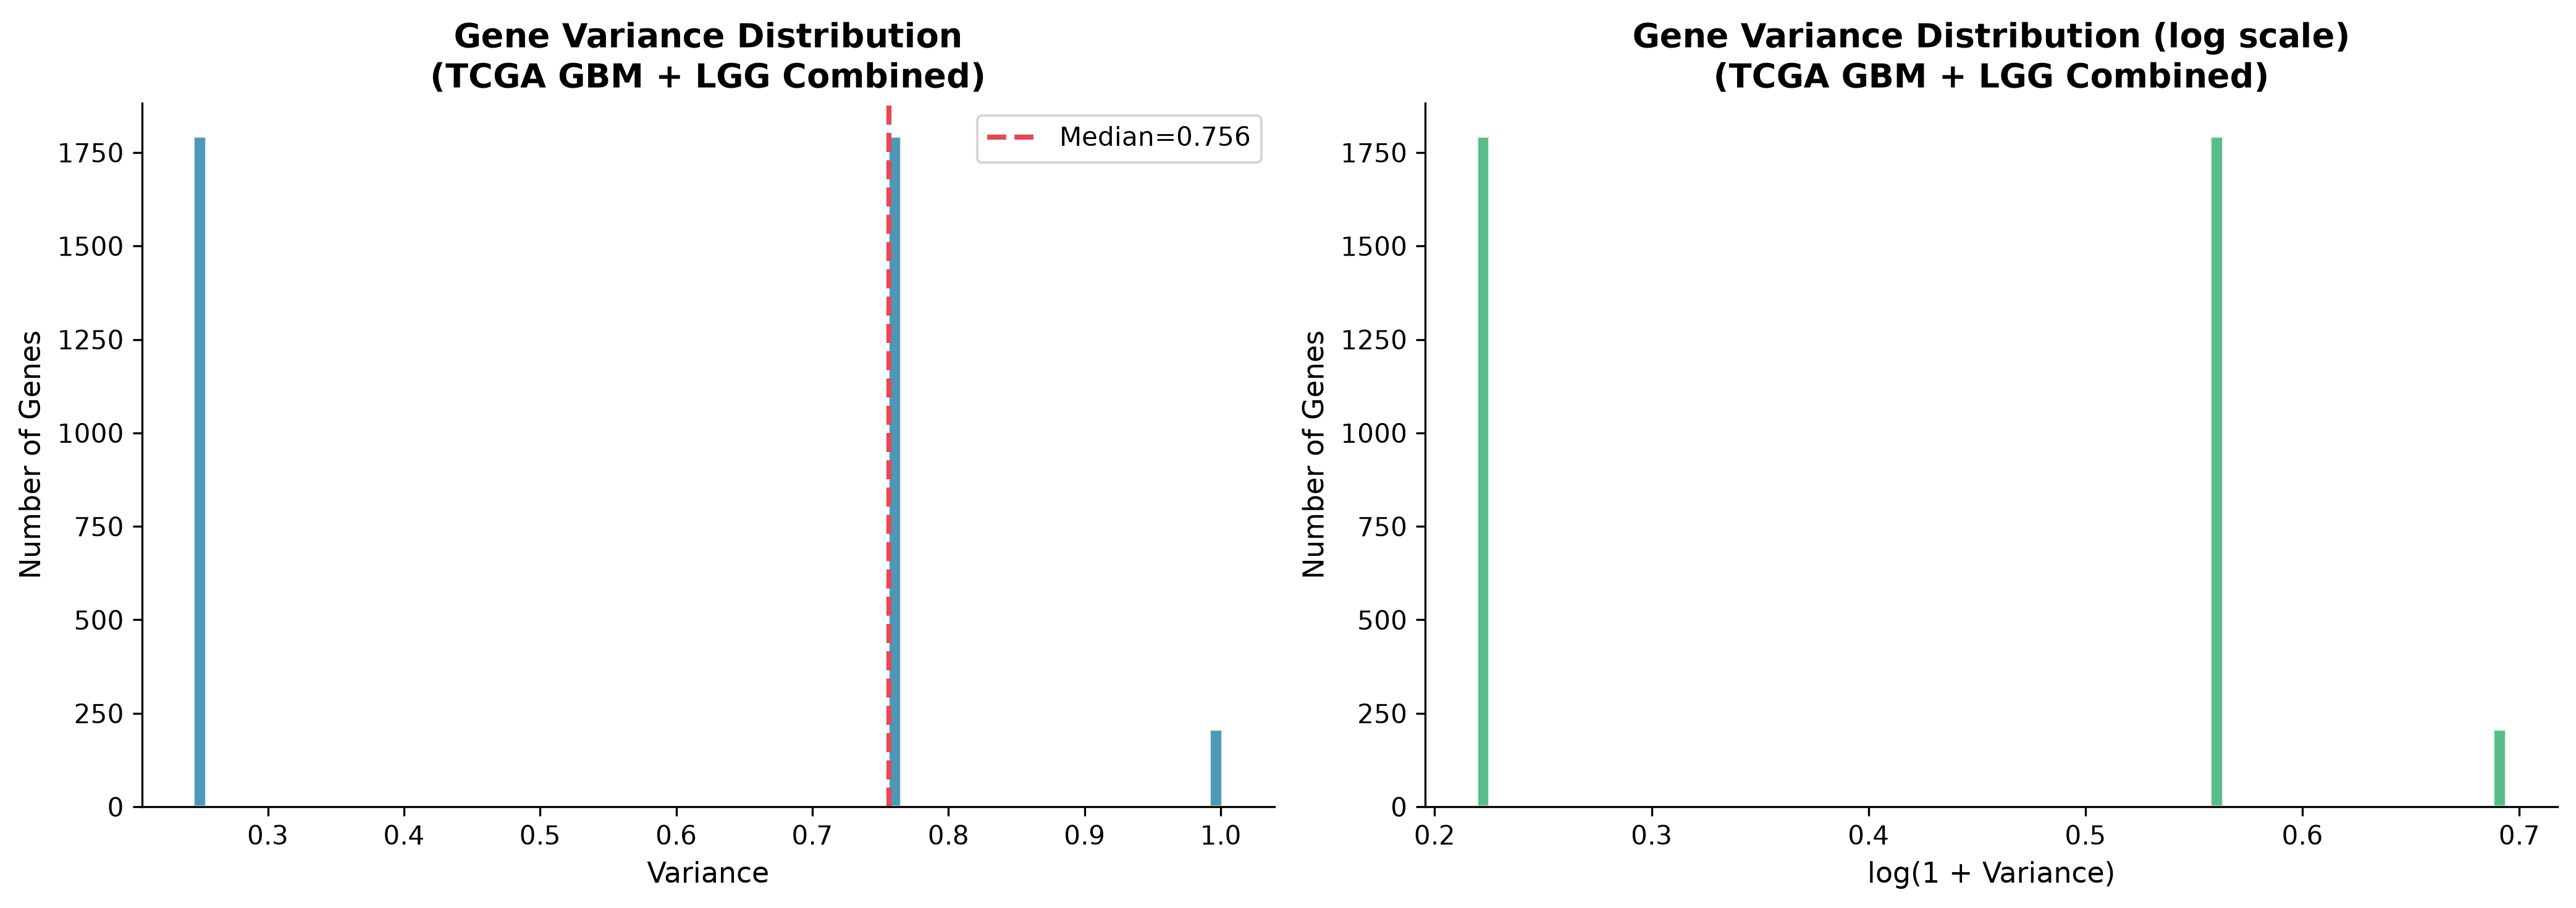

Variance histogram saved.


In [6]:
# 3.2 — Gene Variance Histogram
fig = plot_variance_histogram(
    X_tcga,
    dataset_name="TCGA GBM + LGG Combined",
    save_path=RESULTS_DIR / "01_variance_histogram.png",
    dpi=300,
)
plt.show(); plt.close(fig)
print("Variance histogram saved.")

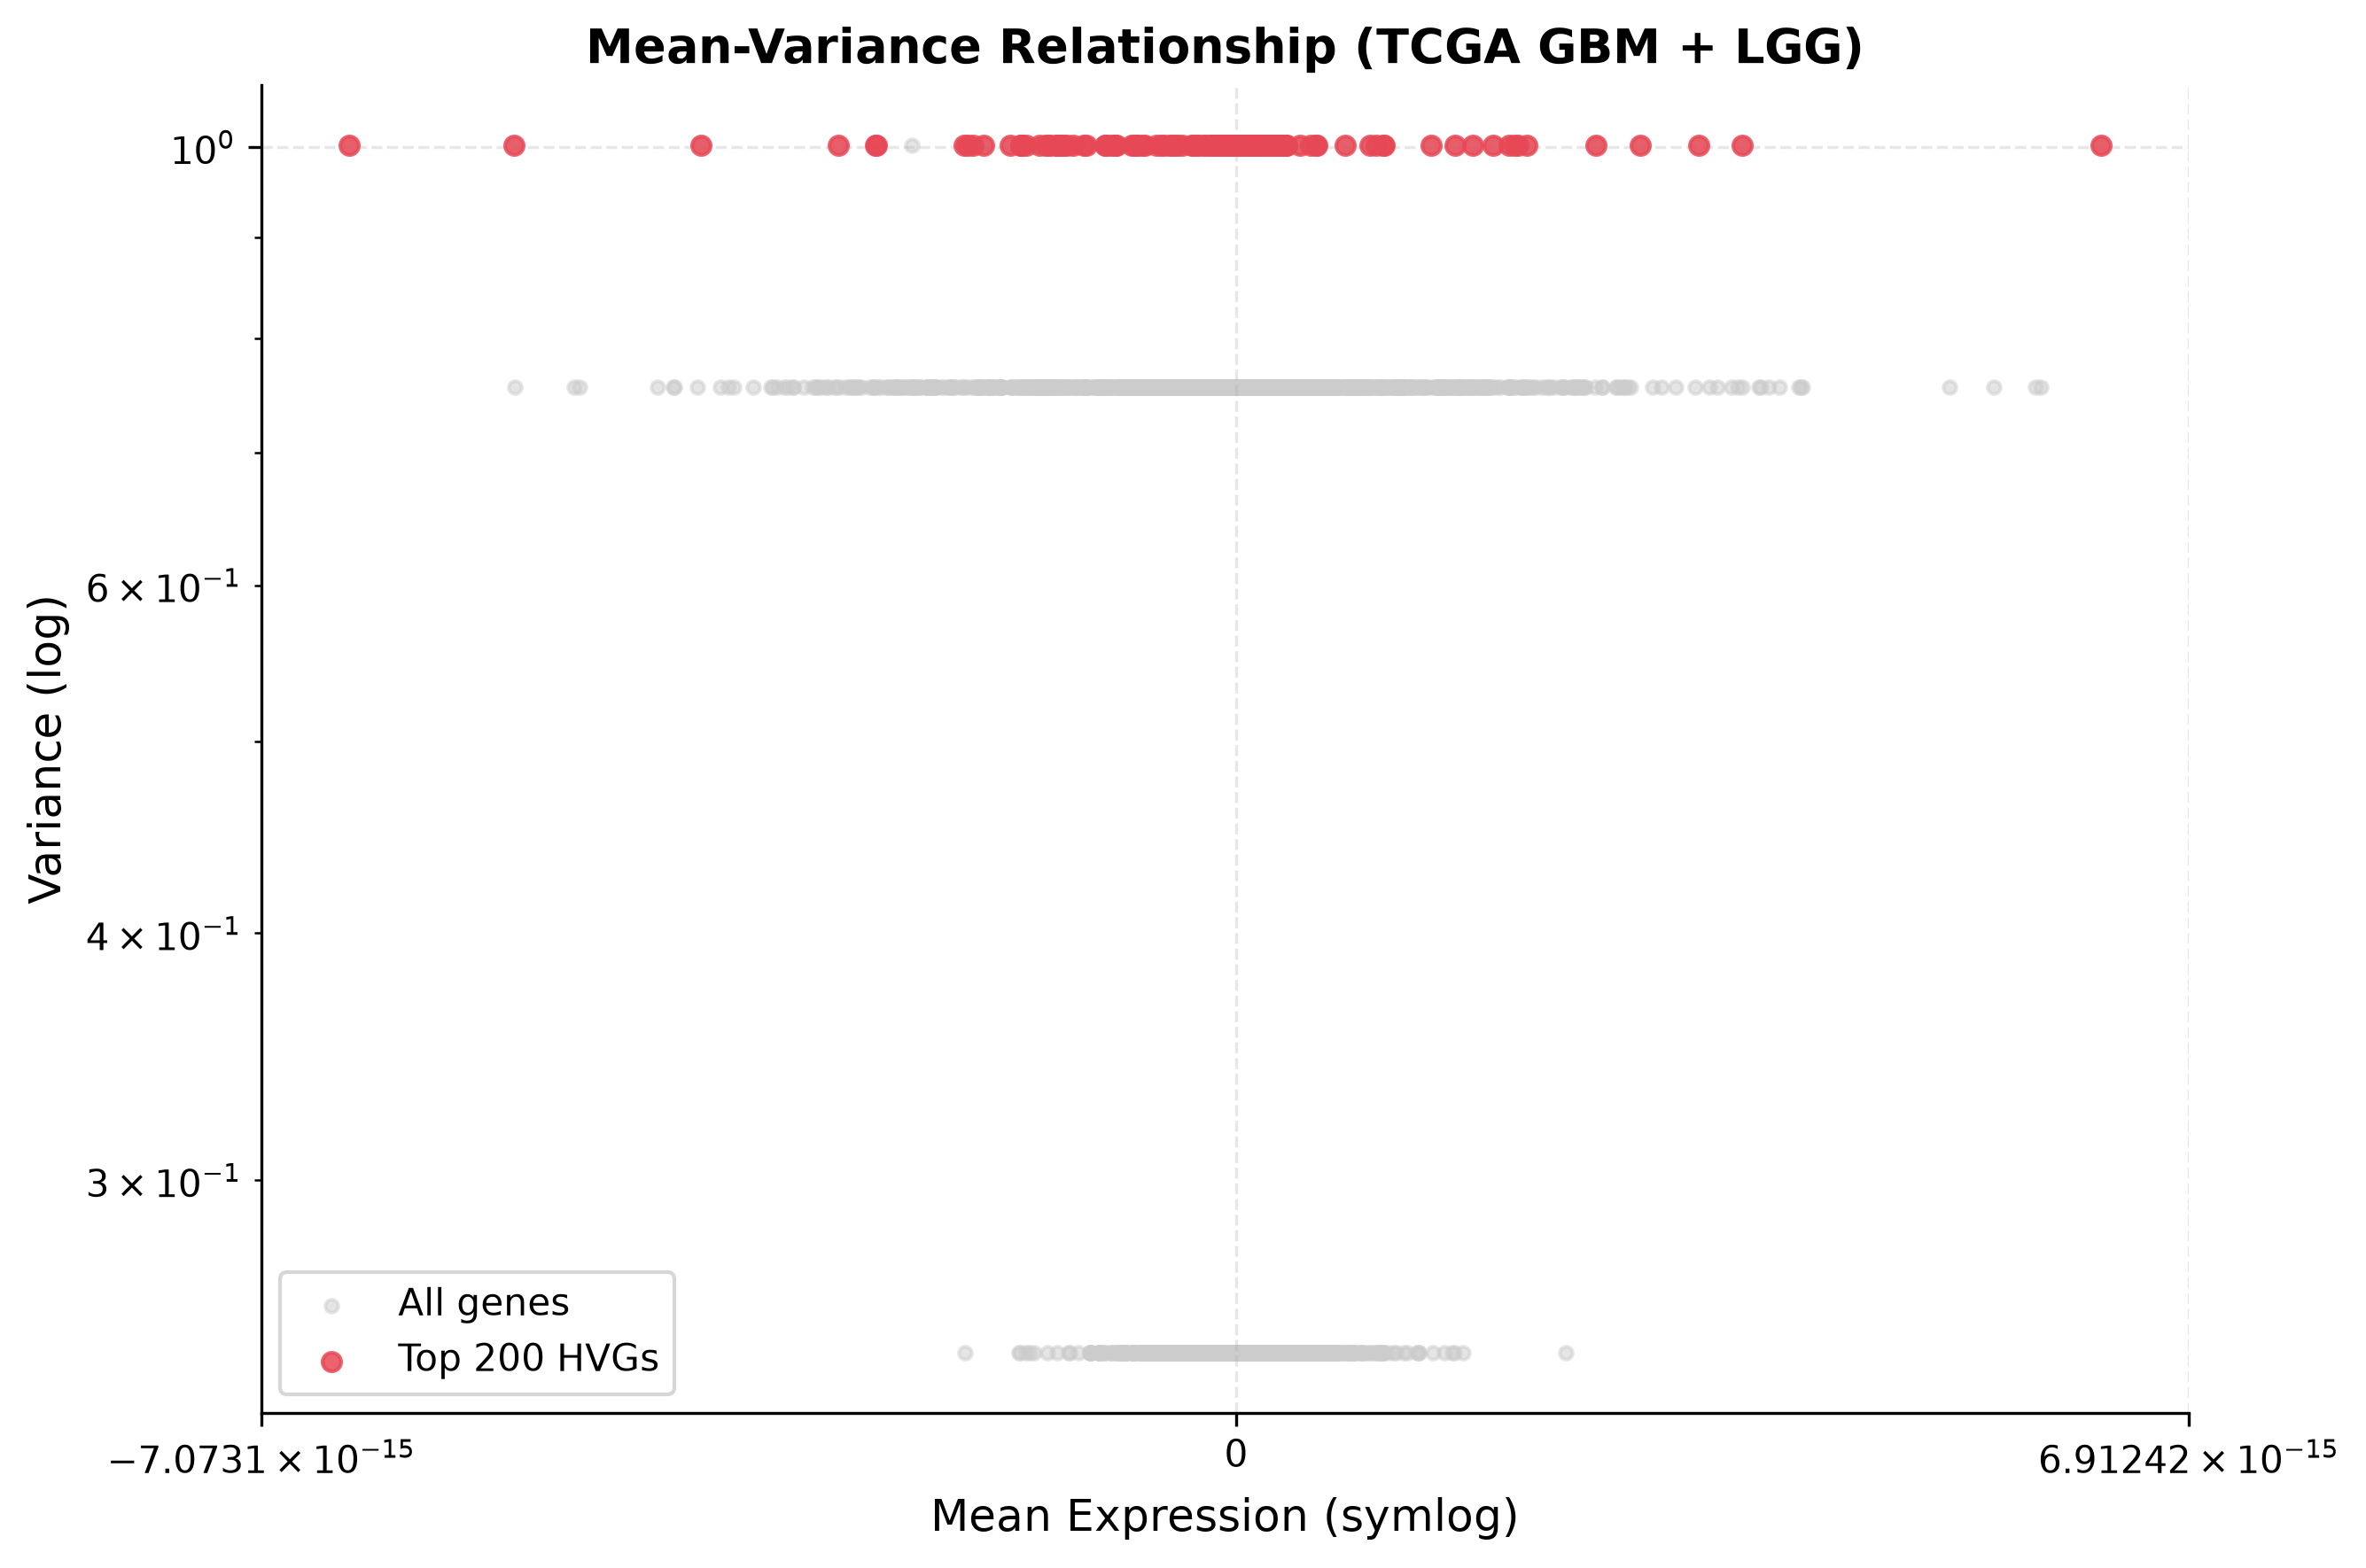

In [7]:
# 3.3 — Mean vs Variance Scatter
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)
top_var_genes = gene_vars.nlargest(200).index
ax.scatter(gene_means, gene_vars, c="#cccccc", s=12, alpha=0.5, label="All genes")
ax.scatter(gene_means[top_var_genes], gene_vars[top_var_genes],
           c="#E84855", s=25, alpha=0.85, zorder=3, label="Top 200 HVGs")
ax.set_xscale("symlog"); ax.set_yscale("log")
ax.set_xlabel("Mean Expression (symlog)", fontsize=12)
ax.set_ylabel("Variance (log)", fontsize=12)
ax.set_title("Mean-Variance Relationship (TCGA GBM + LGG)", fontsize=13, fontweight="bold")
ax.legend(fontsize=10); ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "02_mean_variance_scatter.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

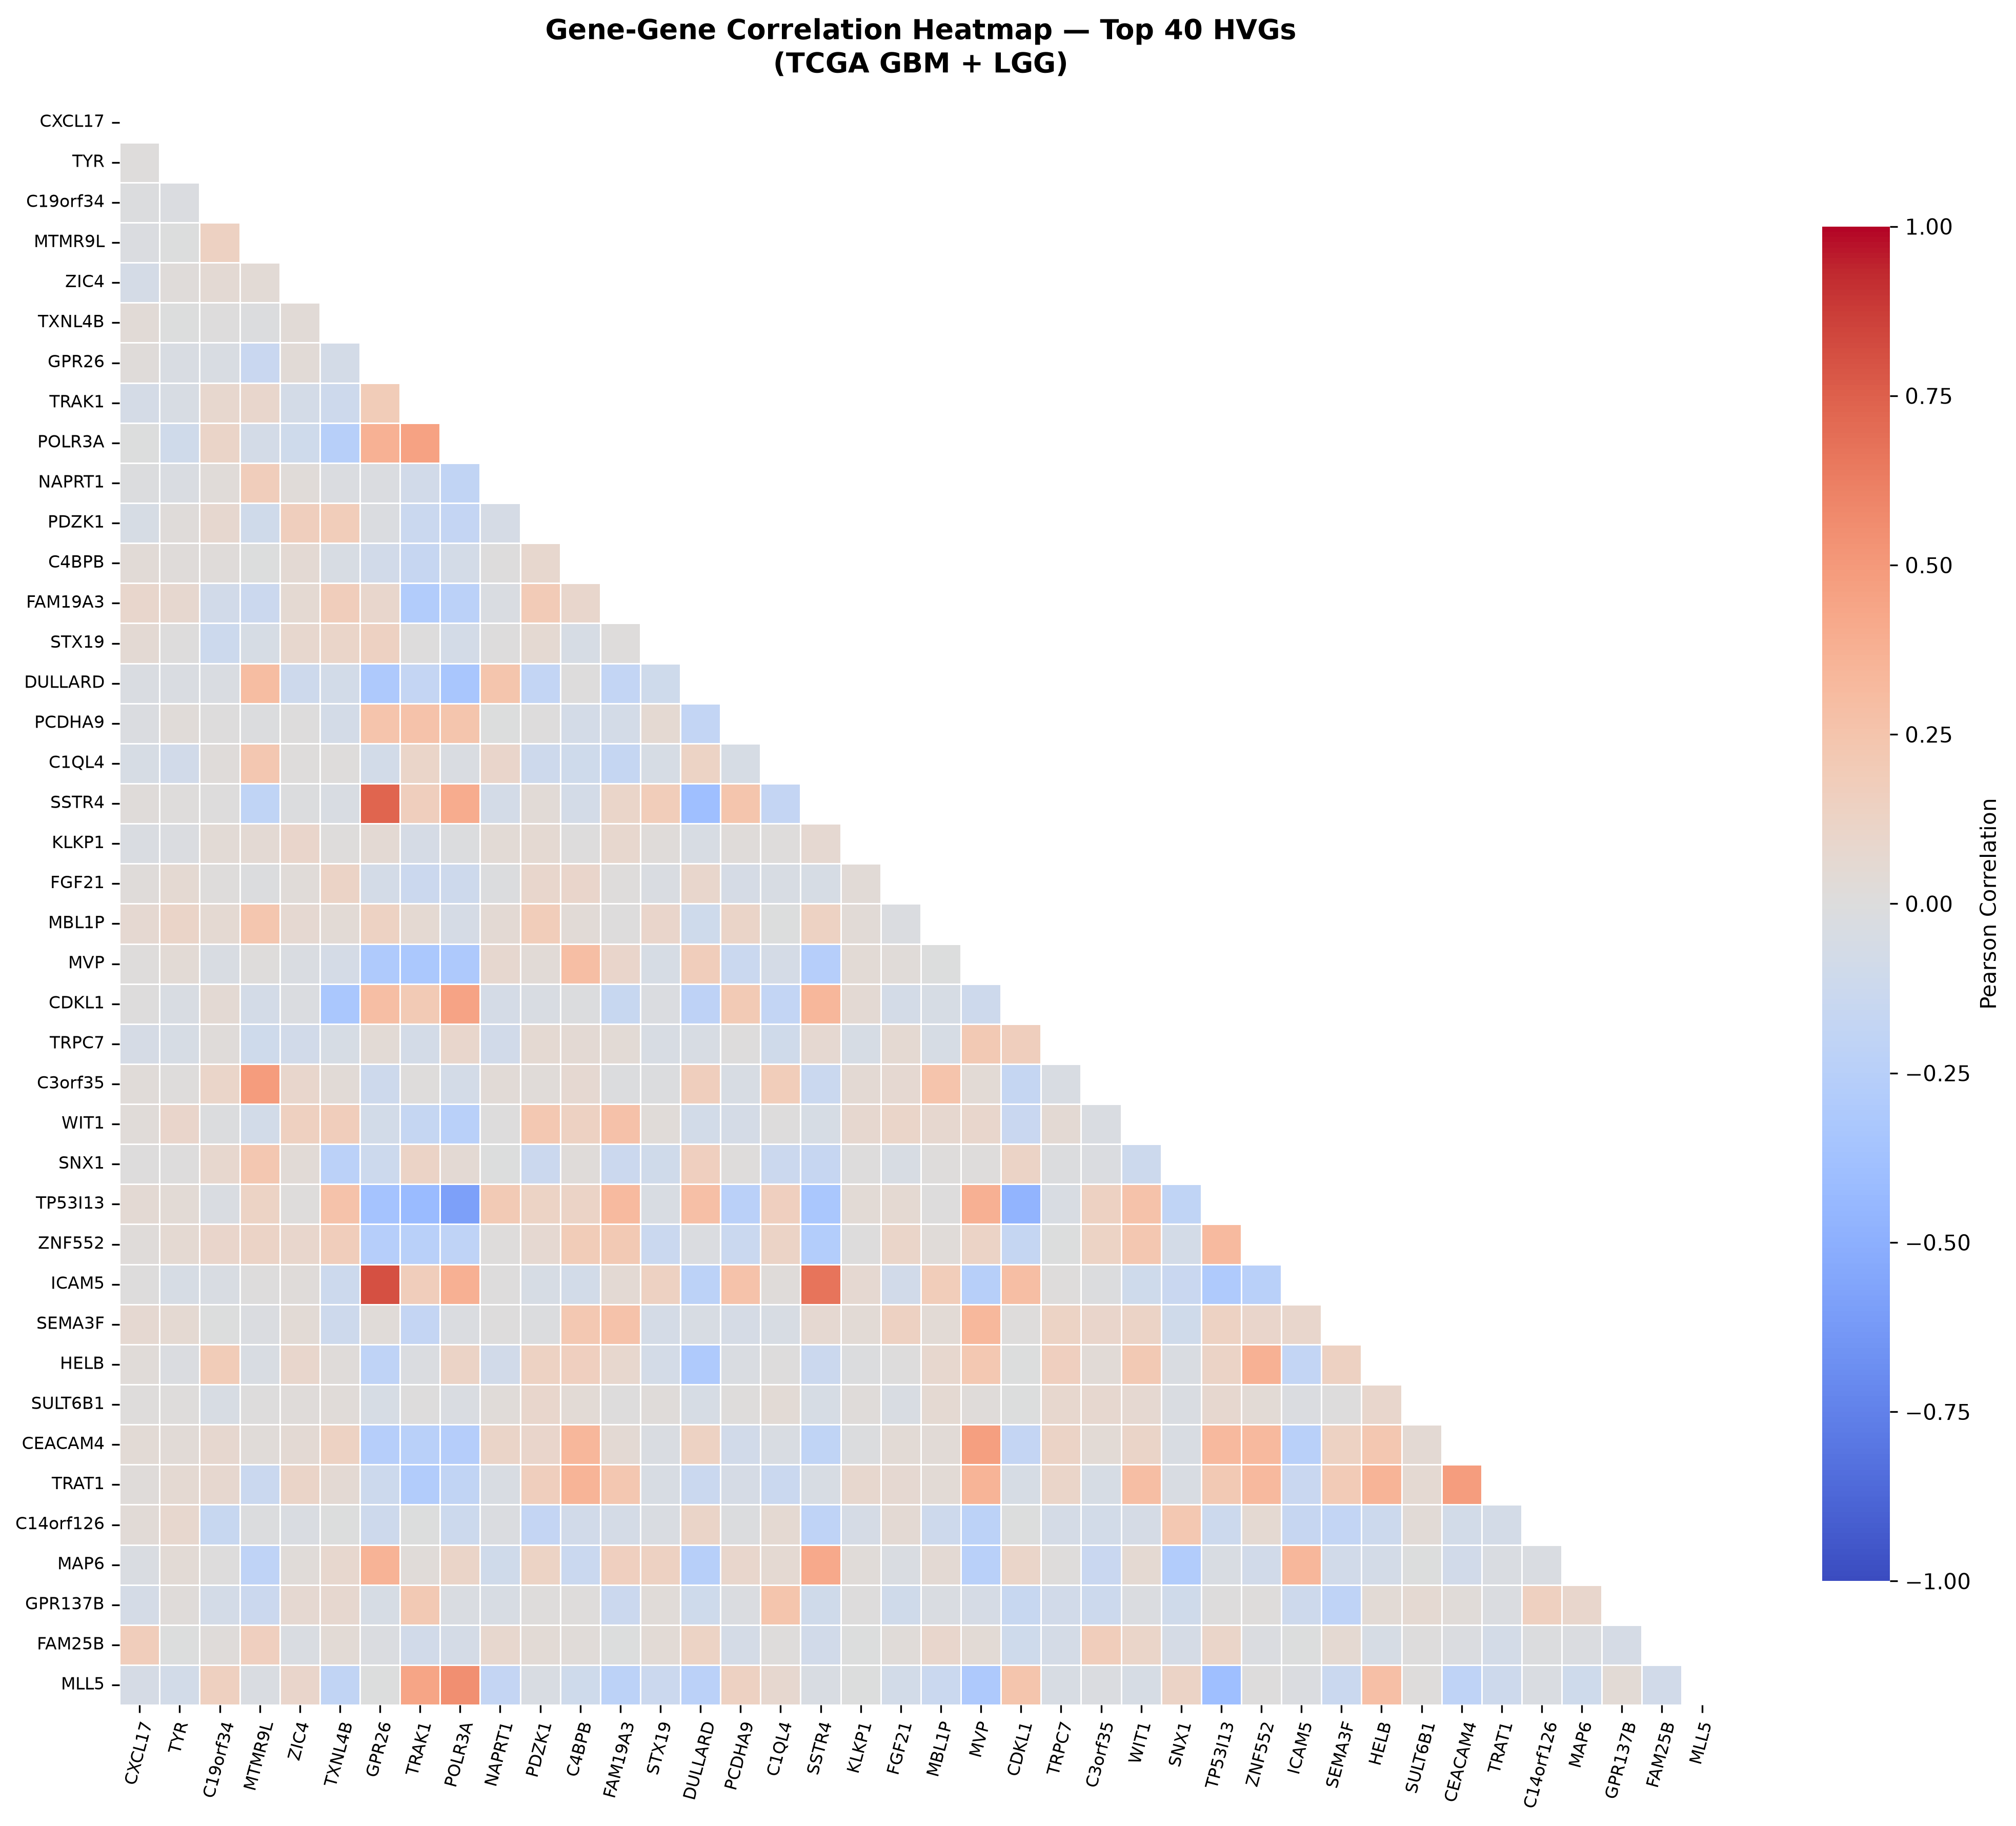

In [8]:
# 3.4 — Correlation Heatmap (Top 40 HVGs)
top40 = gene_vars.nlargest(40).index.tolist()
corr_matrix = X_tcga[top40].corr()
fig, ax = plt.subplots(figsize=(14, 12), dpi=300)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, ax=ax, cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.3,
            cbar_kws={"label": "Pearson Correlation", "shrink": 0.8})
ax.set_title("Gene-Gene Correlation Heatmap — Top 40 HVGs\n(TCGA GBM + LGG)",
             fontsize=13, fontweight="bold", pad=14)
ax.tick_params(axis="x", rotation=75, labelsize=8)
ax.tick_params(axis="y", rotation=0, labelsize=8)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "03_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

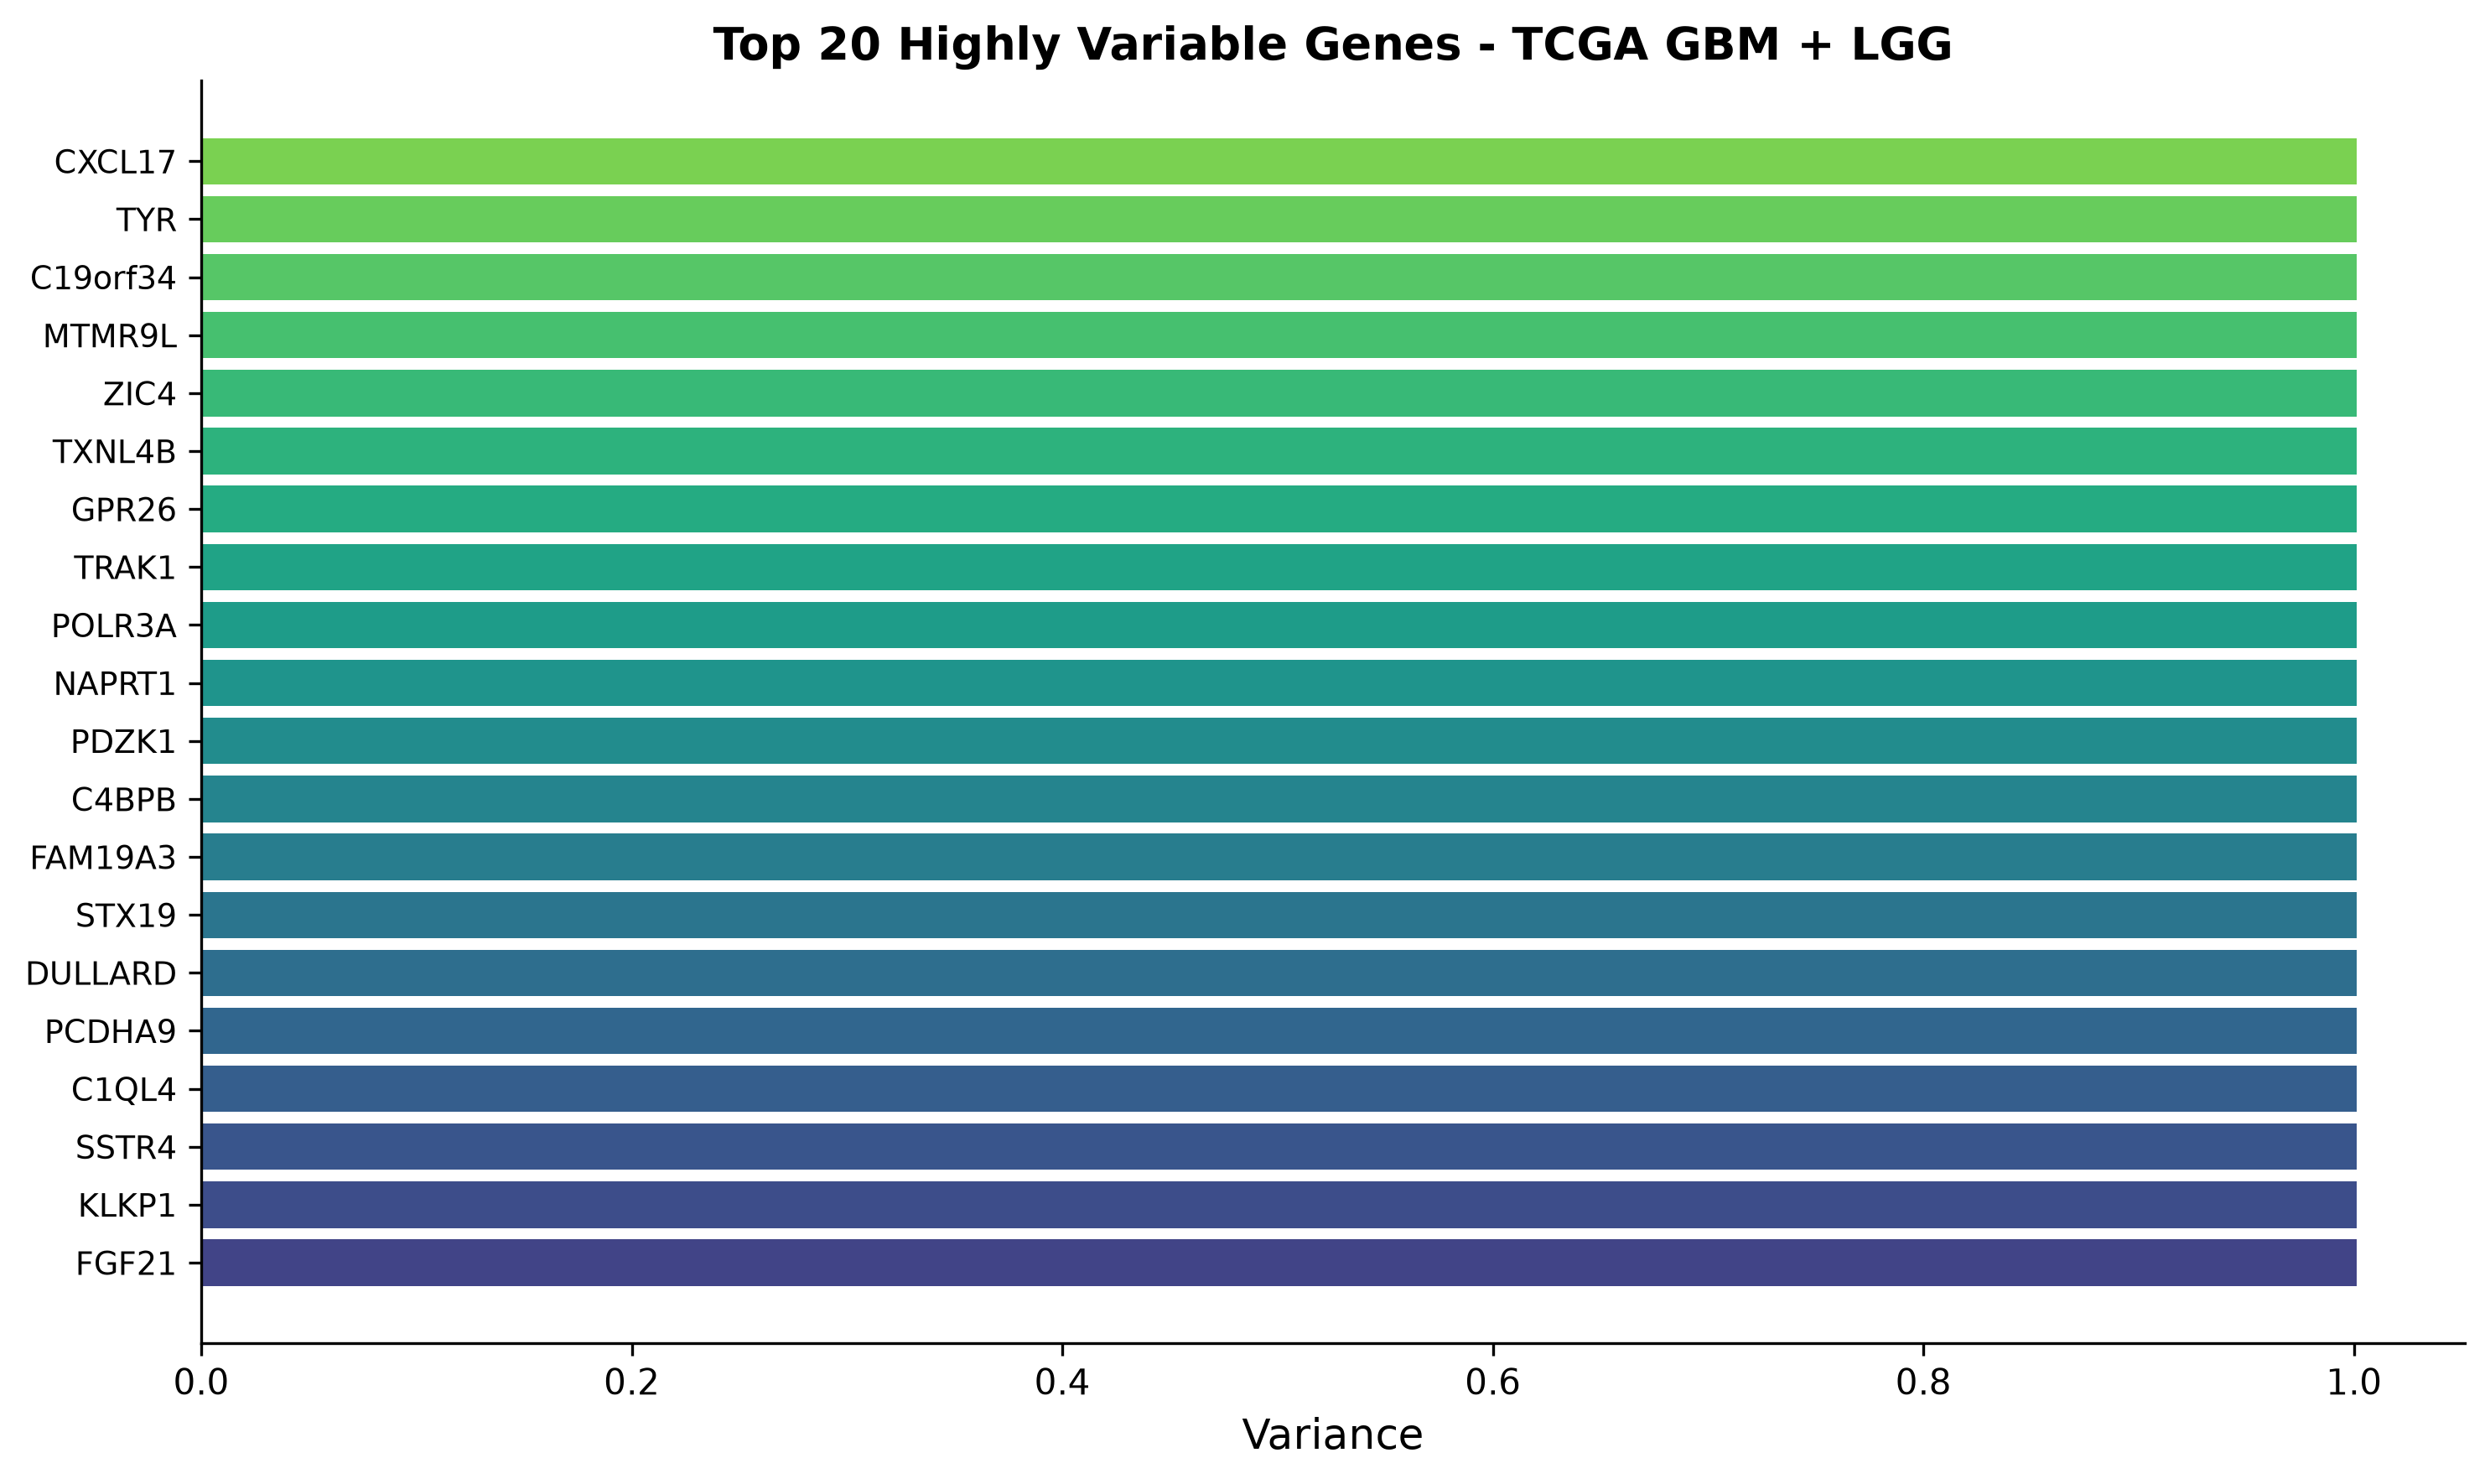

In [9]:
# 3.5 — Top 20 HVG Bar Chart
top20_var = gene_vars.nlargest(20)
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
colors = plt.cm.viridis(np.linspace(0.8, 0.2, 20))
ax.barh(top20_var.index[::-1], top20_var.values[::-1], color=colors[::-1])
ax.set_xlabel("Variance", fontsize=12)
ax.set_title("Top 20 Highly Variable Genes - TCGA GBM + LGG", fontsize=13, fontweight="bold")
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "04_top20_hvg_bar.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

---
## Section 4 — Variance Threshold

VarianceThreshold removes genes whose expression is nearly constant across samples.

> **Formula:** Remove gene $j$ if $\text{Var}(X_j) \leq \tau$

We experiment with $\tau \in \{0.0, 0.05, 0.1, 0.25, 0.5, 1.0\}$.

In [10]:
# 4.1 — Apply Multiple Thresholds
thresholds = [0.0, 0.05, 0.1, 0.25, 0.5, 1.0]
vt_results = apply_variance_threshold(X_tcga, thresholds=thresholds)
vt_summary = variance_threshold_summary(vt_results, original_n=X_tcga.shape[1])
print("Variance Threshold Summary:")
print(vt_summary.to_string(index=False))

2026-09-07 22:57:42 | INFO     | FeatureSelection | VarianceThreshold(0.00): 3793 → 3793 genes


2026-09-07 22:57:42 | INFO     | FeatureSelection | VarianceThreshold(0.05): 3793 → 3793 genes


2026-09-07 22:57:43 | INFO     | FeatureSelection | VarianceThreshold(0.10): 3793 → 3793 genes


2026-09-07 22:57:43 | INFO     | FeatureSelection | VarianceThreshold(0.25): 3793 → 2000 genes


2026-09-07 22:57:43 | INFO     | FeatureSelection | VarianceThreshold(0.50): 3793 → 2000 genes


2026-09-07 22:57:43 | INFO     | FeatureSelection | VarianceThreshold(1.00): 3793 → 174 genes


Variance Threshold Summary:
 Threshold  Genes_Before  Genes_Kept  Genes_Removed  Pct_Kept
      0.00          3793        3793              0     100.0
      0.05          3793        3793              0     100.0
      0.10          3793        3793              0     100.0
      0.25          3793        2000           1793      52.7
      0.50          3793        2000           1793      52.7
      1.00          3793         174           3619       4.6


2026-09-07 22:57:43 | INFO     | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-09-07 22:57:43 | INFO     | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


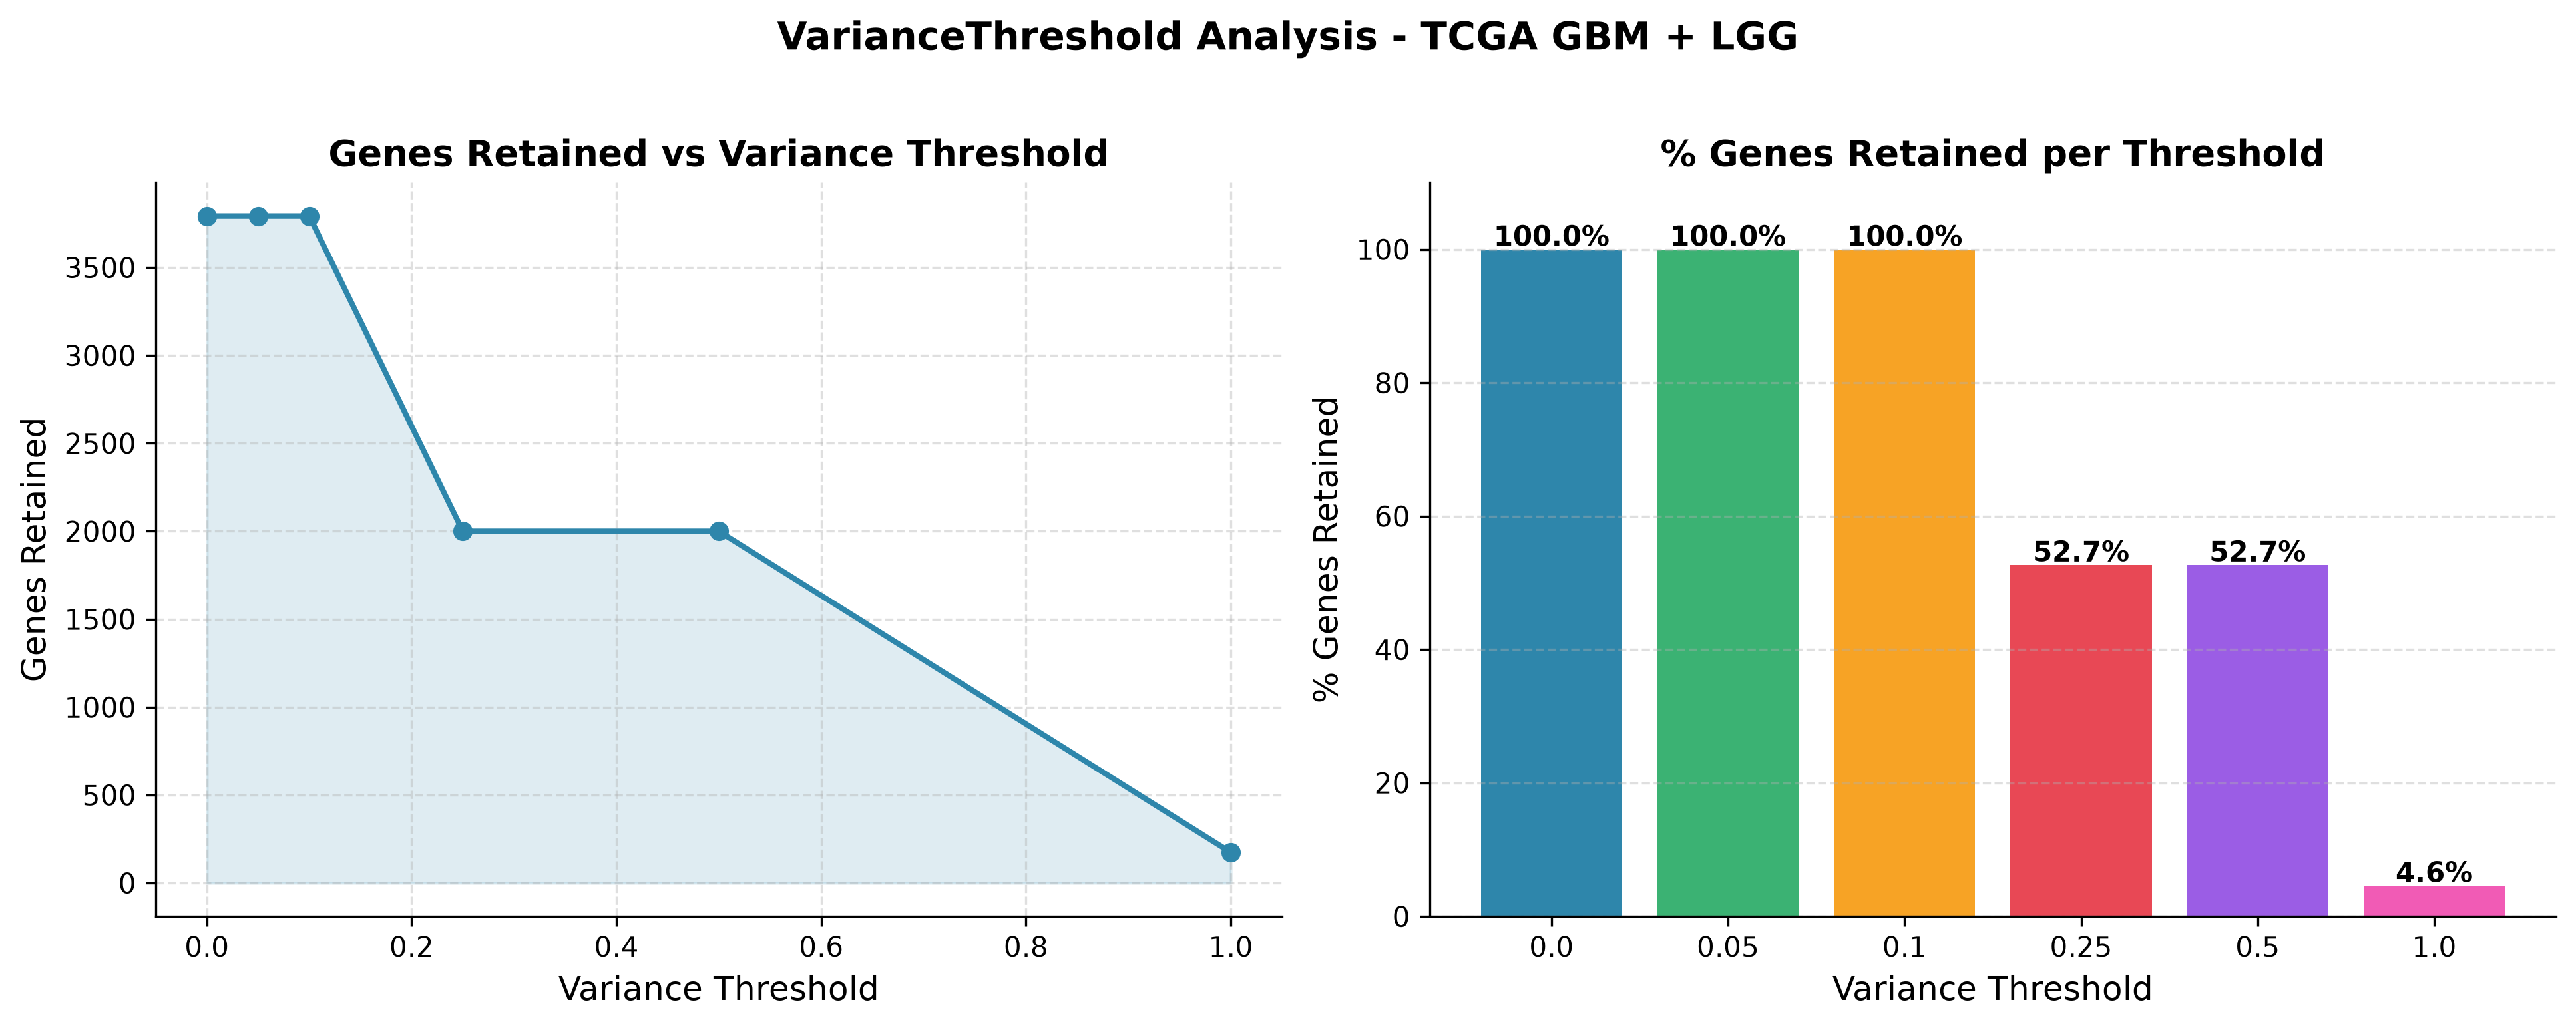

Selected 3793 genes after VarianceThreshold(0.1)


In [11]:
# 4.2 — Before vs After Visualisation
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

axes[0].plot(vt_summary["Threshold"], vt_summary["Genes_Kept"],
             marker="o", lw=2, color="#2E86AB")
axes[0].fill_between(vt_summary["Threshold"], vt_summary["Genes_Kept"],
                     alpha=0.15, color="#2E86AB")
axes[0].set_xlabel("Variance Threshold", fontsize=12)
axes[0].set_ylabel("Genes Retained", fontsize=12)
axes[0].set_title("Genes Retained vs Variance Threshold", fontsize=13, fontweight="bold")
axes[0].grid(True, linestyle="--", alpha=0.4)

palette6 = ["#2E86AB", "#3BB273", "#F7A325", "#E84855", "#9B5DE5", "#F15BB5"]
bars = axes[1].bar([str(t) for t in vt_summary["Threshold"]],
                   vt_summary["Pct_Kept"], color=palette6)
for bar, pct in zip(bars, vt_summary["Pct_Kept"]):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                 f"{pct:.1f}%", ha="center", fontsize=10, fontweight="bold")
axes[1].set_xlabel("Variance Threshold", fontsize=12)
axes[1].set_ylabel("% Genes Retained", fontsize=12)
axes[1].set_title("% Genes Retained per Threshold", fontsize=13, fontweight="bold")
axes[1].set_ylim(0, 110)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.suptitle("VarianceThreshold Analysis - TCGA GBM + LGG",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "05_variance_threshold_comparison.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

vt_selected = vt_results[0.1].columns.tolist()
print(f"Selected {len(vt_selected)} genes after VarianceThreshold(0.1)")

---
## Section 5 — ANOVA F-Test (SelectKBest)

The ANOVA F-statistic measures how strongly a gene's mean expression differs across tumour classes.

> $$F = \frac{MS_{\text{between}}}{MS_{\text{within}}}$$  
> Large $F$ → gene strongly discriminates between tumour types.

In [12]:
# 5.1 — ANOVA Ranking
print("Running ANOVA F-Test on TCGA Combined ...")
anova_df, anova_topk = anova_ftest_ranking(X_tcga, y_tcga, k_values=[50, 100, 250, 500])
print("\nTop 15 Genes by ANOVA F-Score:")
print(anova_df.head(15)[["Gene", "F_Score", "P_Value", "Rank_ANOVA"]].to_string(index=False))

2026-09-07 22:57:44 | INFO     | FeatureSelection | ANOVA F-Test ranking complete. Top gene: CFL1 (F=0.00)


Running ANOVA F-Test on TCGA Combined ...

Top 15 Genes by ANOVA F-Score:
   Gene      F_Score  P_Value  Rank_ANOVA
   CFL1 5.035849e-26      1.0           1
 EIF2B1 3.392219e-26      1.0           2
  MTCH1 2.409956e-26      1.0           3
 VPS33A 2.203676e-26      1.0           4
CDK2AP1 2.175297e-26      1.0           5
 CHCHD3 2.163767e-26      1.0           6
 CHMP1B 2.161585e-26      1.0           7
    TKT 2.039443e-26      1.0           8
 TUBB2C 2.001057e-26      1.0           9
 ZNF561 1.975531e-26      1.0          10
   NFS1 1.889312e-26      1.0          11
   PLD3 1.788508e-26      1.0          12
  CHD1L 1.650576e-26      1.0          13
   IRF3 1.549235e-26      1.0          14
  TM2D3 1.520922e-26      1.0          15


2026-09-07 22:57:44 | INFO     | FeatureSelection | Saved ANOVA bar chart → C:\Research_Project\Brain_Tumor_Project\results\feature_selection\06_anova_top20.png


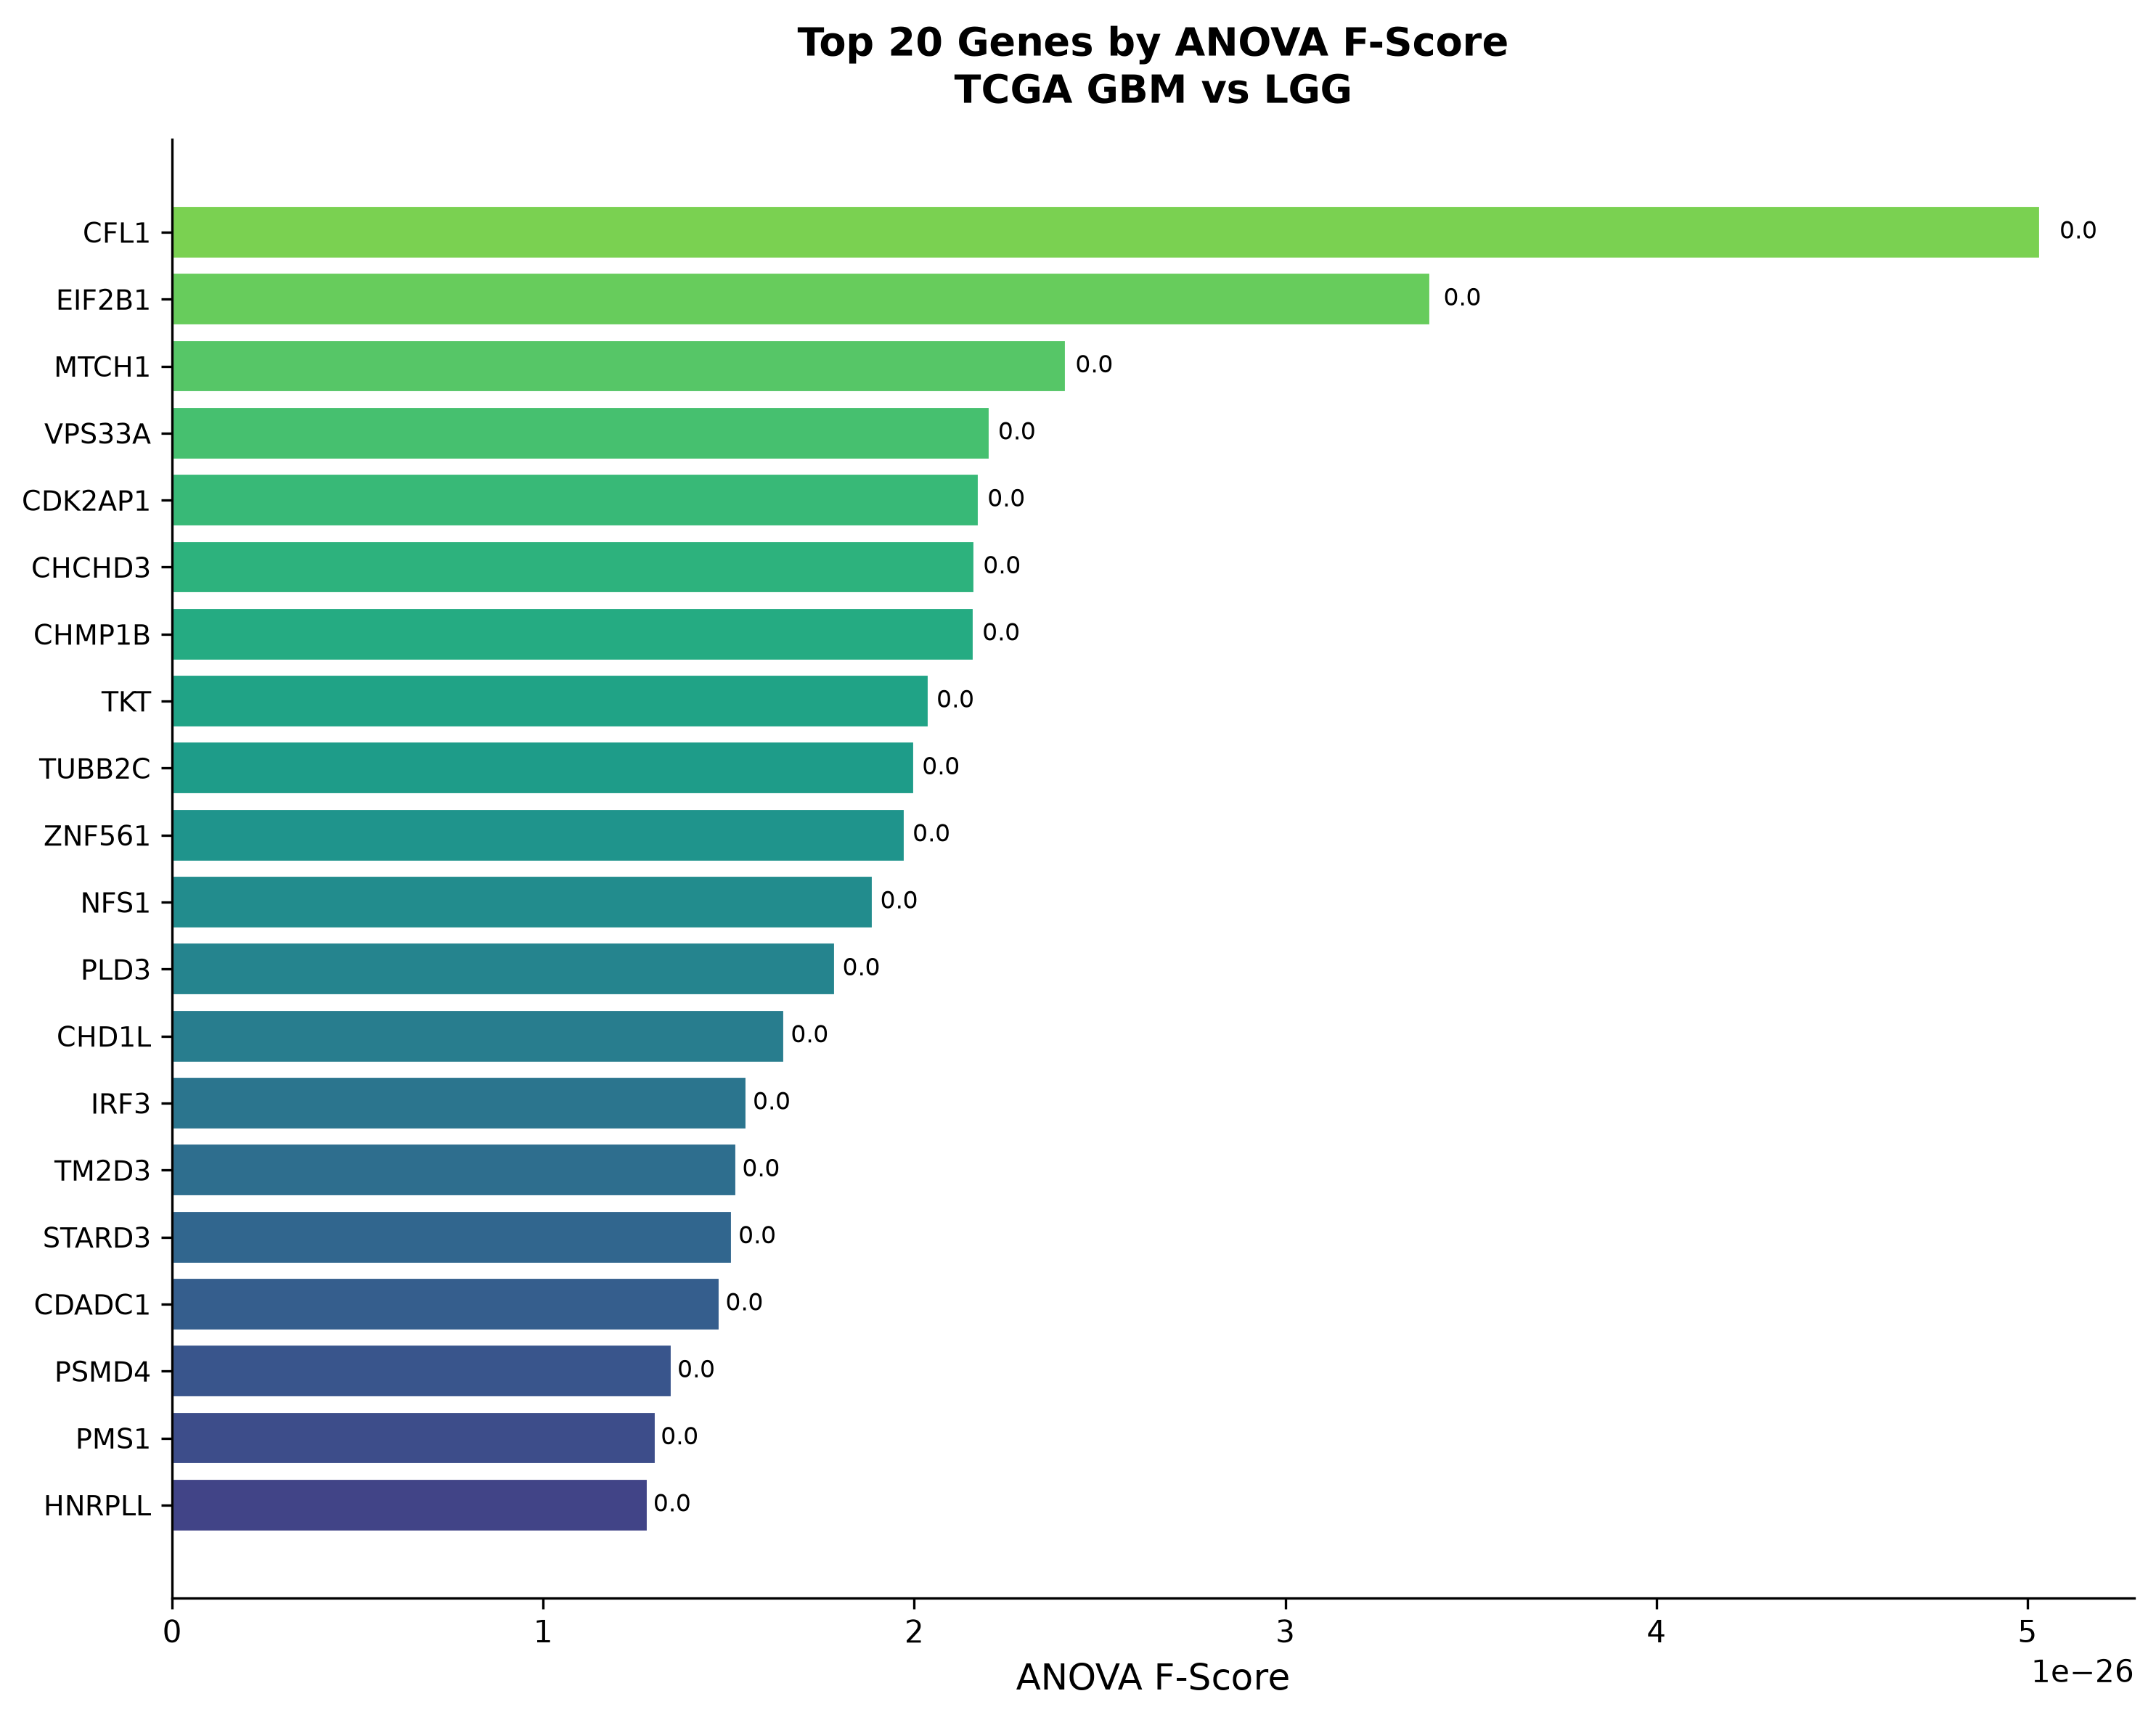


ANOVA Top-K gene counts:
  Top-  50: ['CFL1', 'EIF2B1', 'MTCH1', 'VPS33A', 'CDK2AP1'] ...
  Top- 100: ['CFL1', 'EIF2B1', 'MTCH1', 'VPS33A', 'CDK2AP1'] ...
  Top- 250: ['CFL1', 'EIF2B1', 'MTCH1', 'VPS33A', 'CDK2AP1'] ...
  Top- 500: ['CFL1', 'EIF2B1', 'MTCH1', 'VPS33A', 'CDK2AP1'] ...


In [13]:
# 5.2 — ANOVA Bar Chart
fig = plot_anova_bar(anova_df, top_n=20, dataset_name="TCGA GBM vs LGG",
                     save_path=RESULTS_DIR / "06_anova_top20.png", dpi=300)
plt.show(); plt.close(fig)

print("\nANOVA Top-K gene counts:")
for k, genes in anova_topk.items():
    print(f"  Top-{k:4d}: {genes[:5]} ...")

In [14]:
# 5.3 — ANOVA on CGGA (3-class)
print("Running ANOVA on CGGA (3-class Grade)...")
anova_cgga_df, anova_cgga_topk = anova_ftest_ranking(X_cgga, y_cgga, k_values=[50, 100, 250, 500])
print("Top 10 CGGA ANOVA genes:")
print(anova_cgga_df.head(10)[["Gene", "F_Score", "Rank_ANOVA"]].to_string(index=False))

2026-09-07 22:57:44 | INFO     | FeatureSelection | ANOVA F-Test ranking complete. Top gene: MYL12A (F=80.22)


Running ANOVA on CGGA (3-class Grade)...
Top 10 CGGA ANOVA genes:
     Gene   F_Score  Rank_ANOVA
   MYL12A 80.218704           1
     EMP3 76.353136           2
    ALDH2 74.761928           3
    TEAD3 70.757675           4
  S100A11 68.747487           5
   IFNGR2 67.961779           6
LINC00152 67.435399           7
   IGFBP2 63.994331           8
    RAB42 63.414010           9
    CEP89 63.013115          10


---
## Section 6 — Mutual Information

Mutual Information captures non-linear dependencies between gene expression and class labels.

> $$MI(X_j; Y) = \sum_{y} \sum_{x_j} P(x_j, y) \log \frac{P(x_j, y)}{P(x_j) P(y)}$$  
> MI = 0 → statistical independence; higher MI → stronger dependency.

In [15]:
# 6.1 — MI Ranking
print("Computing Mutual Information on TCGA Combined (may take ~30s) ...")
mi_df = mutual_info_ranking(X_tcga, y_tcga, random_state=42)
print("\nTop 15 Genes by MI Score:")
print(mi_df.head(15)[["Gene", "MI_Score", "Rank_MI"]].to_string(index=False))

Computing Mutual Information on TCGA Combined (may take ~30s) ...


2026-09-07 22:57:55 | INFO     | FeatureSelection | Mutual Information ranking complete. Top gene: DNAJC25-GNG10 (MI=0.5582)



Top 15 Genes by MI Score:
         Gene  MI_Score  Rank_MI
DNAJC25-GNG10  0.558216        1
       SPRR2F  0.558216        2
        KRT84  0.558216        3
        OR5B3  0.558216        4
       TMIGD1  0.557504        5
         MSMB  0.557504        6
      C3orf77  0.557504        7
        DDX53  0.557504        8
        AMPD1  0.557504        9
        STK40  0.557504       10
    LOC402644  0.557504       11
      GLYATL3  0.557504       12
      SNORD89  0.557504       13
     SCARNA11  0.557504       14
       FBXO31  0.557504       15


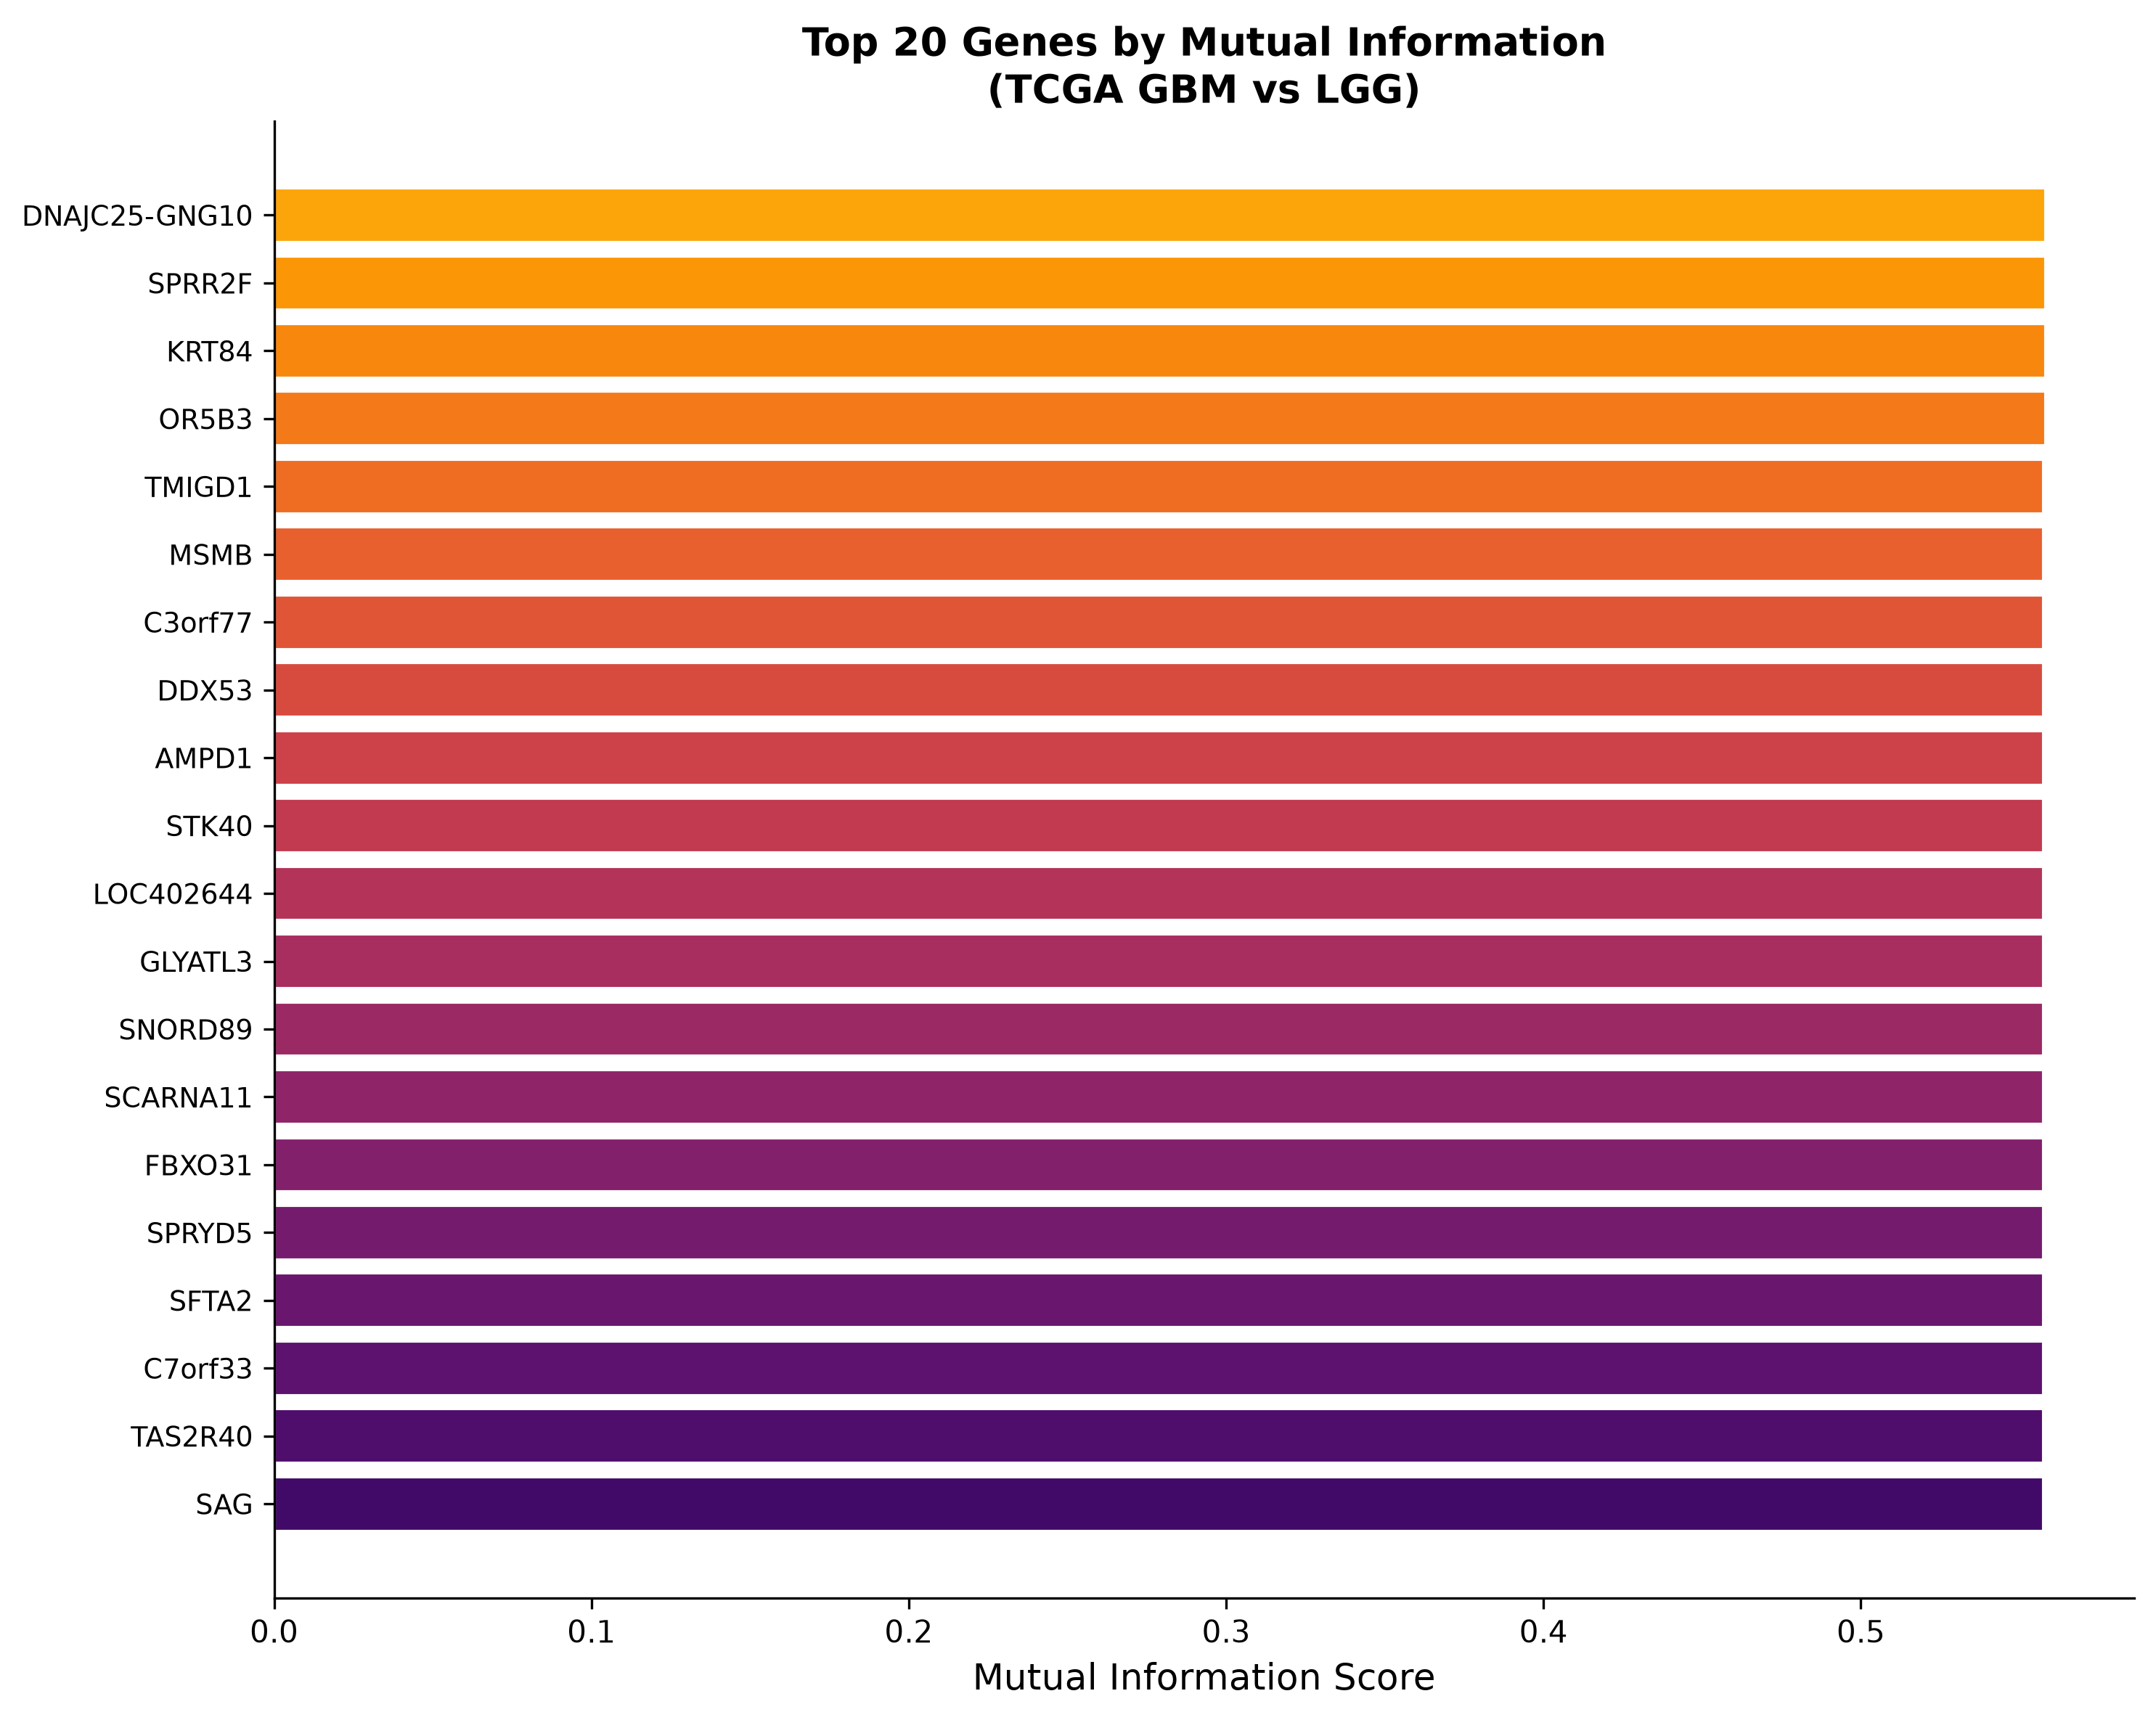

In [16]:
# 6.2 — MI Bar Chart
top20_mi = mi_df.head(20)
fig, ax = plt.subplots(figsize=(10, 8), dpi=300)
colors = plt.cm.inferno(np.linspace(0.8, 0.2, 20))
ax.barh(top20_mi["Gene"][::-1], top20_mi["MI_Score"][::-1], color=colors[::-1], edgecolor="white")
ax.set_xlabel("Mutual Information Score", fontsize=12)
ax.set_title("Top 20 Genes by Mutual Information\n(TCGA GBM vs LGG)", fontsize=13, fontweight="bold")
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "07_mi_top20.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

In [17]:
# 6.3 — ANOVA vs MI Overlap (Top 100)
overlap_df = anova_mi_overlap(anova_df, mi_df, top_n=100)
print(f"ANOVA-MI Overlap (top 100): {overlap_df['In_Both'].sum()} genes in both")
shared = overlap_df[overlap_df["In_Both"]][["Gene", "F_Score", "MI_Score"]]
print(shared.head(20).to_string(index=False))

ANOVA-MI Overlap (top 100): 1 genes in both
Gene      F_Score  MI_Score
NFS1 1.889312e-26  0.557504


---
## Section 7 — LASSO Feature Selection (L1 Regularisation)

LASSO applies an L1 penalty to logistic regression coefficients:

> $$\min_{\beta} \; \mathcal{L}(\beta) + \frac{1}{C} \sum_{j=1}^{p} |\beta_j|$$

The L1 penalty drives uninformative gene coefficients **exactly to zero**.

In [18]:
# 7.1 — Standardise then LASSO
scaler = StandardScaler()
X_tcga_scaled = pd.DataFrame(scaler.fit_transform(X_tcga),
                              index=X_tcga.index, columns=X_tcga.columns)

print("Fitting LASSO (L1) Logistic Regression — C=0.01 ...")
lasso_coef_df, lasso_selected = lasso_feature_selection(
    X_tcga_scaled, y_tcga, C=0.01, max_iter=5000, random_state=42
)
print(f"\nLASSO selected {len(lasso_selected)} genes")
print("Top 15 LASSO genes:")
print(lasso_coef_df.head(15).to_string(index=False))

Fitting LASSO (L1) Logistic Regression — C=0.01 ...


2026-09-07 22:57:56 | INFO     | FeatureSelection | LASSO selected 0 / 3793 genes (C=0.0100)



LASSO selected 0 genes
Top 15 LASSO genes:
     Gene  MaxAbsCoef  Selected
LOC728743         0.0     False
    PRELP         0.0     False
  CYP27A1         0.0     False
     LCN6         0.0     False
    EPB42         0.0     False
    TOP3B         0.0     False
    WDR67         0.0     False
   MAN1B1         0.0     False
    KRT84         0.0     False
     ADIG         0.0     False
     NELF         0.0     False
     QPRT         0.0     False
   MRPS36         0.0     False
 PHOSPHO1         0.0     False
 PLEKHM1P         0.0     False


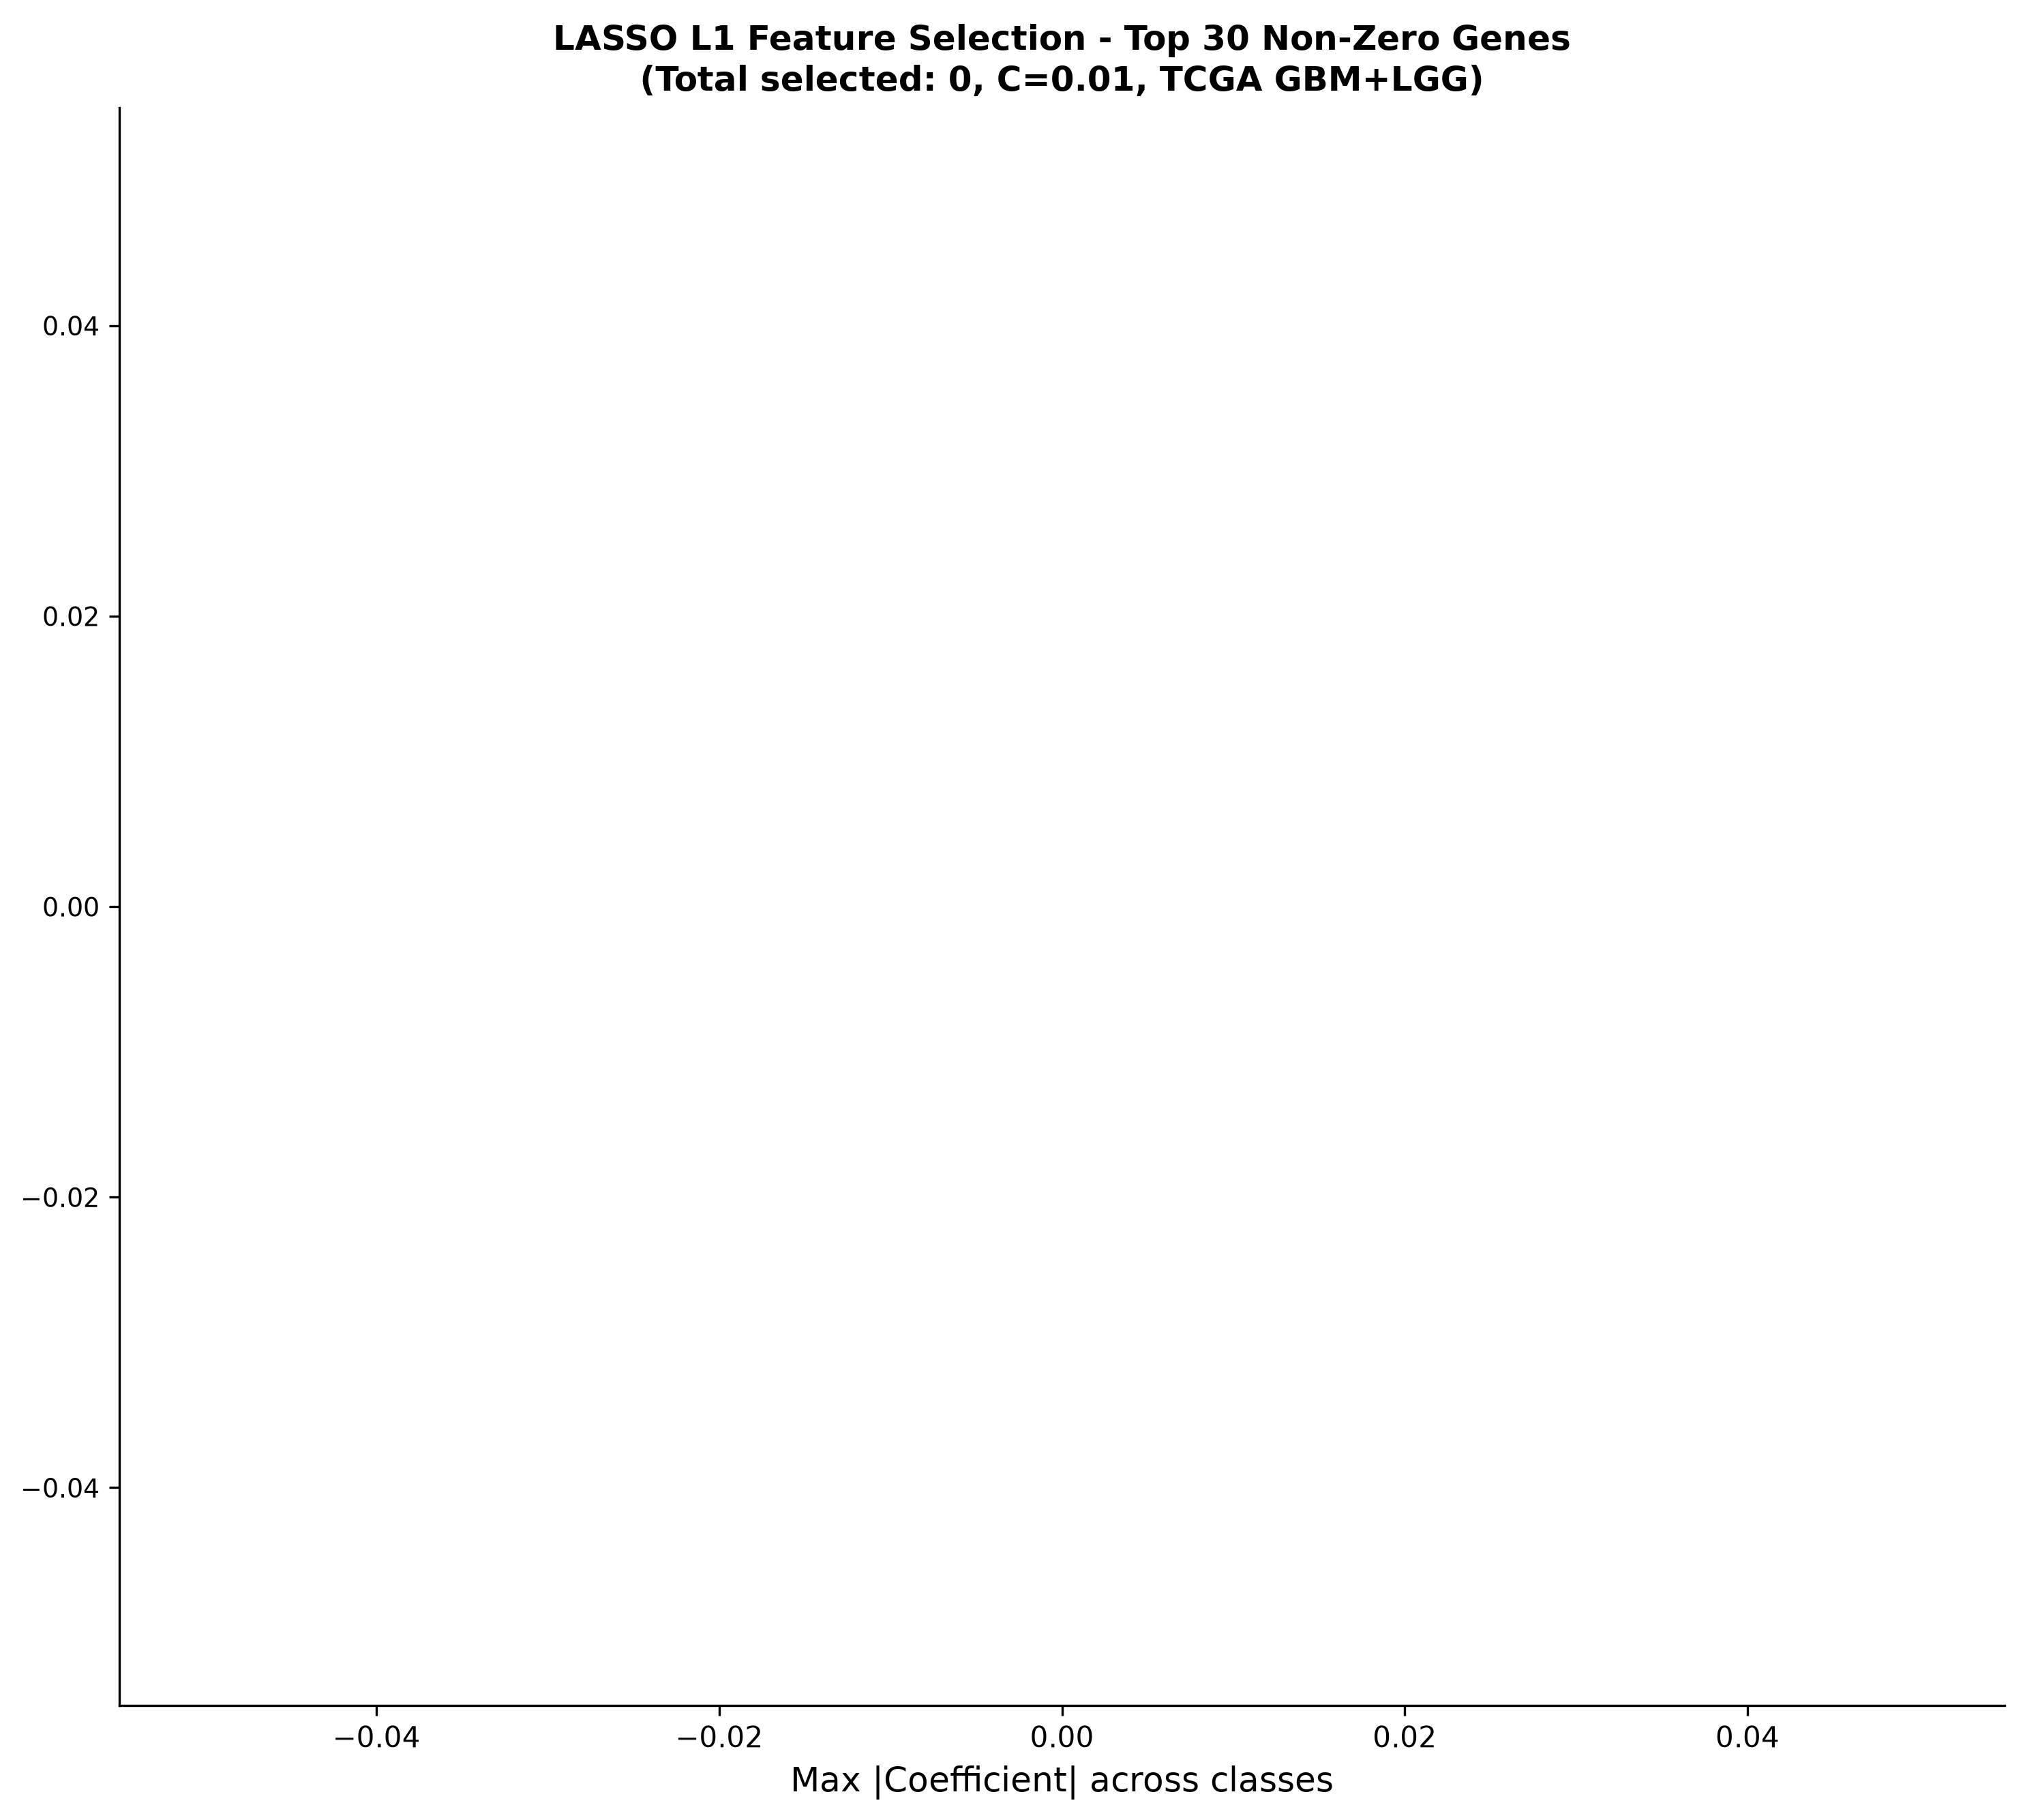

In [19]:
# 7.2 — LASSO Coefficient Plot
top_lasso = lasso_coef_df[lasso_coef_df["Selected"]].head(30)
fig, ax = plt.subplots(figsize=(10, 9), dpi=300)
colors_l = plt.cm.Reds(np.linspace(0.4, 0.9, len(top_lasso)))
ax.barh(top_lasso["Gene"][::-1], top_lasso["MaxAbsCoef"][::-1],
        color=colors_l[::-1], edgecolor="white")
ax.set_xlabel("Max |Coefficient| across classes", fontsize=12)
ax.set_title(
    f"LASSO L1 Feature Selection - Top 30 Non-Zero Genes\n"
    f"(Total selected: {len(lasso_selected)}, C=0.01, TCGA GBM+LGG)",
    fontsize=12, fontweight="bold"
)
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "08_lasso_coefficients.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

---
## Section 8 — Random Forest Feature Importance

A Random Forest ensemble measures importance via average **Gini Impurity Reduction**
contributed by each gene across all trees.

> **Advantage:** Captures non-linear and interaction effects.  
> **Limitation:** Can be biased towards continuous high-cardinality features.

In [20]:
# 8.1 — Train Random Forest
print("Training Random Forest (300 trees) on TCGA Combined ...")
rf_df, rf_model = random_forest_importance(X_tcga, y_tcga, n_estimators=300, random_state=42, top_n=30)
print("\nTop 15 genes by RF Gini Importance:")
print(rf_df.head(15)[["Gene", "RF_Importance", "RF_Rank"]].to_string(index=False))

Training Random Forest (300 trees) on TCGA Combined ...


2026-09-07 22:57:57 | INFO     | FeatureSelection | Random Forest importance: top gene = OR13D1 (0.02482)



Top 15 genes by RF Gini Importance:
     Gene  RF_Importance  RF_Rank
   OR13D1       0.024818        1
  AKR1CL1       0.024139        2
    TTLL8       0.019892        3
   OR6W1P       0.018722        4
    PDILT       0.016104        5
LOC646498       0.016051        6
    H1FOO       0.015852        7
    OR1L1       0.015779        8
  DEFB125       0.015621        9
    NLRP5       0.015334       10
C20orf191       0.015147       11
    OR2S2       0.015109       12
    GNGT1       0.014076       13
   OR51Q1       0.013109       14
   OPN1LW       0.013065       15


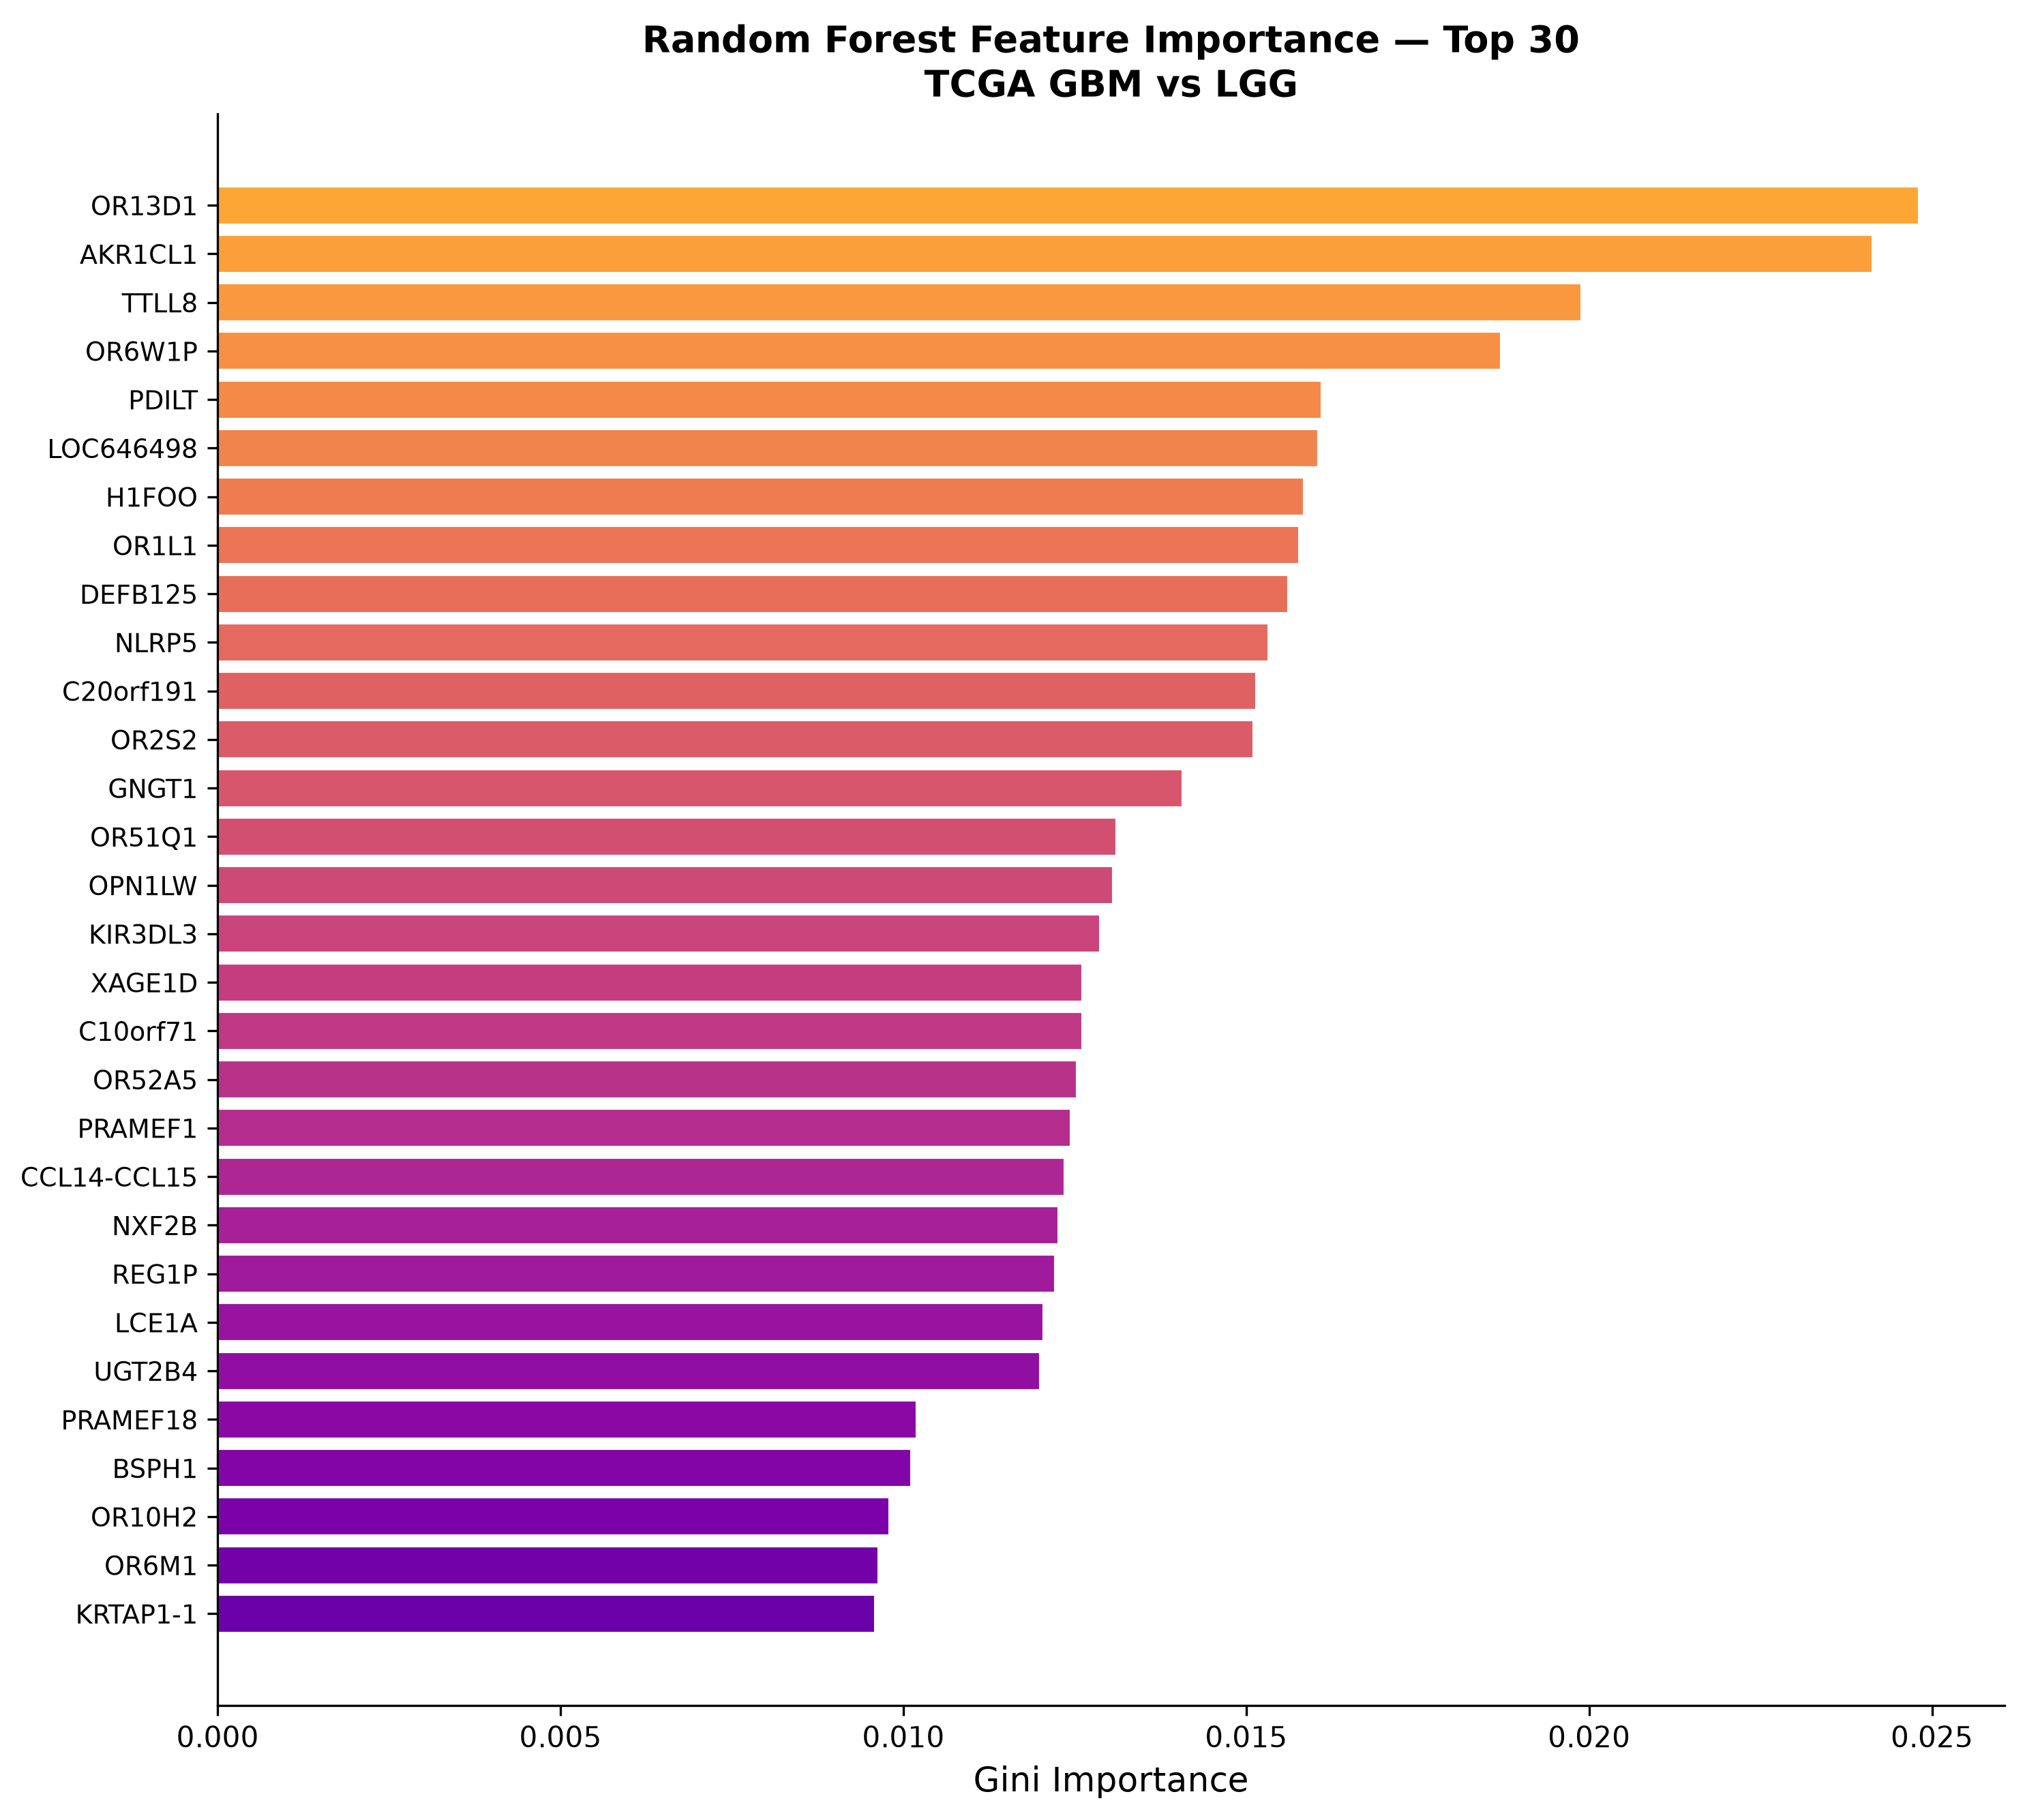

RF top-100 selected: 100 genes


In [21]:
# 8.2 — RF Importance Chart
fig = plot_rf_importance(rf_df, top_n=30, dataset_name="TCGA GBM vs LGG",
                         save_path=RESULTS_DIR / "09_rf_importance_top30.png", dpi=300)
plt.show(); plt.close(fig)
rf_selected = rf_df.head(100)["Gene"].tolist()
print(f"RF top-100 selected: {len(rf_selected)} genes")

---
## Section 9 — XGBoost Feature Importance

XGBoost uses the **Gain** metric — average improvement in loss when a gene is used as a split.

> Higher Gain → gene contributes more to reducing prediction error.

In [22]:
# 9.1 — XGBoost Importance
print("Training XGBoost (200 rounds) on TCGA Combined ...")
xgb_df = xgboost_importance(X_tcga, y_tcga, n_estimators=200, max_depth=4,
                             learning_rate=0.1, random_state=42)
print("\nTop 15 genes by XGBoost Gain:")
print(xgb_df.head(15)[["Gene", "XGB_Importance", "XGB_Rank"]].to_string(index=False))

Training XGBoost (200 rounds) on TCGA Combined ...


2026-09-07 22:58:04 | INFO     | FeatureSelection | XGBoost importance: top gene = AKR1CL1 (0.32161)



Top 15 genes by XGBoost Gain:
     Gene  XGB_Importance  XGB_Rank
  AKR1CL1        0.321609         1
 KRTAP1-1        0.118531         2
    ZPBP2        0.065739         3
   ADAM30        0.062530         4
    DPPA2        0.061771         5
   OR52A5        0.044605         6
  PRAMEF1        0.037140         7
     SPZ1        0.036396         8
  FAM92A3        0.032983         9
  SPANXB2        0.031005        10
   SPANXE        0.029551        11
    PDILT        0.027449        12
LOC646498        0.009786        13
   VPREB1        0.009247        14
   PRSS41        0.008856        15


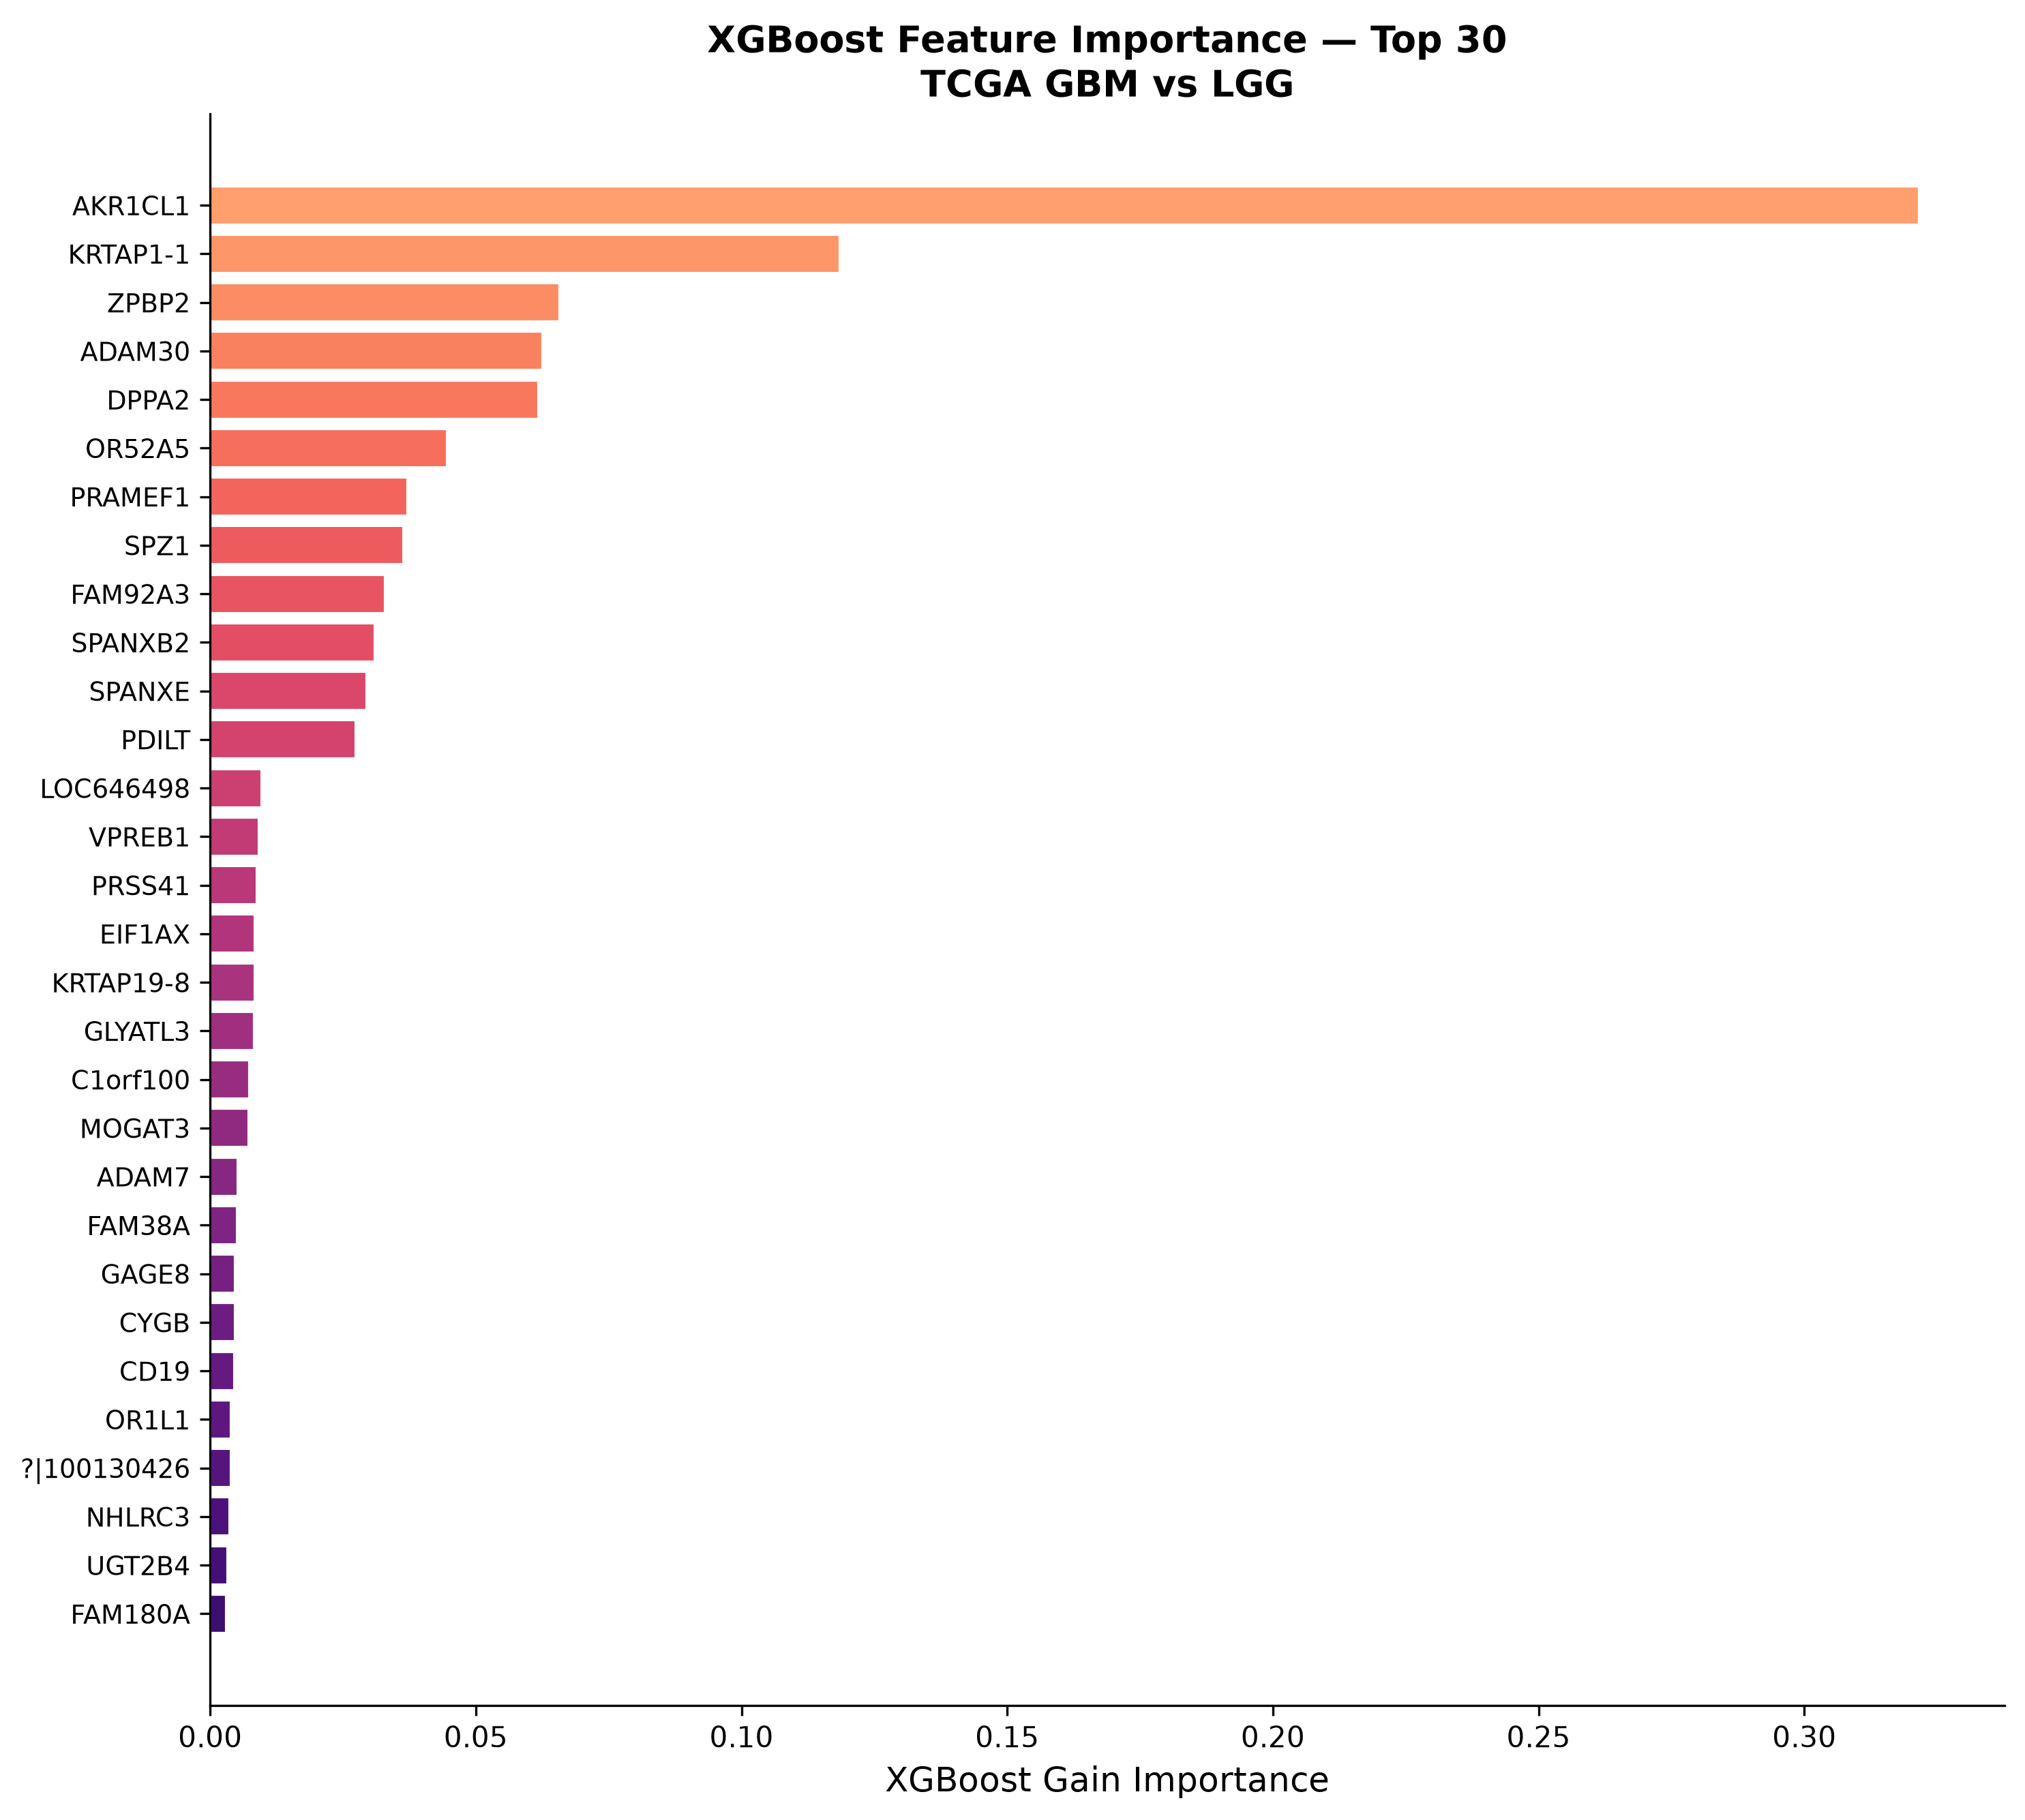

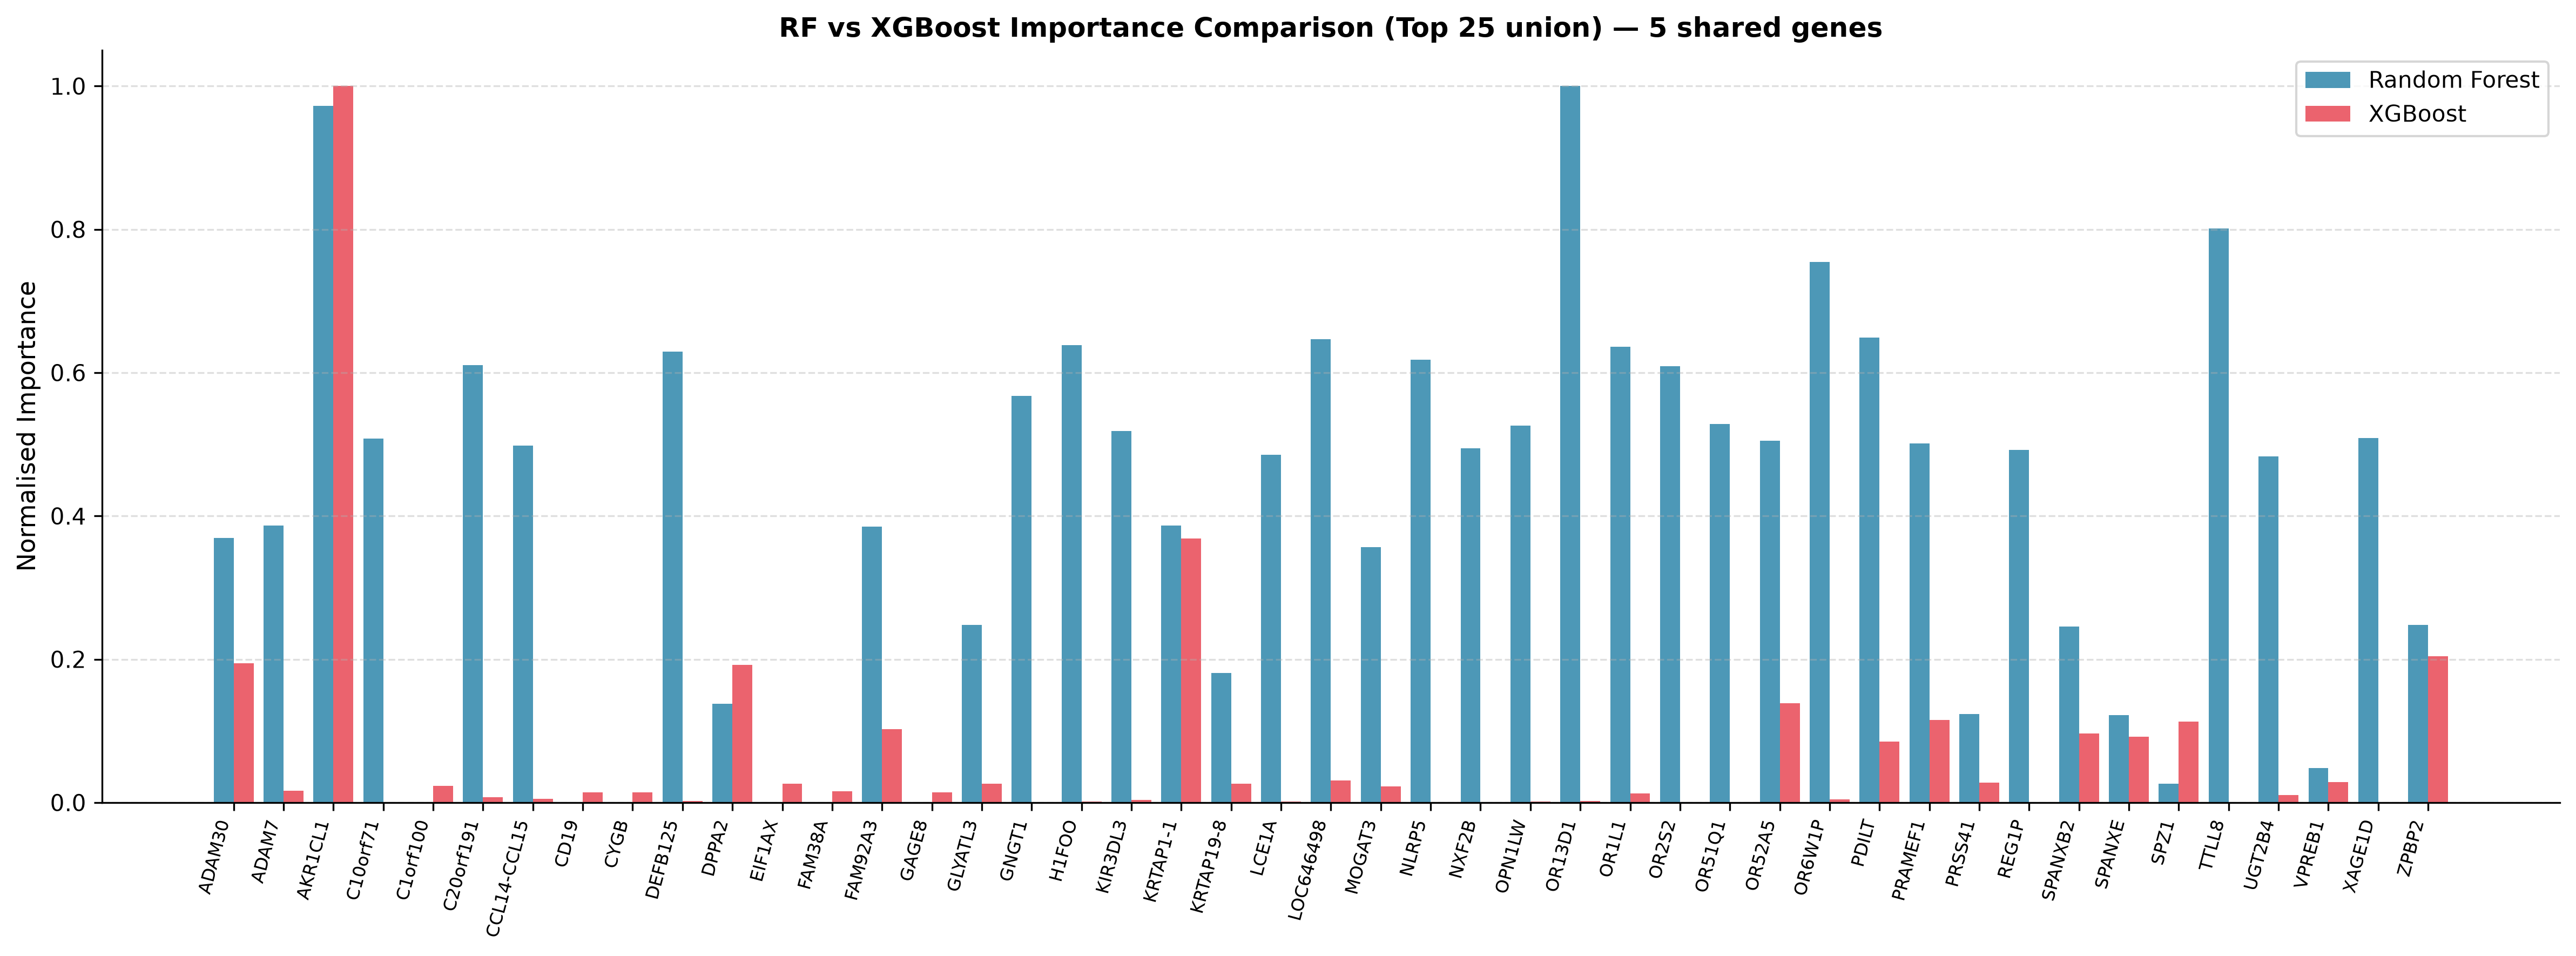

RF-XGBoost overlap (top 100): 39 shared genes


In [23]:
# 9.2 — XGB Chart + RF vs XGB Comparison
fig = plot_xgb_importance(xgb_df, top_n=30, dataset_name="TCGA GBM vs LGG",
                          save_path=RESULTS_DIR / "10_xgb_importance_top30.png", dpi=300)
plt.show(); plt.close(fig)

fig2 = plot_rf_xgb_comparison(rf_df, xgb_df, top_n=25,
                               save_path=RESULTS_DIR / "11_rf_vs_xgb_comparison.png", dpi=300)
plt.show(); plt.close(fig2)

xgb_selected = xgb_df.head(100)["Gene"].tolist()
rf_xgb_shared = set(rf_df.head(100)["Gene"]) & set(xgb_df.head(100)["Gene"])
print(f"RF-XGBoost overlap (top 100): {len(rf_xgb_shared)} shared genes")

---
## Section 10 — Recursive Feature Elimination (RFE)

RFE iteratively trains Logistic Regression, ranks genes by |coefficient|, removes the
least important genes, and repeats until the target count is reached.

In [24]:
# 10.1 — RFE (target=100 genes, step=50)
print("Running RFE (target=100 genes) ...")
rfe_df = rfe_feature_selection(
    X_tcga_scaled, y_tcga,
    n_features_to_select=100, step=50, random_state=42, max_iter=3000
)
rfe_selected = rfe_df[rfe_df["RFE_Selected"]]["Gene"].tolist()
print(f"RFE selected {len(rfe_selected)} genes")
print("\nTop 15 RFE genes:")
print(rfe_df.head(15).to_string(index=False))

Running RFE (target=100 genes) ...


2026-09-07 22:58:09 | INFO     | FeatureSelection | RFE selected 100 genes (target=100)


RFE selected 100 genes

Top 15 RFE genes:
   Gene  RFE_Rank  RFE_Selected
 MRPS36         1          True
  COPZ1         1          True
 PHLPP2         1          True
  RPS10         1          True
  SURF6         1          True
 MYO18A         1          True
   LSM4         1          True
 JARID2         1          True
IGHMBP2         1          True
   SLTM         1          True
 ATP5G2         1          True
  MRTO4         1          True
ZSCAN20         1          True
 ATP2A2         1          True
   DPH5         1          True


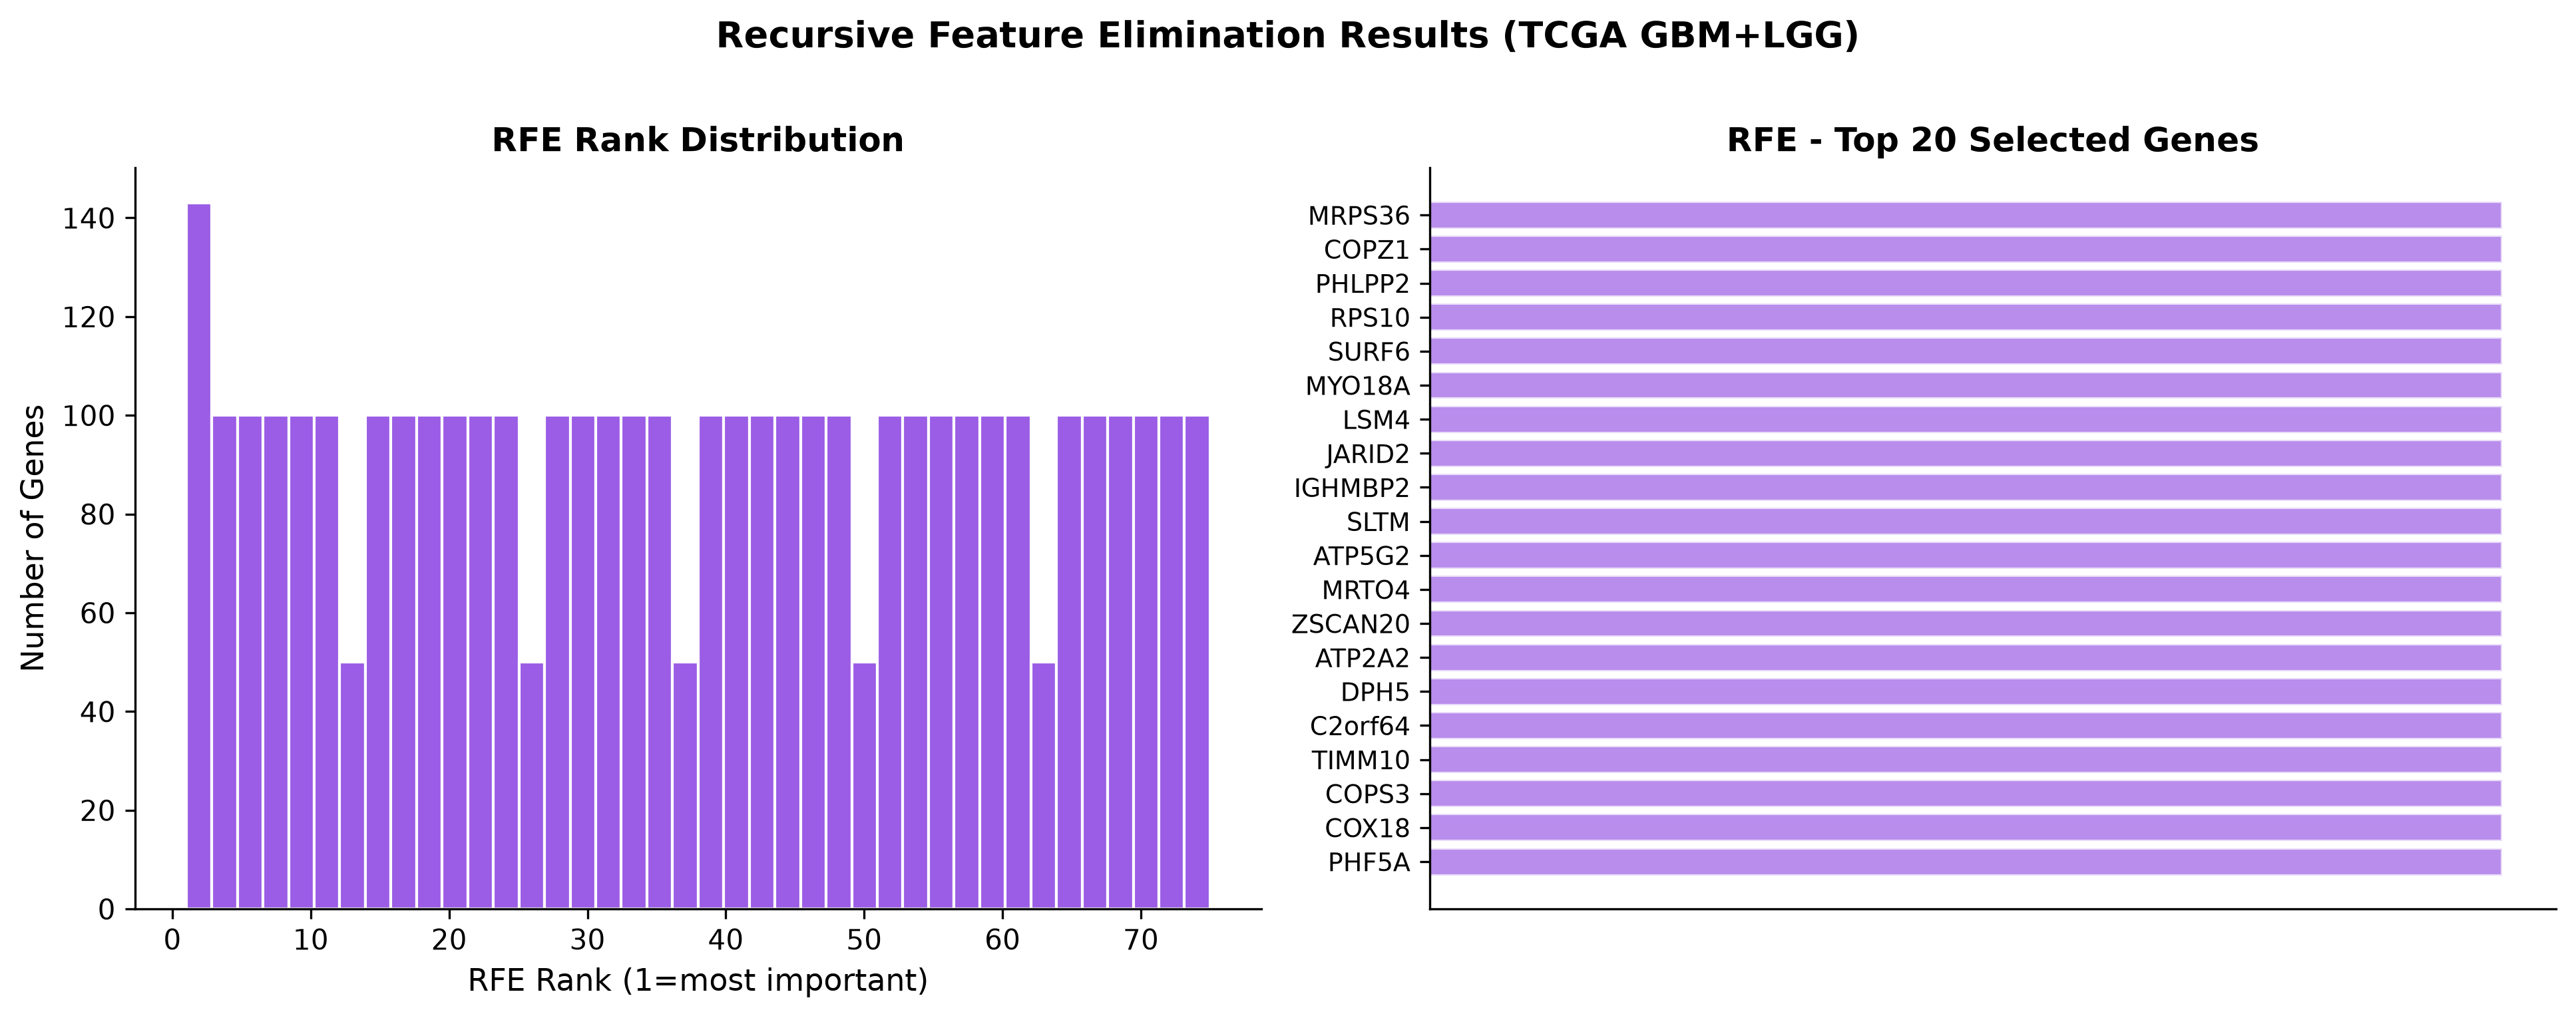

In [25]:
# 10.2 — RFE Rank Distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

axes[0].hist(rfe_df["RFE_Rank"], bins=40, color="#9B5DE5", edgecolor="white")
axes[0].set_xlabel("RFE Rank (1=most important)", fontsize=11)
axes[0].set_ylabel("Number of Genes", fontsize=11)
axes[0].set_title("RFE Rank Distribution", fontsize=12, fontweight="bold")

top20_rfe = rfe_df[rfe_df["RFE_Selected"]].head(20)
axes[1].barh(range(len(top20_rfe), 0, -1), [1]*len(top20_rfe),
             color="#9B5DE5", alpha=0.7, edgecolor="white")
axes[1].set_yticks(range(len(top20_rfe), 0, -1))
axes[1].set_yticklabels(top20_rfe["Gene"].tolist(), fontsize=9)
axes[1].set_title("RFE - Top 20 Selected Genes", fontsize=12, fontweight="bold")
axes[1].tick_params(axis="x", bottom=False, labelbottom=False)

plt.suptitle("Recursive Feature Elimination Results (TCGA GBM+LGG)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "12_rfe_results.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

---
## Section 11 — Consensus Gene Selection

A gene is included in the consensus if selected by **at least 3 independent methods**.
This ensemble approach dramatically reduces false positives and produces robust biomarkers.

> **Rationale:** Individual methods carry biases (ANOVA=linear, LASSO=sparse, RF=deep-split).
> Multi-method agreement signals genuine biological relevance.

In [26]:
# 11.1 — Build Method Gene Lists
method_gene_lists = {
    "VarianceThreshold": vt_selected,
    "ANOVA":             anova_topk[100],
    "MutualInfo":        mi_df.head(100)["Gene"].tolist(),
    "LASSO":             lasso_selected[:100],
    "RandomForest":      rf_df.head(100)["Gene"].tolist(),
    "XGBoost":           xgb_df.head(100)["Gene"].tolist(),
    "RFE":               rfe_selected[:100],
}
print("Gene counts per method:")
for method, genes in method_gene_lists.items():
    print(f"  {method:20s}: {len(genes)} genes")

Gene counts per method:
  VarianceThreshold   : 3793 genes
  ANOVA               : 100 genes
  MutualInfo          : 100 genes
  LASSO               : 0 genes
  RandomForest        : 100 genes
  XGBoost             : 100 genes
  RFE                 : 100 genes


In [27]:
# 11.2 — Build Consensus (min_votes=3)
consensus_df = build_consensus_genes(method_gene_lists, min_votes=3)
consensus_genes = consensus_df[consensus_df["Consensus"]]["Gene"].tolist()
print(f"Consensus genes (>=3 votes): {len(consensus_genes)}")
print("\nTop 30 Consensus Genes:")
print(consensus_df.head(30)[["Gene", "Vote_Count", "Methods"]].to_string(index=False))

2026-09-07 22:58:10 | INFO     | FeatureSelection | Consensus: 68 genes pass min_votes=3 (out of 3793 unique genes)


Consensus genes (>=3 votes): 68

Top 30 Consensus Genes:
       Gene  Vote_Count                                              Methods
      ADAM7           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost
  C20orf191           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost
    GLYATL3           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost
     GUCA2B           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost
  LOC646498           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost
     MOGAT3           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost
     OR13C9           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost
     OR5B21           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost
   SNORA36A           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost
?|100130426           3             RandomForest; VarianceThreshold; XGBoost
     ADAM30           3             RandomForest; VarianceThreshold; XGBoost
      AKAP4        

2026-09-07 22:58:11 | INFO     | FeatureSelection | Saved consensus heatmap → C:\Research_Project\Brain_Tumor_Project\results\feature_selection\13_consensus_overlap_heatmap.png


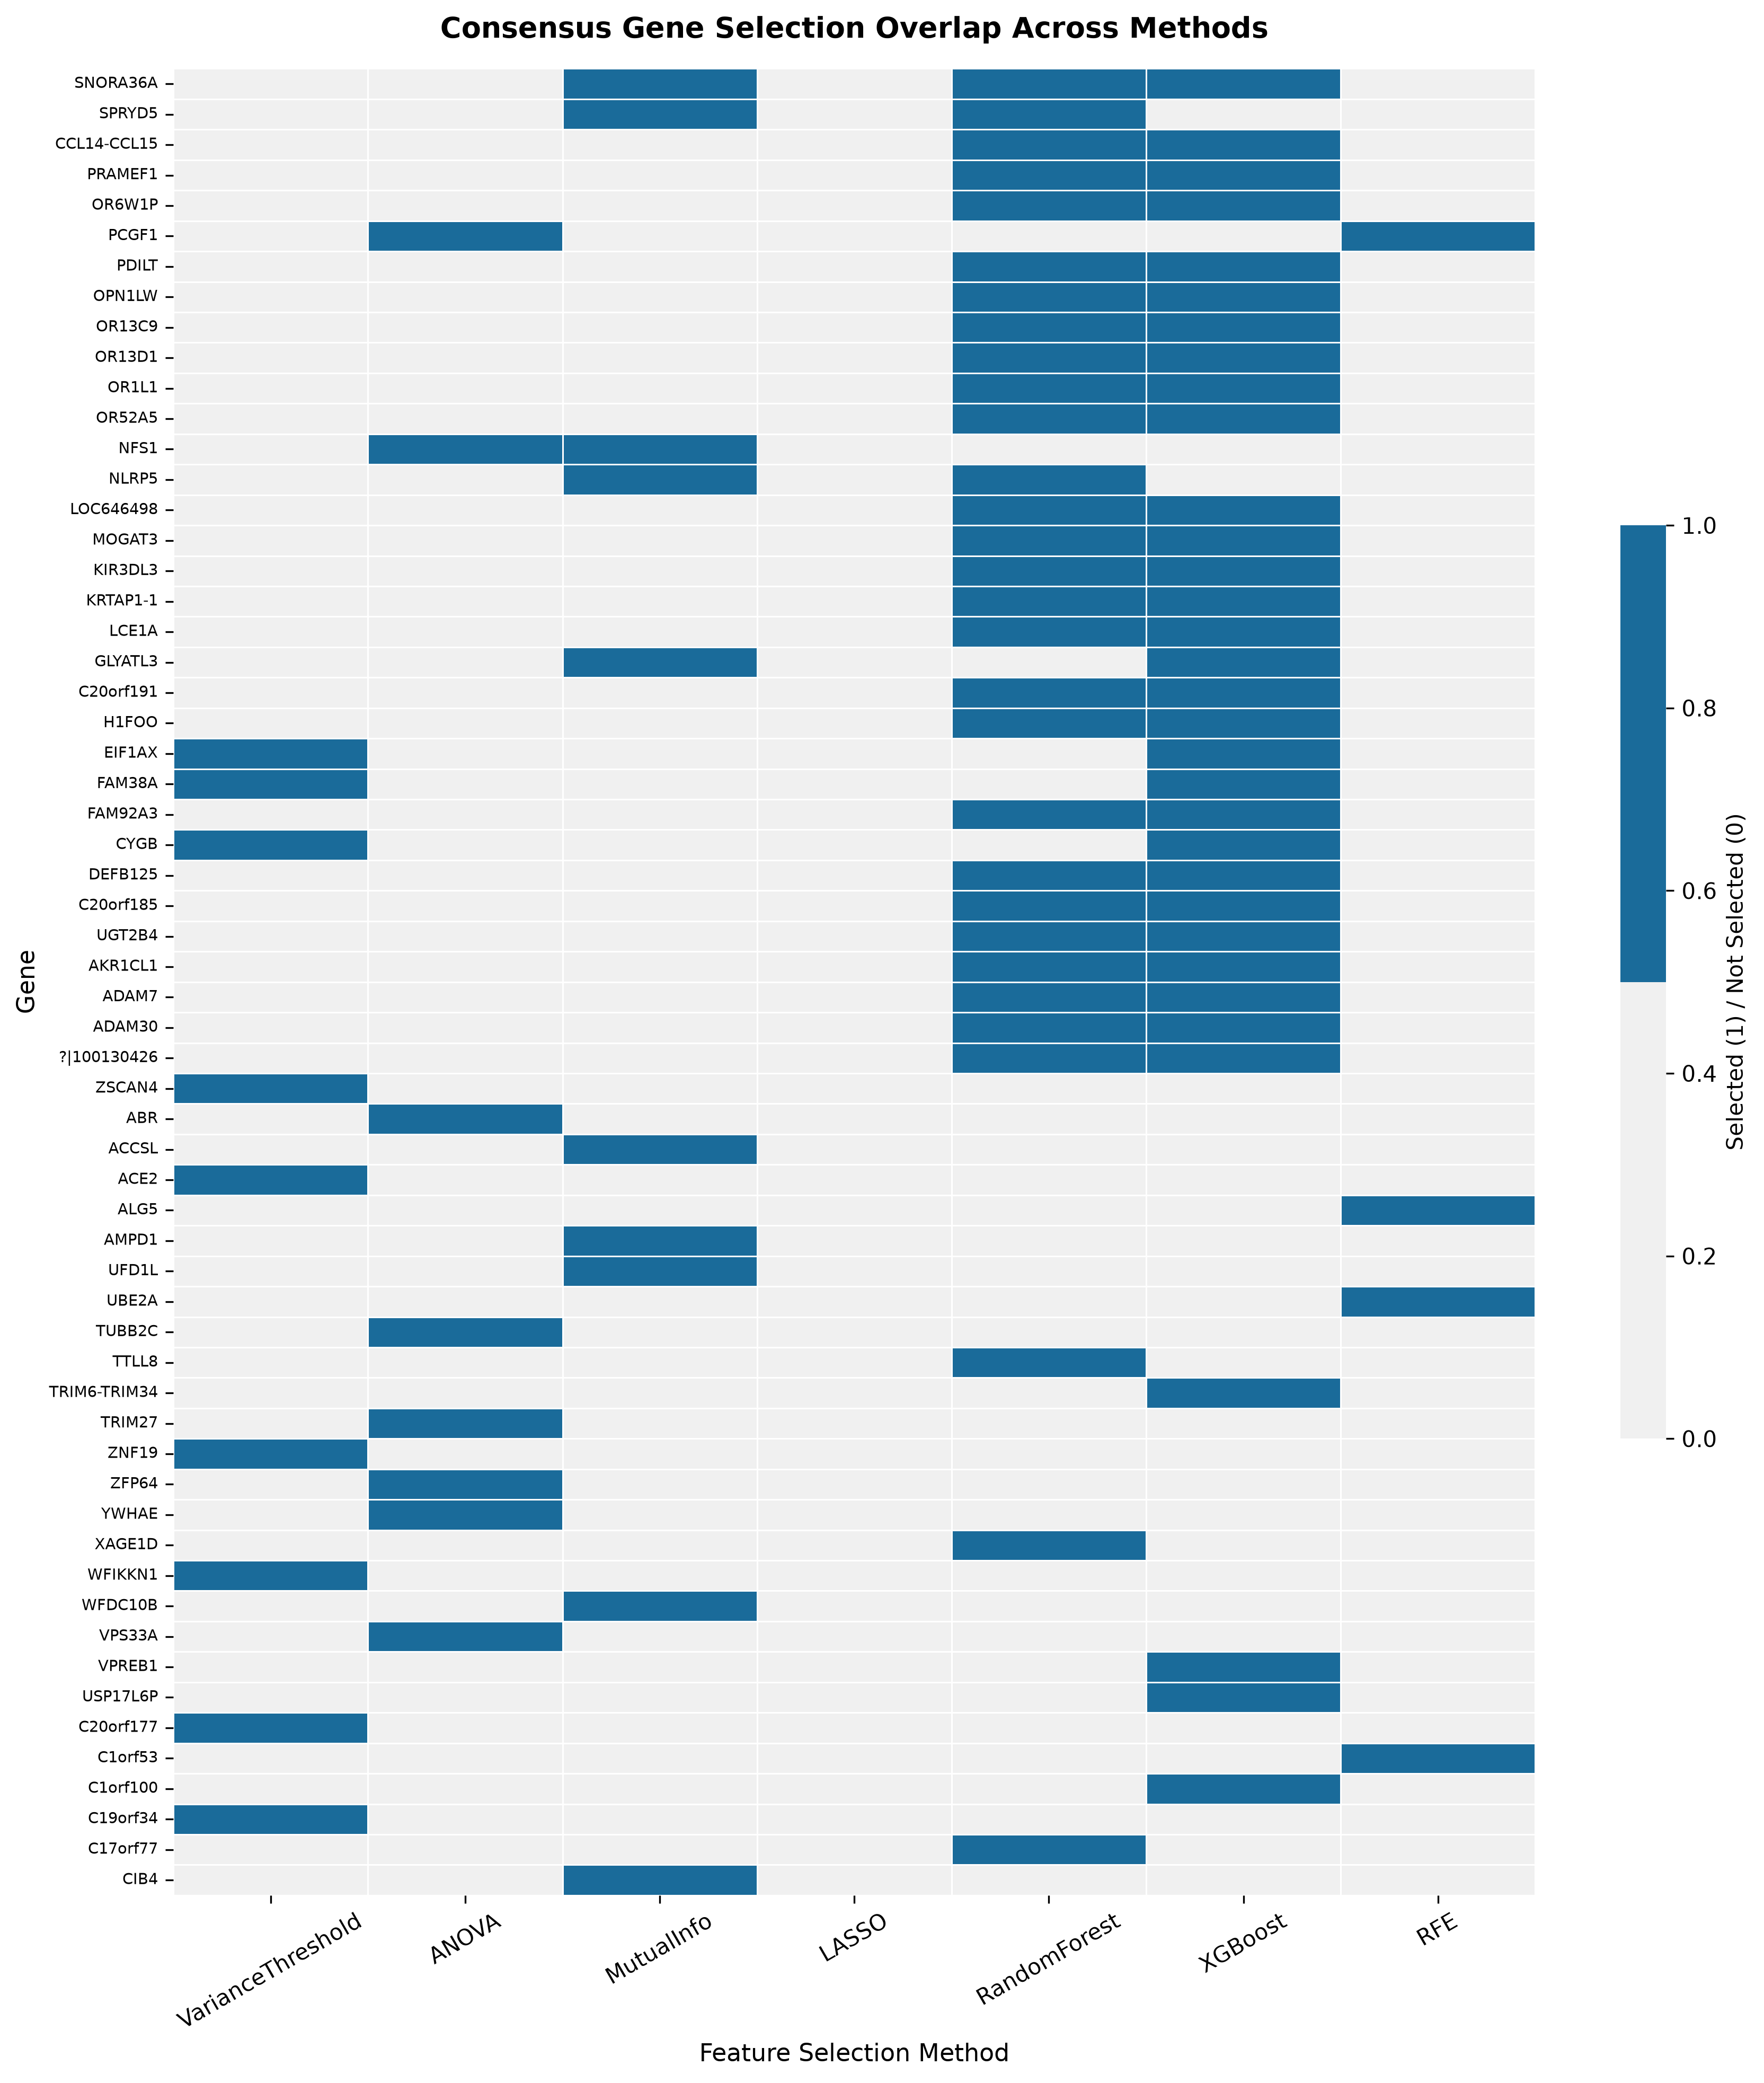

In [28]:
# 11.3 — Consensus Overlap Heatmap
fig = plot_consensus_overlap_heatmap(method_gene_lists, top_n=50,
                                      save_path=RESULTS_DIR / "13_consensus_overlap_heatmap.png",
                                      dpi=300)
plt.show(); plt.close(fig)

2026-09-07 22:58:12 | INFO     | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-09-07 22:58:12 | INFO     | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


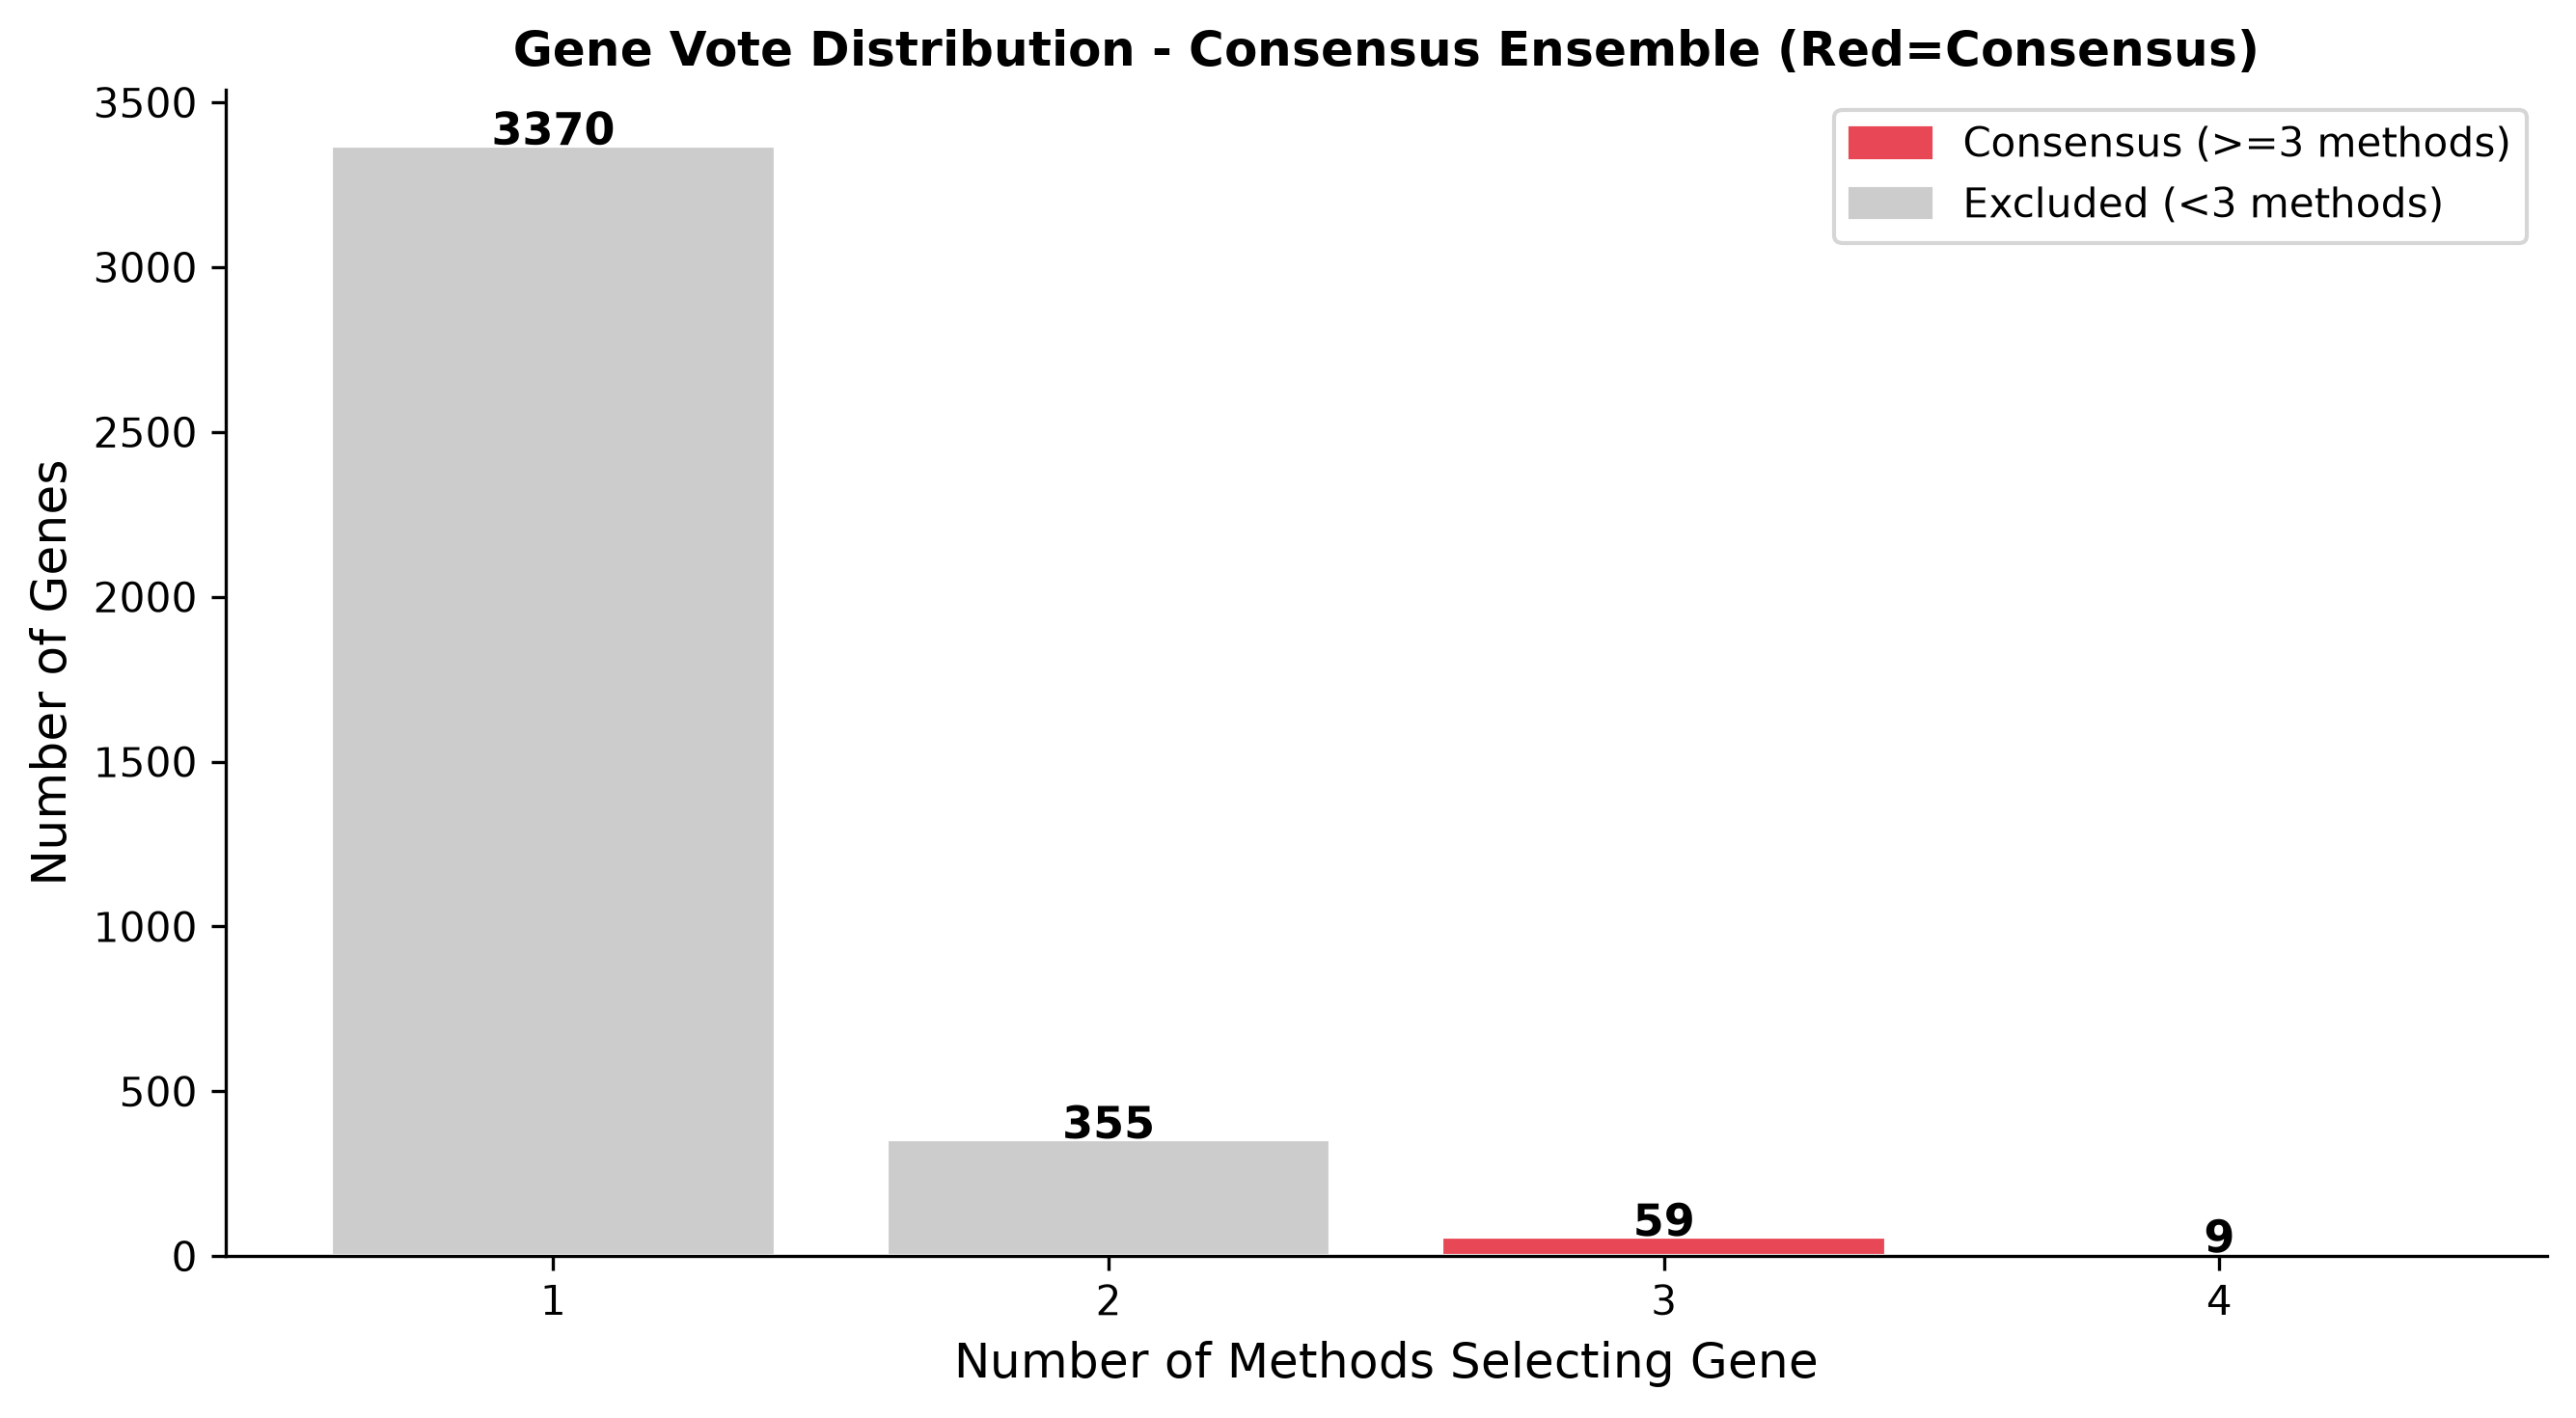

In [29]:
# 11.4 — Vote Distribution Bar Chart
vote_counts = consensus_df["Vote_Count"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 5), dpi=300)
colors_v = ["#E84855" if v >= 3 else "#cccccc" for v in vote_counts.index]
bars = ax.bar(vote_counts.index.astype(str), vote_counts.values, color=colors_v, edgecolor="white")
for bar, cnt in zip(bars, vote_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+1,
            str(cnt), ha="center", fontsize=11, fontweight="bold")
ax.set_xlabel("Number of Methods Selecting Gene", fontsize=12)
ax.set_ylabel("Number of Genes", fontsize=12)
ax.set_title("Gene Vote Distribution - Consensus Ensemble (Red=Consensus)",
             fontsize=12, fontweight="bold")
patches = [mpatches.Patch(color="#E84855", label="Consensus (>=3 methods)"),
           mpatches.Patch(color="#cccccc", label="Excluded (<3 methods)")]
ax.legend(handles=patches, fontsize=10)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "14_vote_distribution.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

---
## Section 12 — Biological Interpretation

Top consensus genes are annotated with curated biological roles from:  
WHO CNS 2021 Classification, TCGA Pan-Glioma Studies, CGGA Reports.

> Only literature-confirmed roles are listed.  
> Unknown genes are marked "No curated annotation available".

In [30]:
# 12.1 — Annotate Top 20 Consensus Genes
bio_table = annotate_consensus_genes(consensus_df, top_n=20)
print("Biological Annotation Table - Top 20 Consensus Genes:")
print(bio_table.to_string(index=False, max_colwidth=80))

Biological Annotation Table - Top 20 Consensus Genes:
       Gene  Vote_Count                                              Methods                 Biological_Role Tumour_Association
      ADAM7           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost No curated annotation available            Unknown
  C20orf191           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost No curated annotation available            Unknown
    GLYATL3           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost No curated annotation available            Unknown
     GUCA2B           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost No curated annotation available            Unknown
  LOC646498           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost No curated annotation available            Unknown
     MOGAT3           4 MutualInfo; RandomForest; VarianceThreshold; XGBoost No curated annotation available            Unknown
     OR13C9           4 MutualInfo; RandomForest; 

In [31]:
# 12.2 — Display Styled Table
try:
    from IPython.display import display
    styled = (
        bio_table.style
        .set_caption("Top 20 Consensus Biomarker Genes - Biological Annotation")
        .set_properties(**{"text-align": "left", "font-size": "12px"})
        .bar(subset=["Vote_Count"], color="#2E86AB", vmin=0, vmax=7)
        .set_table_styles([
            {"selector": "th", "props": [("font-weight", "bold"),
                                          ("background", "#1a1a2e"),
                                          ("color", "white")]}
        ])
    )
    display(styled)
except Exception:
    print(bio_table.to_string(index=False))

,Gene,Vote_Count,Methods,Biological_Role,Tumour_Association
0,ADAM7,4,MutualInfo; RandomForest; VarianceThreshold; XGBoost,No curated annotation available,Unknown
1,C20orf191,4,MutualInfo; RandomForest; VarianceThreshold; XGBoost,No curated annotation available,Unknown
2,GLYATL3,4,MutualInfo; RandomForest; VarianceThreshold; XGBoost,No curated annotation available,Unknown
3,GUCA2B,4,MutualInfo; RandomForest; VarianceThreshold; XGBoost,No curated annotation available,Unknown
4,LOC646498,4,MutualInfo; RandomForest; VarianceThreshold; XGBoost,No curated annotation available,Unknown
5,MOGAT3,4,MutualInfo; RandomForest; VarianceThreshold; XGBoost,No curated annotation available,Unknown
6,OR13C9,4,MutualInfo; RandomForest; VarianceThreshold; XGBoost,No curated annotation available,Unknown
7,OR5B21,4,MutualInfo; RandomForest; VarianceThreshold; XGBoost,No curated annotation available,Unknown
8,SNORA36A,4,MutualInfo; RandomForest; VarianceThreshold; XGBoost,No curated annotation available,Unknown
9,?|100130426,3,RandomForest; VarianceThreshold; XGBoost,No curated annotation available,Unknown


---
## Section 13 — PCA After Feature Selection

Side-by-side PCA: full feature matrix vs consensus-selected genes.

PCA: Full (702, 3793) vs Selected (702, 68)


2026-09-07 22:58:13 | INFO     | FeatureSelection | Saved PCA comparison → C:\Research_Project\Brain_Tumor_Project\results\feature_selection\15_pca_comparison.png


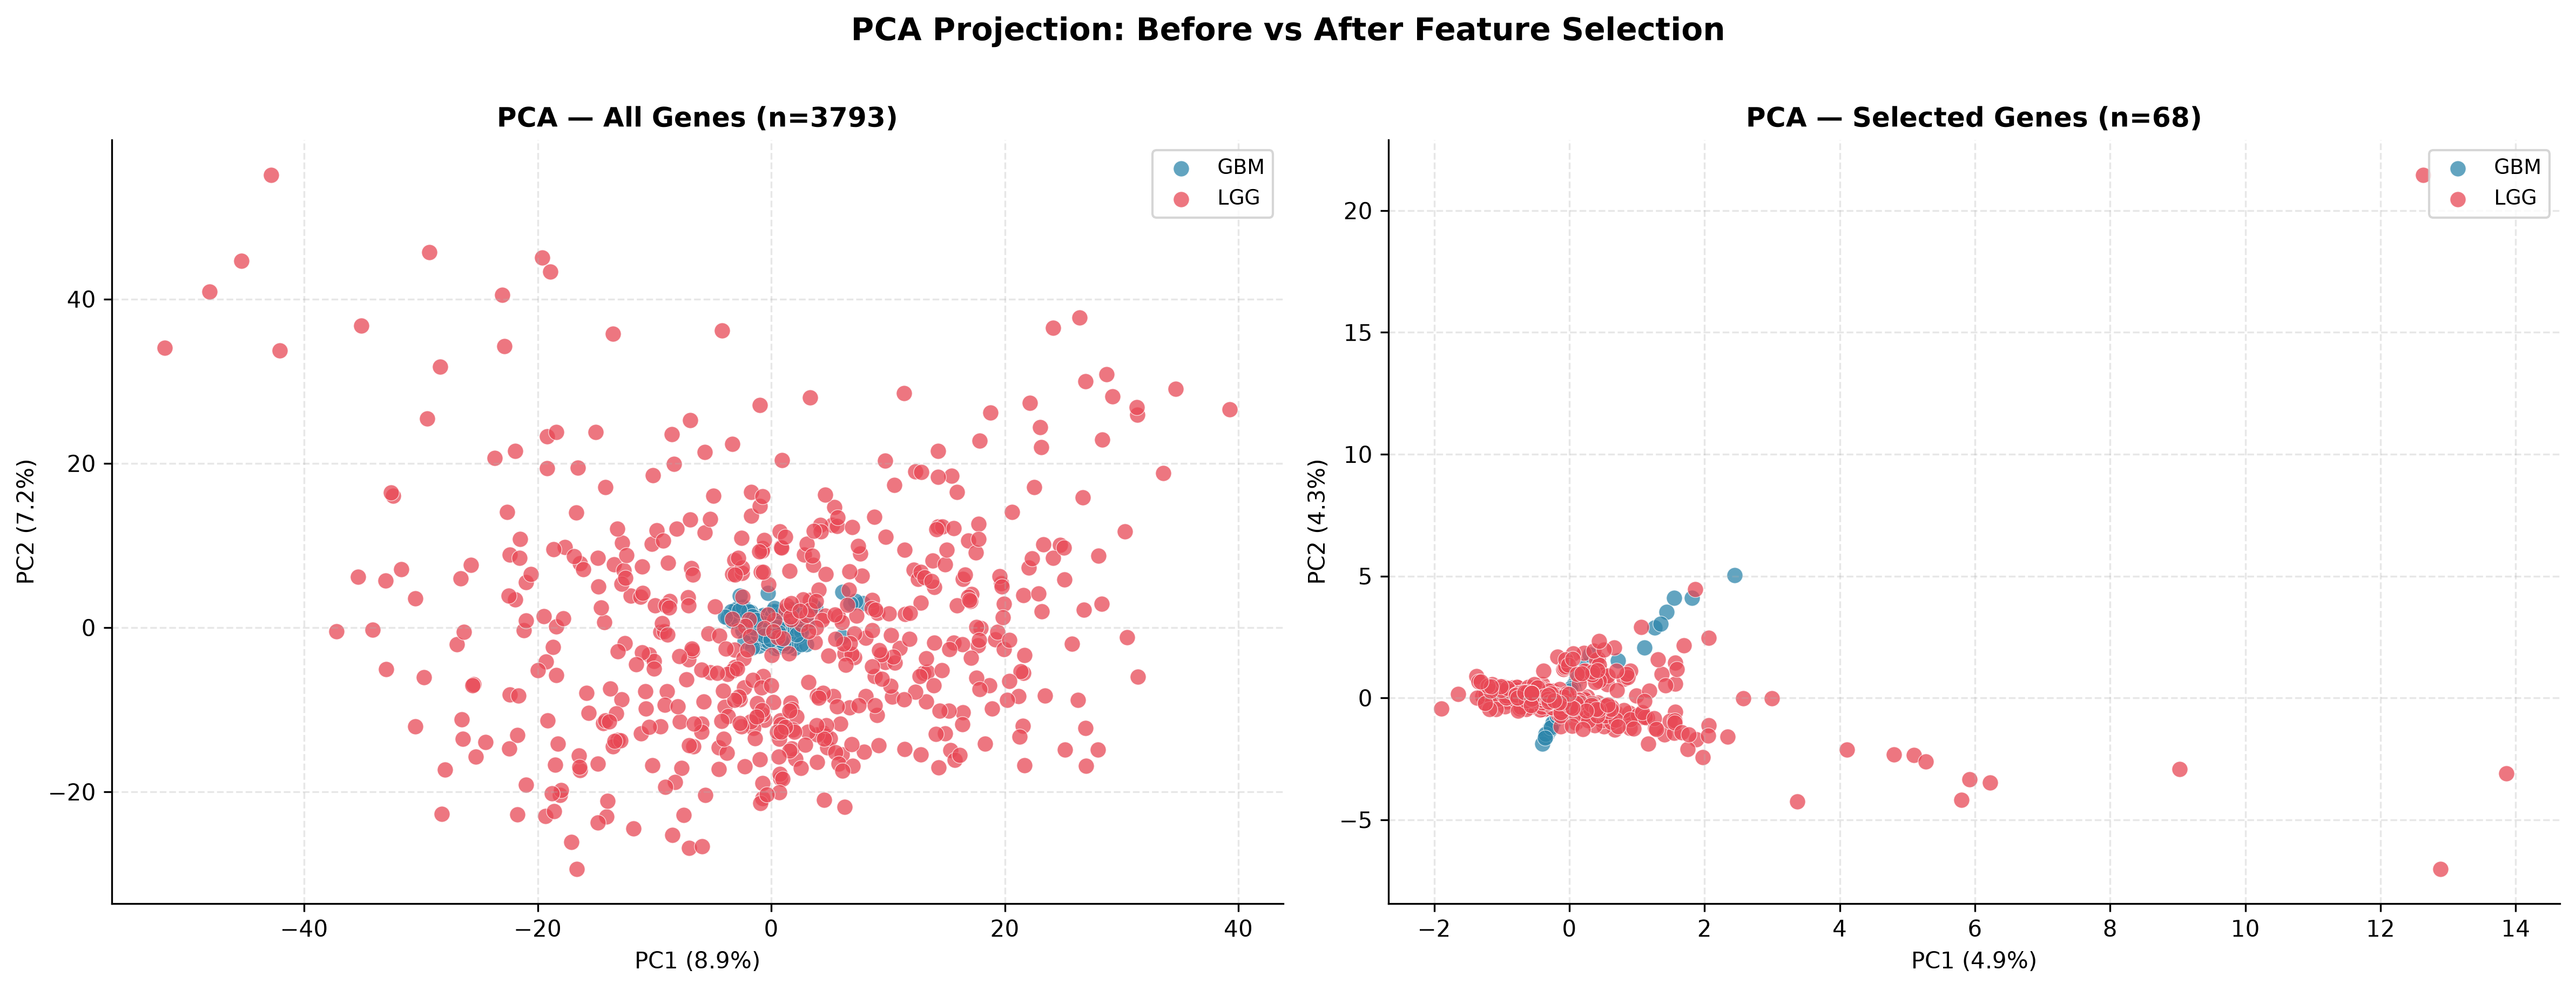

In [32]:
# 13.1 — PCA Comparison
valid_consensus = [g for g in consensus_genes if g in X_tcga.columns]
X_selected = X_tcga[valid_consensus] if valid_consensus else X_tcga[anova_topk[100]]
print(f"PCA: Full {X_tcga.shape} vs Selected {X_selected.shape}")

label_names = le_tcga.classes_.tolist()
fig = plot_pca_comparison(X_before=X_tcga, X_after=X_selected, labels=y_tcga,
                           label_names=label_names,
                           save_path=RESULTS_DIR / "15_pca_comparison.png", dpi=300)
plt.show(); plt.close(fig)

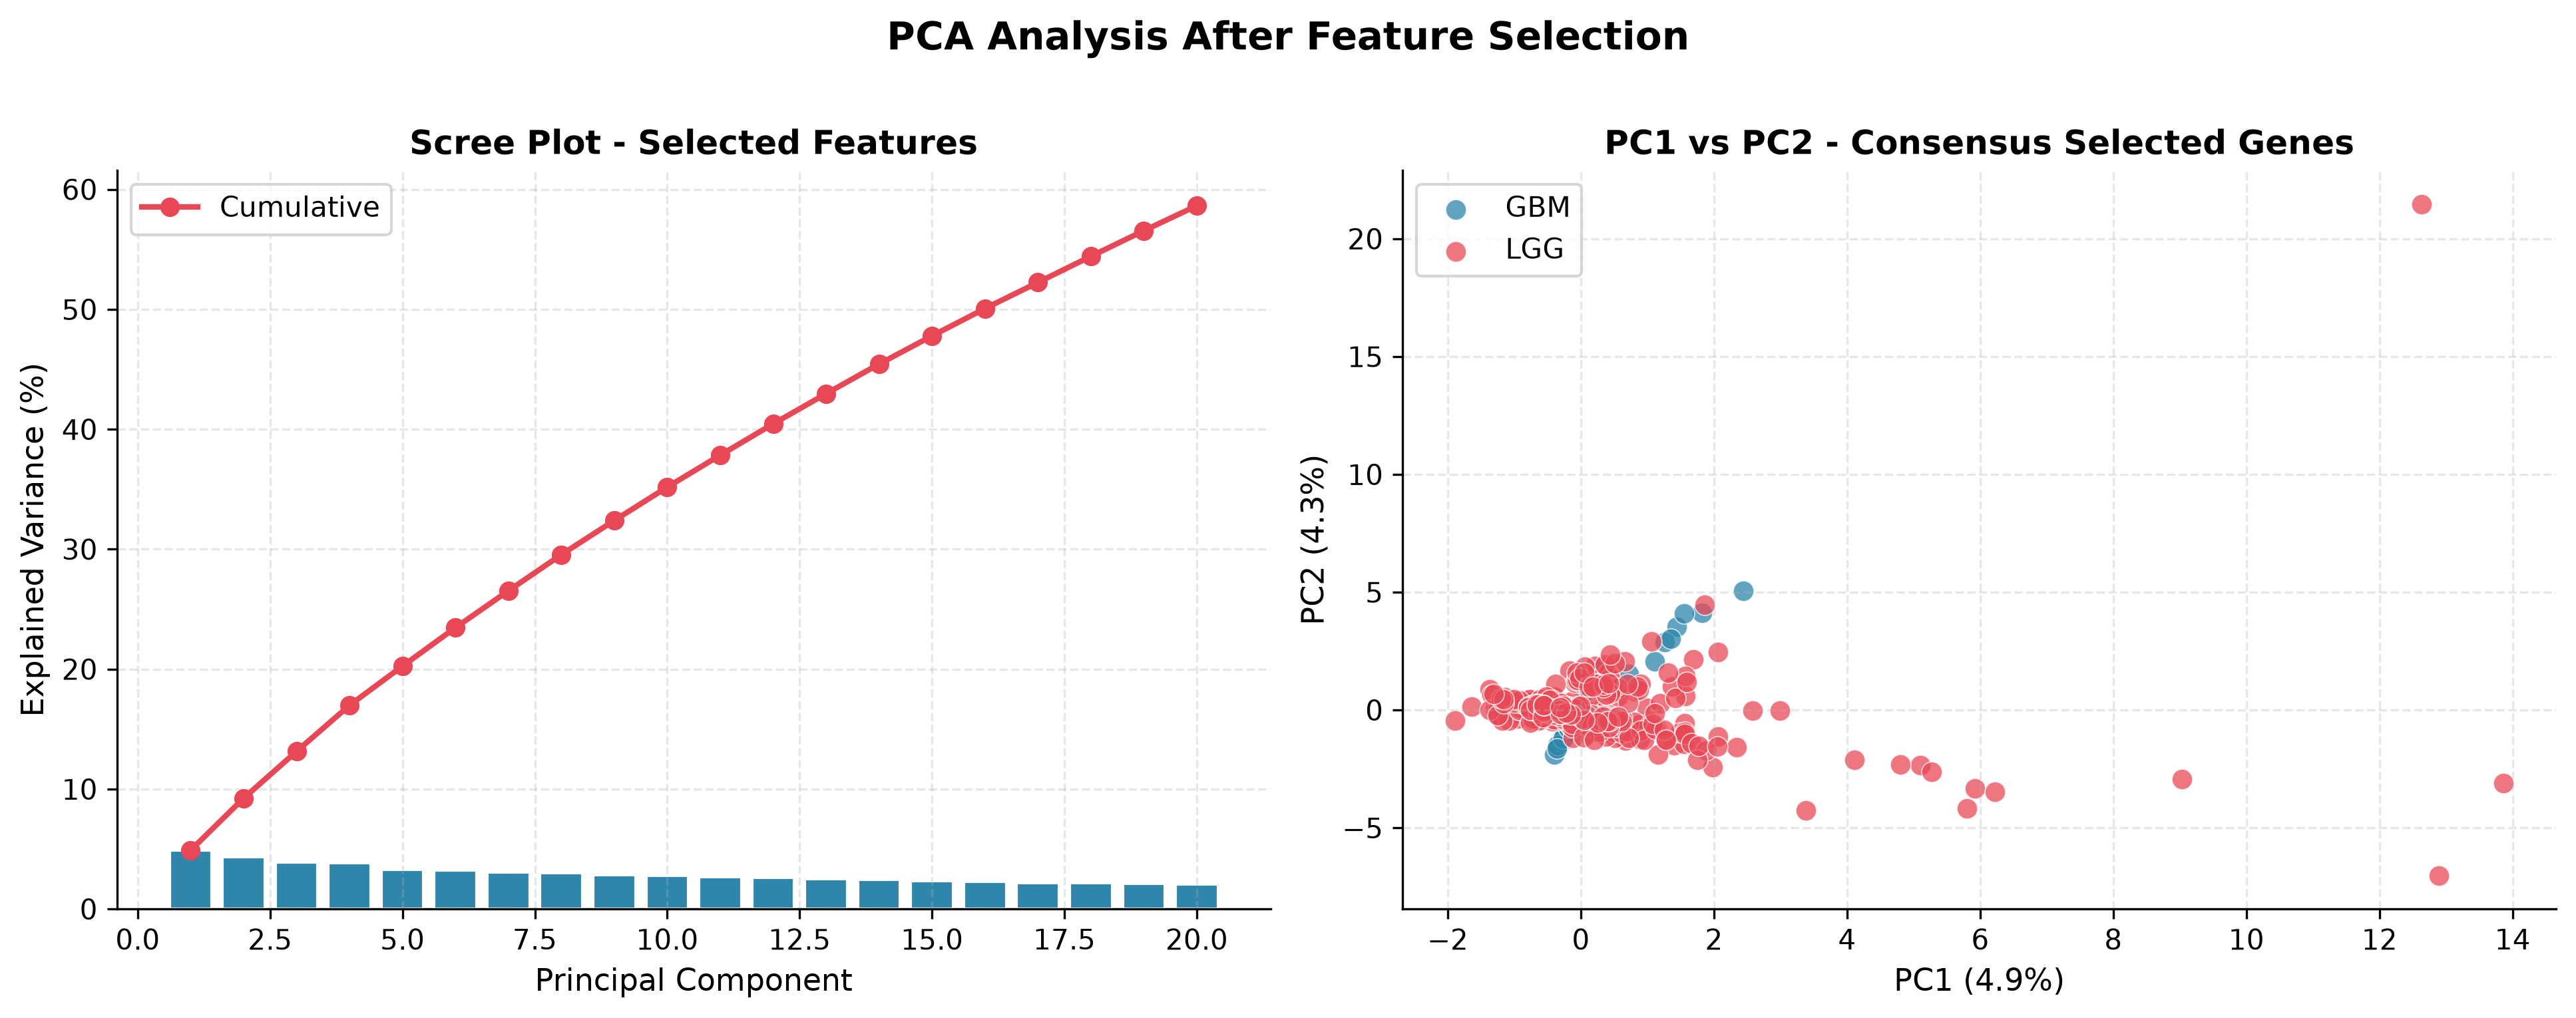

In [33]:
# 13.2 — Scree Plot + PC1 vs PC2 (Selected)
pca_sel, pca_sel_df = compute_pca_projection(X_selected, n_components=20)
ev_sel = pca_sel.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)
axes[0].bar(range(1, len(ev_sel)+1), ev_sel, color="#2E86AB", edgecolor="white")
axes[0].plot(range(1, len(ev_sel)+1), np.cumsum(ev_sel), "o-", color="#E84855", lw=2, label="Cumulative")
axes[0].set_xlabel("Principal Component", fontsize=11)
axes[0].set_ylabel("Explained Variance (%)", fontsize=11)
axes[0].set_title("Scree Plot - Selected Features", fontsize=12, fontweight="bold")
axes[0].legend(fontsize=10); axes[0].grid(True, linestyle="--", alpha=0.3)

pca_sel_df["label"] = y_tcga
for lbl, name, clr in zip([0,1], label_names, ["#2E86AB","#E84855"]):
    mask = pca_sel_df["label"] == lbl
    axes[1].scatter(pca_sel_df.loc[mask,"PC1"], pca_sel_df.loc[mask,"PC2"],
                    c=clr, label=name, alpha=0.75, s=55, edgecolors="white", lw=0.4)
axes[1].set_xlabel(f"PC1 ({ev_sel[0]:.1f}%)", fontsize=11)
axes[1].set_ylabel(f"PC2 ({ev_sel[1]:.1f}%)", fontsize=11)
axes[1].set_title("PC1 vs PC2 - Consensus Selected Genes", fontsize=12, fontweight="bold")
axes[1].legend(fontsize=10); axes[1].grid(True, linestyle="--", alpha=0.3)

plt.suptitle("PCA Analysis After Feature Selection", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "16_pca_selected_scree.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

---
## Section 14 — t-SNE After Feature Selection

t-SNE preserves local structure in a 2D embedding. We pre-reduce to 50 PCs before t-SNE for stability and speed.

Running t-SNE (Before + After) — may take ~2 min ...


2026-09-07 22:58:18 | INFO     | FeatureSelection | Saved t-SNE comparison → C:\Research_Project\Brain_Tumor_Project\results\feature_selection\17_tsne_comparison.png


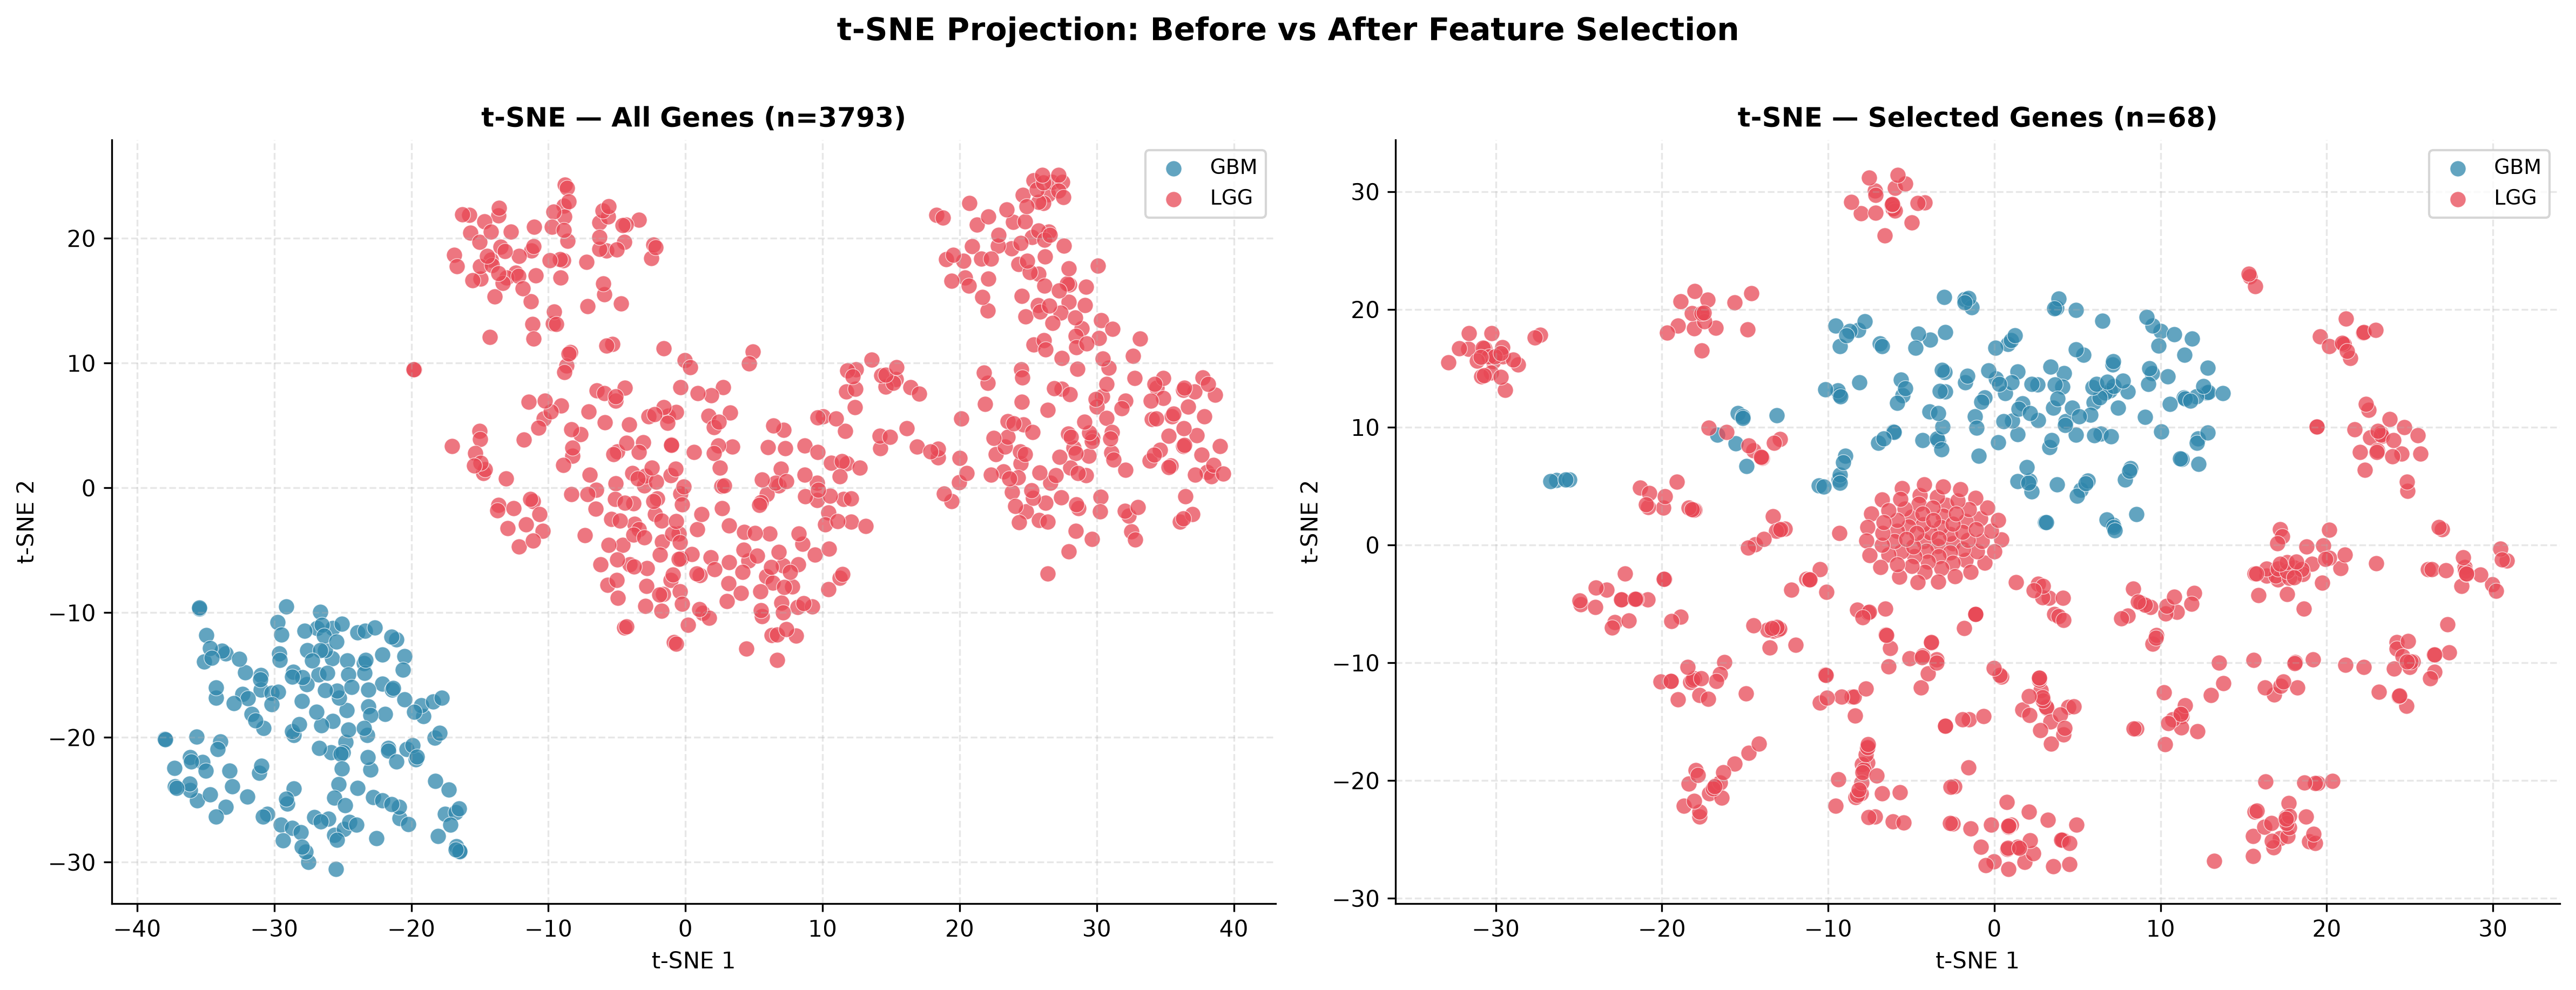

t-SNE comparison saved.


In [34]:
# 14.1 — t-SNE Comparison
print("Running t-SNE (Before + After) — may take ~2 min ...")
fig = plot_tsne_comparison(X_before=X_tcga, X_after=X_selected, labels=y_tcga,
                            label_names=label_names, perplexity=30,
                            save_path=RESULTS_DIR / "17_tsne_comparison.png", dpi=300)
plt.show(); plt.close(fig)
print("t-SNE comparison saved.")

---
## Section 15 — Prepare ML Feature Sets

Save filtered feature matrices for downstream ML training in Phase 5.

In [35]:
# 15.1 — Save Top-K Feature Matrices
y_tcga_series = pd.Series(y_tcga_str.values, index=X_tcga.index, name="label")

for k in [50, 100, 250, 500]:
    genes_k = anova_topk.get(k, anova_df.head(k)["Gene"].tolist())
    genes_k = [g for g in genes_k if g in X_tcga.columns]
    save_feature_matrix(X_tcga, y_tcga_series, genes_k,
                        path=FEAT_SETS / f"top{k}_genes.csv", label_col="label")

save_feature_matrix(X_tcga, y_tcga_series, consensus_genes,
                    path=FEAT_SETS / "consensus_genes.csv", label_col="label")
print("All feature matrices saved to:", FEAT_SETS)

2026-09-07 22:58:19 | INFO     | FeatureSelection | Saved feature matrix (702 samples × 51 genes) → C:\Research_Project\Brain_Tumor_Project\data\processed\feature_sets\top50_genes.csv


2026-09-07 22:58:19 | INFO     | FeatureSelection | Saved feature matrix (702 samples × 101 genes) → C:\Research_Project\Brain_Tumor_Project\data\processed\feature_sets\top100_genes.csv


2026-09-07 22:58:20 | INFO     | FeatureSelection | Saved feature matrix (702 samples × 251 genes) → C:\Research_Project\Brain_Tumor_Project\data\processed\feature_sets\top250_genes.csv


2026-09-07 22:58:20 | INFO     | FeatureSelection | Saved feature matrix (702 samples × 501 genes) → C:\Research_Project\Brain_Tumor_Project\data\processed\feature_sets\top500_genes.csv


2026-09-07 22:58:20 | INFO     | FeatureSelection | Saved feature matrix (702 samples × 69 genes) → C:\Research_Project\Brain_Tumor_Project\data\processed\feature_sets\consensus_genes.csv


All feature matrices saved to: C:\Research_Project\Brain_Tumor_Project\data\processed\feature_sets


In [36]:
# 15.2 — Save Gene Metadata
meta = anova_df[["Gene","F_Score","P_Value","Rank_ANOVA"]].copy()
meta = meta.merge(mi_df[["Gene","MI_Score","Rank_MI"]], on="Gene", how="left")
meta = meta.merge(rf_df[["Gene","RF_Importance","RF_Rank"]], on="Gene", how="left")
meta = meta.merge(xgb_df[["Gene","XGB_Importance","XGB_Rank"]], on="Gene", how="left")
meta = meta.merge(
    lasso_coef_df[["Gene","MaxAbsCoef","Selected"]].rename(
        columns={"MaxAbsCoef":"LASSO_Coef","Selected":"LASSO_Selected"}),
    on="Gene", how="left")
meta = meta.merge(rfe_df[["Gene","RFE_Rank","RFE_Selected"]], on="Gene", how="left")
meta = meta.merge(consensus_df[["Gene","Vote_Count","Methods","Consensus"]], on="Gene", how="left")

meta.to_csv(FEAT_SETS / "selected_gene_metadata.csv", index=False)
print(f"Gene metadata saved: {meta.shape}")
meta.head(10)

Gene metadata saved: (3793, 17)


,Gene,F_Score,P_Value,Rank_ANOVA,MI_Score,Rank_MI,RF_Importance,RF_Rank,XGB_Importance,XGB_Rank,LASSO_Coef,LASSO_Selected,RFE_Rank,RFE_Selected,Vote_Count,Methods,Consensus
0,CFL1,5.035849e-26,1.0,1,0.542248,1067,0.000000,1879,0.0,1872,0.0,False,5,False,2,ANOVA; VarianceThreshold,False
1,EIF2B1,3.392219e-26,1.0,2,0.542248,1237,0.000000,2347,0.0,2347,0.0,False,8,False,2,ANOVA; VarianceThreshold,False
2,MTCH1,2.409956e-26,1.0,3,0.542248,1097,0.000000,1584,0.0,1547,0.0,False,16,False,2,ANOVA; VarianceThreshold,False
3,VPS33A,2.203676e-26,1.0,4,0.526992,3127,0.000000,3381,0.0,3381,0.0,False,11,False,2,ANOVA; VarianceThreshold,False
4,CDK2AP1,2.175297e-26,1.0,5,0.519365,3545,0.000269,252,0.0,2765,0.0,False,2,False,2,ANOVA; VarianceThreshold,False
5,CHCHD3,2.163767e-26,1.0,6,0.526992,3222,0.000000,1971,0.0,1971,0.0,False,69,False,2,ANOVA; VarianceThreshold,False
6,CHMP1B,2.161585e-26,1.0,7,0.534620,2061,0.000000,1422,0.0,1369,0.0,False,7,False,2,ANOVA; VarianceThreshold,False
7,TKT,2.039443e-26,1.0,8,0.526992,3101,0.000000,1450,0.0,1401,0.0,False,46,False,2,ANOVA; VarianceThreshold,False
8,TUBB2C,2.001057e-26,1.0,9,0.542248,1282,0.000000,2438,0.0,2438,0.0,False,43,False,2,ANOVA; VarianceThreshold,False
9,ZNF561,1.975531e-26,1.0,10,0.542248,1103,0.000388,181,0.0,1480,0.0,False,8,False,2,ANOVA; VarianceThreshold,False


---
## Section 16 — Save Feature Selection Reports

In [37]:
# 16.1 — Export All CSV Reports
report_map = {
    "ANOVA_Ranking.csv":  anova_df,
    "MI_Ranking.csv":     mi_df,
    "RF_Importance.csv":  rf_df,
    "XGB_Importance.csv": xgb_df,
    "LASSO_Selected.csv": lasso_coef_df[lasso_coef_df["Selected"]].reset_index(drop=True),
    "RFE_Selected.csv":   rfe_df[rfe_df["RFE_Selected"]].reset_index(drop=True),
    "Consensus_Genes.csv":consensus_df,
}
for fname, df in report_map.items():
    save_report_csv(df, RESULTS_DIR / fname, fname.replace(".csv",""))
print("All reports saved:")
for f in sorted(RESULTS_DIR.glob("*.csv")):
    print(f"  {f.name}")

2026-09-07 22:58:20 | INFO     | FeatureSelection | Saved ANOVA_Ranking → C:\Research_Project\Brain_Tumor_Project\results\feature_selection\ANOVA_Ranking.csv  (3793 rows × 4 cols)


2026-09-07 22:58:21 | INFO     | FeatureSelection | Saved MI_Ranking → C:\Research_Project\Brain_Tumor_Project\results\feature_selection\MI_Ranking.csv  (3793 rows × 3 cols)


2026-09-07 22:58:21 | INFO     | FeatureSelection | Saved RF_Importance → C:\Research_Project\Brain_Tumor_Project\results\feature_selection\RF_Importance.csv  (3793 rows × 3 cols)


2026-09-07 22:58:21 | INFO     | FeatureSelection | Saved XGB_Importance → C:\Research_Project\Brain_Tumor_Project\results\feature_selection\XGB_Importance.csv  (3793 rows × 3 cols)


2026-09-07 22:58:21 | INFO     | FeatureSelection | Saved LASSO_Selected → C:\Research_Project\Brain_Tumor_Project\results\feature_selection\LASSO_Selected.csv  (0 rows × 3 cols)


2026-09-07 22:58:21 | INFO     | FeatureSelection | Saved RFE_Selected → C:\Research_Project\Brain_Tumor_Project\results\feature_selection\RFE_Selected.csv  (100 rows × 3 cols)


2026-09-07 22:58:21 | INFO     | FeatureSelection | Saved Consensus_Genes → C:\Research_Project\Brain_Tumor_Project\results\feature_selection\Consensus_Genes.csv  (3793 rows × 4 cols)


All reports saved:
  ANOVA_Ranking.csv
  Consensus_Genes.csv
  LASSO_Selected.csv
  MI_Ranking.csv
  RF_Importance.csv
  RFE_Selected.csv
  XGB_Importance.csv


---
## Section 17 — Research Outputs Summary

All figures saved to `results/feature_selection/` at 300 DPI.

In [38]:
# 17.1 — List Generated Figures
figures = sorted(RESULTS_DIR.glob("*.png"))
print(f"Total publication figures: {len(figures)}")
for i, f in enumerate(figures, 1):
    print(f"  {i:02d}. {f.name}")

Total publication figures: 17
  01. 01_variance_histogram.png
  02. 02_mean_variance_scatter.png
  03. 03_correlation_heatmap.png
  04. 04_top20_hvg_bar.png
  05. 05_variance_threshold_comparison.png
  06. 06_anova_top20.png
  07. 07_mi_top20.png
  08. 08_lasso_coefficients.png
  09. 09_rf_importance_top30.png
  10. 10_xgb_importance_top30.png
  11. 11_rf_vs_xgb_comparison.png
  12. 12_rfe_results.png
  13. 13_consensus_overlap_heatmap.png
  14. 14_vote_distribution.png
  15. 15_pca_comparison.png
  16. 16_pca_selected_scree.png
  17. 17_tsne_comparison.png


In [39]:
# 17.2 — Summary Table
summary_stats = pd.DataFrame([
    {"Method": "Variance Threshold (t=0.1)",    "Genes_Selected": len(vt_selected)},
    {"Method": "ANOVA F-Test (Top 100)",         "Genes_Selected": len(anova_topk[100])},
    {"Method": "Mutual Information (Top 100)",   "Genes_Selected": len(mi_df.head(100))},
    {"Method": "LASSO (L1, C=0.01)",            "Genes_Selected": len(lasso_selected)},
    {"Method": "Random Forest (Top 100)",        "Genes_Selected": len(rf_selected)},
    {"Method": "XGBoost (Top 100)",             "Genes_Selected": len(xgb_selected)},
    {"Method": "RFE (target=100)",               "Genes_Selected": len(rfe_selected)},
    {"Method": "Consensus (>=3 votes)",          "Genes_Selected": len(consensus_genes)},
])
print("Feature Selection Summary:")
print(summary_stats.to_string(index=False))

Feature Selection Summary:
                      Method  Genes_Selected
  Variance Threshold (t=0.1)            3793
      ANOVA F-Test (Top 100)             100
Mutual Information (Top 100)             100
          LASSO (L1, C=0.01)               0
     Random Forest (Top 100)             100
           XGBoost (Top 100)             100
            RFE (target=100)             100
       Consensus (>=3 votes)              68


---
## Section 18 — Prepare for Phase 5

### Outputs Ready for ML Training

| File | Description |
|------|-------------|
| `feature_sets/top50_genes.csv` | Top-50 ANOVA genes + label |
| `feature_sets/top100_genes.csv` | Top-100 ANOVA genes + label |
| `feature_sets/top250_genes.csv` | Top-250 ANOVA genes + label |
| `feature_sets/top500_genes.csv` | Top-500 ANOVA genes + label |
| `feature_sets/consensus_genes.csv` | Consensus biomarker genes + label |
| `feature_sets/selected_gene_metadata.csv` | Full ranking metadata |

> **Phase 4 Boundary:**  
> No ML models trained here. Feature outputs are passed to Phase 5.

In [40]:
# 18.1 — Verify Outputs
expected_feat = ["top50_genes.csv","top100_genes.csv","top250_genes.csv",
                 "top500_genes.csv","consensus_genes.csv","selected_gene_metadata.csv"]
expected_rep  = ["ANOVA_Ranking.csv","MI_Ranking.csv","RF_Importance.csv",
                 "XGB_Importance.csv","LASSO_Selected.csv","RFE_Selected.csv","Consensus_Genes.csv"]

print("Feature Sets:")
for f in expected_feat:
    p = FEAT_SETS / f
    ok = p.exists()
    size = f"{p.stat().st_size/1024:.1f} KB" if ok else "missing"
    print(f"  {'OK' if ok else 'MISSING'} {f:40s} {size}")

print("\nReports:")
for f in expected_rep:
    p = RESULTS_DIR / f
    ok = p.exists()
    size = f"{p.stat().st_size/1024:.1f} KB" if ok else "missing"
    print(f"  {'OK' if ok else 'MISSING'} {f:40s} {size}")

Feature Sets:
  OK top50_genes.csv                          309.7 KB
  OK top100_genes.csv                         623.4 KB
  OK top250_genes.csv                         1719.8 KB
  OK top500_genes.csv                         3636.4 KB
  OK consensus_genes.csv                      545.0 KB
  OK selected_gene_metadata.csv               528.7 KB

Reports:
  OK ANOVA_Ranking.csv                        198.4 KB
  OK MI_Ranking.csv                           115.6 KB
  OK RF_Importance.csv                        68.1 KB
  OK XGB_Importance.csv                       61.2 KB
  OK LASSO_Selected.csv                       0.0 KB
  OK RFE_Selected.csv                         1.4 KB
  OK Consensus_Genes.csv                      129.3 KB


In [41]:
# 18.2 — Completion Banner
figures = sorted(RESULTS_DIR.glob("*.png"))
print("=" * 65)
print("  PHASE 4 - GENE FEATURE SELECTION - COMPLETE")
print("=" * 65)
print(f"  Consensus biomarkers  : {len(consensus_genes)} genes (>=3 votes)")
print(f"  Feature matrices saved: 6 CSV files")
print(f"  Report CSVs saved     : 7 CSV files")
print(f"  Figures generated     : {len(figures)} PNG @ 300 DPI")
print("=" * 65)
print("  Next: Phase 5 - Machine Learning Classification")
print("=" * 65)

  PHASE 4 - GENE FEATURE SELECTION - COMPLETE
  Consensus biomarkers  : 68 genes (>=3 votes)
  Feature matrices saved: 6 CSV files
  Report CSVs saved     : 7 CSV files
  Figures generated     : 17 PNG @ 300 DPI
  Next: Phase 5 - Machine Learning Classification
